### 1. Load libraries

In [1]:
import numpy as np
import polars as pl
import seaborn as sns
import matplotlib.pyplot as plt
from processing import ExperimentalValidation
from processing.database import references

### 2. Analysis of raw data

In [2]:
phi_data = ExperimentalValidation(path_to_data=r'C:\Juan\maestria\ThermOleo\ExperimentalData\data\refined_lle_data.xlsx', 
                                            component_list=['FAME/FAEE', 'GLYCEROL', 'ALCOHOL', 'OIL', 'DAG', 'MAG', 'ACID', 'WATER'], 
                                            column_list_to_remove=['Ref', 'Sub Ref', 'Temperature (K)', 'Type Alcohol'],
                                            error_threshold=0.20).calculate_phi()


##### 2.1 General analysis of the database

In [3]:
references_tuple = [(key, value[0], value[1]) for key, value in references.items()]
references_df = pl.DataFrame(references_tuple, schema=["Ref", "Paper", "Oil"])

C:\Users\RPC\AppData\Local\Temp\ipykernel_33504\3456677016.py:2: DataOrientationWarning: Row orientation inferred during DataFrame construction. Explicitly specify the orientation by passing `orient="row"` to silence this warning.
  references_df = pl.DataFrame(references_tuple, schema=["Ref", "Paper", "Oil"])


In [4]:
references_df.shape[0]

84

In [5]:
references_df.select(pl.col('Oil')).unique().shape[0]

75

In [6]:
tie_lines_per_reference = phi_data.group_by('Ref').len().sort(by='Ref').select('len').mean()
tie_lines_per_reference

len
f64
19.894737


In [7]:
tie_lines_per_subreference = phi_data.group_by(['Ref', 'Sub Ref']).len().sort(by='Ref').select('len').mean()
tie_lines_per_subreference

len
f64
7.985915


In [8]:
temperature_range = phi_data.select('Temperature (K)').max() - phi_data.select('Temperature (K)').min()
temperature_range

Temperature (K)
f64
70.0


In [9]:
temperature_tie_lines = phi_data.group_by('Temperature (K)').len().sort(by='Temperature (K)')

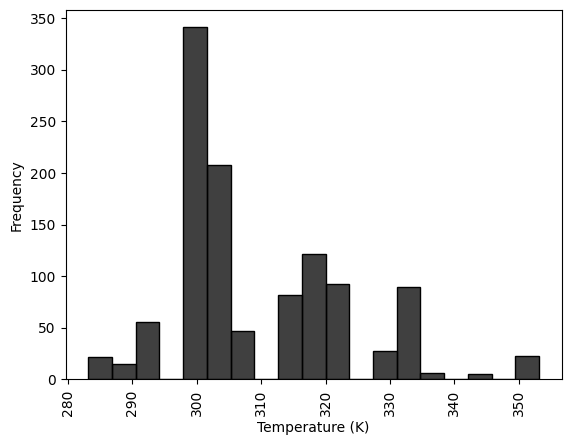

In [10]:
sns.histplot(data = phi_data, x = 'Temperature (K)', color = 'black').set(ylabel = 'Frequency')
plt.xticks(rotation = 90)
plt.show()

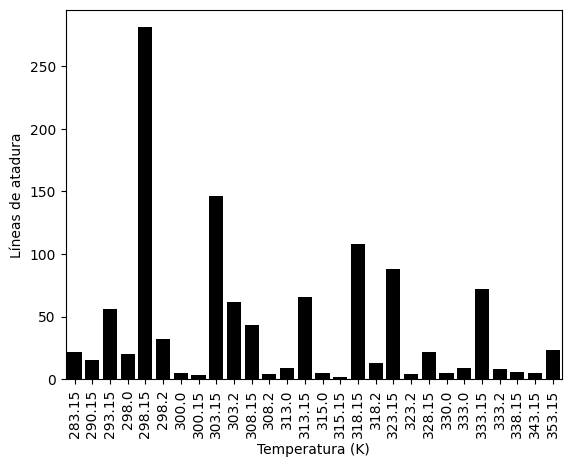

In [11]:
sns.barplot(data = temperature_tie_lines, x = 'Temperature (K)', y = 'len', color='black').set(ylabel='Líneas de atadura', xlabel='Temperatura (K)')
plt.xticks(rotation = 90)
plt.show()

In [12]:
tie_lines_per_alcohol = phi_data.group_by('Type Alcohol').len().sort(by='Type Alcohol')
tie_lines_per_alcohol

Type Alcohol,len
i64,u32
0,46
1,380
2,691
3,5
4,12


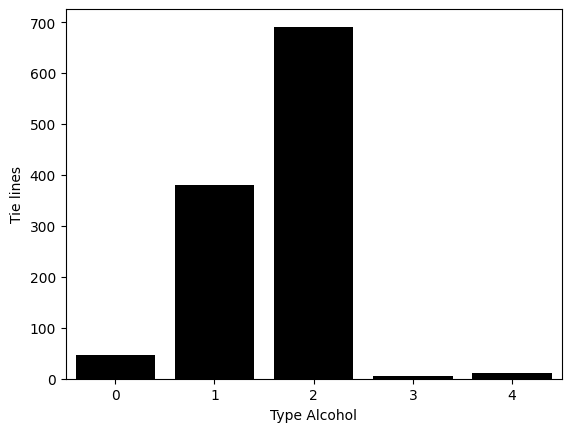

In [13]:
sns.barplot(data = tie_lines_per_alcohol, x = 'Type Alcohol', y = 'len', color='black').set(ylabel='Tie lines')
plt.show()

In [14]:
columns_to_select = ['phi_FAME/FAEE', 'phi_GLYCEROL', 'phi_ALCOHOL', 'phi_OIL', 'phi_DAG', 'phi_MAG', 'phi_ACID','phi_WATER']

In [15]:
def mean_excluding_zeros(row):
    non_zero_values = [val for val in row if val != 0]
    if not non_zero_values:
        return None  # or return float('nan') if you prefer NaN
    return sum(non_zero_values) / len(non_zero_values)
    
def absolute_errors(row, mean):
    return [abs(val - mean) if val != 0 else None for val in row]

def mean_non_null(values):
    non_null_values = [val for val in values if val is not None]
    if not non_null_values:
        return None  # or return float('nan') if you prefer NaN
    return sum(non_null_values) / len(non_null_values)

In [16]:
experimental_phi = phi_data.with_columns(
    pl.concat_list(columns_to_select).map_elements(mean_excluding_zeros, return_dtype= float).alias('Experimental mean phi')
)

df = experimental_phi.with_columns(
    pl.concat_list(columns_to_select).map_elements(
        lambda row: absolute_errors(row, mean_excluding_zeros(row)),
    return_dtype=list[float]).alias('abs_errors')
)

df = df.with_columns(
    df['abs_errors'].map_elements(mean_non_null, return_dtype=float).alias('average_absolute_error')
)


##### 2.2 Statistical analysis of the data

In [17]:
phi_data.describe()

statistic,index,Ref,Sub Ref,Temperature (K),Type Alcohol,FAME/FAEE_F,GLYCEROL_F,ALCOHOL_F,OIL_F,DAG_F,MAG_F,ACID_F,WATER_F,FAME/FAEE_L,GLYCEROL_L,ALCOHOL_L,OIL_L,DAG_L,MAG_L,ACID_L,WATER_L,FAME/FAEE_H,GLYCEROL_H,ALCOHOL_H,OIL_H,DAG_H,MAG_H,ACID_H,WATER_H,Reconcile phi,phi_FAME/FAEE,phi_GLYCEROL,phi_ALCOHOL,phi_OIL,phi_DAG,phi_MAG,phi_ACID,phi_WATER
str,f64,f64,str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""count""",1134.0,1134.0,"""1134""",1134.0,1134.0,1134.0,1134.0,1134.0,1134.0,1134.0,1134.0,1134.0,1134.0,1134.0,1134.0,1134.0,1134.0,1134.0,1134.0,1134.0,1134.0,1134.0,1134.0,1134.0,1134.0,1134.0,1134.0,1134.0,1134.0,1134.0,1134.0,1134.0,1134.0,1134.0,1134.0,1134.0,1134.0,1134.0
"""null_count""",0.0,0.0,"""0""",0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
"""mean""",566.5,31.878307,null,309.105203,1.609347,0.199485,0.148404,0.346987,0.220218,0.000683,0.000864,0.019264,0.064108,0.452862,0.007155,0.132847,0.376041,0.000796,0.000584,0.020479,0.01025,0.014076,0.254724,0.55037,0.044347,0.000538,0.001194,0.017999,0.116134,0.466491,0.22166,0.187481,0.435157,0.250888,NaN,0.01075,0.149743,0.211981
"""std""",327.501908,15.471958,null,14.219168,0.625962,0.20901,0.186103,0.160127,0.229754,0.005048,0.006757,0.042645,0.128603,0.443203,0.023227,0.145449,0.411869,0.005922,0.004775,0.046833,0.036499,0.042073,0.314169,0.290997,0.121021,0.004028,0.009163,0.039578,0.232617,0.117204,0.231701,0.230604,0.158007,0.260698,NaN,0.076625,0.235218,0.251304
"""min""",0.0,1.0,"""a""",283.15,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0000e-20,1.0000e-20,1.0000e-20,1.0000e-20,1.0000e-20,1.0000e-20,1.0000e-20,1.0000e-20,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.111857,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
"""25%""",283.0,20.0,null,298.15,1.0,0.0,0.0,0.219,0.0,0.0,0.0,0.0,0.0,1.0000e-20,1.0000e-20,0.057055,1.0000e-20,1.0000e-20,1.0000e-20,1.0000e-20,1.0000e-20,0.0,0.0,0.304225,0.0,0.0,0.0,0.0,0.0,0.410645,0.0,0.0,0.368573,0.0,0.0,0.0,0.0,0.0
"""50%""",567.0,34.0,null,303.15,2.0,0.2031,0.0,0.4024,0.0,0.0,0.0,0.0,0.0,0.653,1.0000e-20,0.096617,1.0000e-20,1.0000e-20,1.0000e-20,1.0000e-20,1.0000e-20,0.00001,0.0,0.60714,0.0,0.0,0.0,0.0,0.0,0.488027,0.223821,0.0,0.475174,0.0,0.0,0.0,0.0,0.0
"""75%""",850.0,46.0,null,318.15,2.0,0.3899,0.3275,0.4749,0.4693,0.0,0.0,0.0163,0.061,0.905043,0.007115,0.1632,0.826171,1.0000e-20,1.0000e-20,0.016204,0.004577,0.013485,0.539782,0.807624,0.027839,0.0,0.0,0.013529,0.115405,0.526961,0.427928,0.410072,0.523993,0.522852,0.0,0.0,0.473858,0.512161
"""max""",1133.0,57.0,"""i""",353.15,4.0,0.8459,0.7764,0.7004,0.6355,0.0586,0.0721,0.206,0.5564,1.036587,0.599996,0.941687,0.974168,0.068701,0.057142,0.260358,0.4084,0.455586,0.99999,0.9949,0.897099,0.048558,0.092427,0.206843,0.9999,0.99999,0.99999,0.99999,0.877073,0.724901,0.626346,0.626346,0.724901,0.843336


In [18]:
df.describe()

statistic,index,Ref,Sub Ref,Temperature (K),Type Alcohol,FAME/FAEE_F,GLYCEROL_F,ALCOHOL_F,OIL_F,DAG_F,MAG_F,ACID_F,WATER_F,FAME/FAEE_L,GLYCEROL_L,ALCOHOL_L,OIL_L,DAG_L,MAG_L,ACID_L,WATER_L,FAME/FAEE_H,GLYCEROL_H,ALCOHOL_H,OIL_H,DAG_H,MAG_H,ACID_H,WATER_H,Reconcile phi,phi_FAME/FAEE,phi_GLYCEROL,phi_ALCOHOL,phi_OIL,phi_DAG,phi_MAG,phi_ACID,phi_WATER,Experimental mean phi,abs_errors,average_absolute_error
str,f64,f64,str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""count""",1134.0,1134.0,"""1134""",1134.0,1134.0,1134.0,1134.0,1134.0,1134.0,1134.0,1134.0,1134.0,1134.0,1134.0,1134.0,1134.0,1134.0,1134.0,1134.0,1134.0,1134.0,1134.0,1134.0,1134.0,1134.0,1134.0,1134.0,1134.0,1134.0,1134.0,1134.0,1134.0,1134.0,1134.0,1134.0,1134.0,1134.0,1134.0,1134.0,1134.0,1134.0
"""null_count""",0.0,0.0,"""0""",0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
"""mean""",566.5,31.878307,null,309.105203,1.609347,0.199485,0.148404,0.346987,0.220218,0.000683,0.000864,0.019264,0.064108,0.452862,0.007155,0.132847,0.376041,0.000796,0.000584,0.020479,0.01025,0.014076,0.254724,0.55037,0.044347,0.000538,0.001194,0.017999,0.116134,0.466491,0.22166,0.187481,0.435157,0.250888,NaN,0.01075,0.149743,0.211981,NaN,null,NaN
"""std""",327.501908,15.471958,null,14.219168,0.625962,0.20901,0.186103,0.160127,0.229754,0.005048,0.006757,0.042645,0.128603,0.443203,0.023227,0.145449,0.411869,0.005922,0.004775,0.046833,0.036499,0.042073,0.314169,0.290997,0.121021,0.004028,0.009163,0.039578,0.232617,0.117204,0.231701,0.230604,0.158007,0.260698,NaN,0.076625,0.235218,0.251304,NaN,null,NaN
"""min""",0.0,1.0,"""a""",283.15,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0000e-20,1.0000e-20,1.0000e-20,1.0000e-20,1.0000e-20,1.0000e-20,1.0000e-20,1.0000e-20,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.111857,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.111857,null,0.0
"""25%""",283.0,20.0,null,298.15,1.0,0.0,0.0,0.219,0.0,0.0,0.0,0.0,0.0,1.0000e-20,1.0000e-20,0.057055,1.0000e-20,1.0000e-20,1.0000e-20,1.0000e-20,1.0000e-20,0.0,0.0,0.304225,0.0,0.0,0.0,0.0,0.0,0.410645,0.0,0.0,0.368573,0.0,0.0,0.0,0.0,0.0,0.410645,null,3.7007e-17
"""50%""",567.0,34.0,null,303.15,2.0,0.2031,0.0,0.4024,0.0,0.0,0.0,0.0,0.0,0.653,1.0000e-20,0.096617,1.0000e-20,1.0000e-20,1.0000e-20,1.0000e-20,1.0000e-20,0.00001,0.0,0.60714,0.0,0.0,0.0,0.0,0.0,0.488027,0.223821,0.0,0.475174,0.0,0.0,0.0,0.0,0.0,0.488027,null,5.5511e-17
"""75%""",850.0,46.0,null,318.15,2.0,0.3899,0.3275,0.4749,0.4693,0.0,0.0,0.0163,0.061,0.905043,0.007115,0.1632,0.826171,1.0000e-20,1.0000e-20,0.016204,0.004577,0.013485,0.539782,0.807624,0.027839,0.0,0.0,0.013529,0.115405,0.526961,0.427928,0.410072,0.523993,0.522852,0.0,0.0,0.473858,0.512161,0.526961,null,1.1102e-16
"""max""",1133.0,57.0,"""i""",353.15,4.0,0.8459,0.7764,0.7004,0.6355,0.0586,0.0721,0.206,0.5564,1.036587,0.599996,0.941687,0.974168,0.068701,0.057142,0.260358,0.4084,0.455586,0.99999,0.9949,0.897099,0.048558,0.092427,0.206843,0.9999,0.99999,0.99999,0.99999,0.877073,0.724901,0.626346,0.626346,0.724901,0.843336,0.99999,null,5.9212e-15


In [19]:
df.filter((pl.col('Experimental mean phi') > 1) | (pl.col('Experimental mean phi') < 0))

index,Ref,Sub Ref,Temperature (K),Type Alcohol,FAME/FAEE_F,GLYCEROL_F,ALCOHOL_F,OIL_F,DAG_F,MAG_F,ACID_F,WATER_F,FAME/FAEE_L,GLYCEROL_L,ALCOHOL_L,OIL_L,DAG_L,MAG_L,ACID_L,WATER_L,FAME/FAEE_H,GLYCEROL_H,ALCOHOL_H,OIL_H,DAG_H,MAG_H,ACID_H,WATER_H,Reconcile phi,phi_FAME/FAEE,phi_GLYCEROL,phi_ALCOHOL,phi_OIL,phi_DAG,phi_MAG,phi_ACID,phi_WATER,Experimental mean phi,abs_errors,average_absolute_error
u32,i64,str,f64,i64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,list[f64],f64
1064,55,"""ba""",318.2,2,0.0,0.0,0.4704,0.5208,0.0088,0.0,0.0,0.0,1.0000e-20,1.0000e-20,0.177716,0.813416,0.0088,1.0000e-20,1.0000e-20,1.0000e-20,0.0,0.0,0.8999,0.0914,0.0088,0.0,0.0,0.0,0.594724,0.0,0.0,0.594724,0.594724,NaN,0.0,0.0,0.0,NaN,"[null, null, … null]",NaN


In [20]:
filtered_phi_df = df.filter((pl.col('Experimental mean phi') <=1) & (pl.col('Experimental mean phi') > 0))
filtered_phi_df.describe()

statistic,index,Ref,Sub Ref,Temperature (K),Type Alcohol,FAME/FAEE_F,GLYCEROL_F,ALCOHOL_F,OIL_F,DAG_F,MAG_F,ACID_F,WATER_F,FAME/FAEE_L,GLYCEROL_L,ALCOHOL_L,OIL_L,DAG_L,MAG_L,ACID_L,WATER_L,FAME/FAEE_H,GLYCEROL_H,ALCOHOL_H,OIL_H,DAG_H,MAG_H,ACID_H,WATER_H,Reconcile phi,phi_FAME/FAEE,phi_GLYCEROL,phi_ALCOHOL,phi_OIL,phi_DAG,phi_MAG,phi_ACID,phi_WATER,Experimental mean phi,abs_errors,average_absolute_error
str,f64,f64,str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""count""",1133.0,1133.0,"""1133""",1133.0,1133.0,1133.0,1133.0,1133.0,1133.0,1133.0,1133.0,1133.0,1133.0,1133.0,1133.0,1133.0,1133.0,1133.0,1133.0,1133.0,1133.0,1133.0,1133.0,1133.0,1133.0,1133.0,1133.0,1133.0,1133.0,1133.0,1133.0,1133.0,1133.0,1133.0,1133.0,1133.0,1133.0,1133.0,1133.0,1133.0,1133.0
"""null_count""",0.0,0.0,"""0""",0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
"""mean""",566.0609,31.857899,null,309.097176,1.609003,0.199661,0.148535,0.346878,0.219953,0.000675,0.000865,0.019281,0.064164,0.453261,0.007161,0.132807,0.375655,0.000789,0.000585,0.020497,0.010259,0.014088,0.254949,0.550062,0.044306,0.00053,0.001195,0.018015,0.116237,0.466378,0.221856,0.187647,0.435016,0.250584,0.015141,0.01076,0.149875,0.212168,0.466378,null,1.3099e-16
"""std""",327.312408,15.463513,null,14.222877,0.62613,0.209018,0.186133,0.160155,0.229681,0.005045,0.00676,0.04266,0.128646,0.443194,0.023237,0.145507,0.411846,0.00592,0.004777,0.04685,0.036514,0.04209,0.314217,0.290939,0.121066,0.004022,0.009167,0.039592,0.232694,0.117194,0.23171,0.230638,0.158005,0.260612,0.090555,0.076658,0.23528,0.251336,0.117194,null,3.1689e-16
"""min""",0.0,1.0,"""a""",283.15,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0000e-20,1.0000e-20,1.0000e-20,1.0000e-20,1.0000e-20,1.0000e-20,1.0000e-20,1.0000e-20,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.111857,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.111857,null,0.0
"""25%""",283.0,20.0,null,298.15,1.0,0.0,0.0,0.219,0.0,0.0,0.0,0.0,0.0,1.0000e-20,1.0000e-20,0.057055,1.0000e-20,1.0000e-20,1.0000e-20,1.0000e-20,1.0000e-20,0.0,0.0,0.304225,0.0,0.0,0.0,0.0,0.0,0.410645,0.0,0.0,0.368573,0.0,0.0,0.0,0.0,0.0,0.410645,null,3.7007e-17
"""50%""",566.0,33.0,null,303.15,2.0,0.2031,0.0,0.4019,0.0,0.0,0.0,0.0,0.0,0.653,1.0000e-20,0.096072,1.0000e-20,1.0000e-20,1.0000e-20,1.0000e-20,1.0000e-20,0.00001,0.0,0.607075,0.0,0.0,0.0,0.0,0.0,0.48792,0.223821,0.0,0.474999,0.0,0.0,0.0,0.0,0.0,0.48792,null,5.5511e-17
"""75%""",849.0,46.0,null,318.15,2.0,0.3899,0.3275,0.4749,0.4692,0.0,0.0,0.0163,0.061,0.905043,0.007115,0.162412,0.826171,1.0000e-20,1.0000e-20,0.016204,0.004577,0.013485,0.539782,0.806009,0.026683,0.0,0.0,0.013529,0.115405,0.526921,0.427928,0.410072,0.523983,0.522724,0.0,0.0,0.473858,0.512161,0.526921,null,1.1102e-16
"""max""",1133.0,57.0,"""i""",353.15,4.0,0.8459,0.7764,0.7004,0.6355,0.0586,0.0721,0.206,0.5564,1.036587,0.599996,0.941687,0.974168,0.068701,0.057142,0.260358,0.4084,0.455586,0.99999,0.9949,0.897099,0.048558,0.092427,0.206843,0.9999,0.99999,0.99999,0.99999,0.877073,0.724901,0.626346,0.626346,0.724901,0.843336,0.99999,null,5.9212e-15


##### 2.3 Distribution of experimental PHI for each component

<>:26: SyntaxWarning: invalid escape sequence '\p'
<>:26: SyntaxWarning: invalid escape sequence '\p'
C:\Users\RPC\AppData\Local\Temp\ipykernel_33504\2559397901.py:26: SyntaxWarning: invalid escape sequence '\p'
  ax.set_xlabel('$\phi$ experimental', fontsize=18)


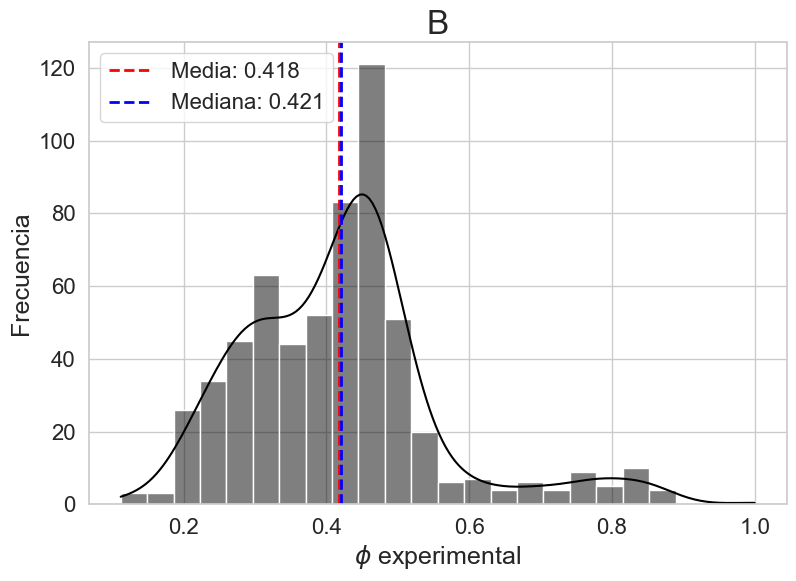

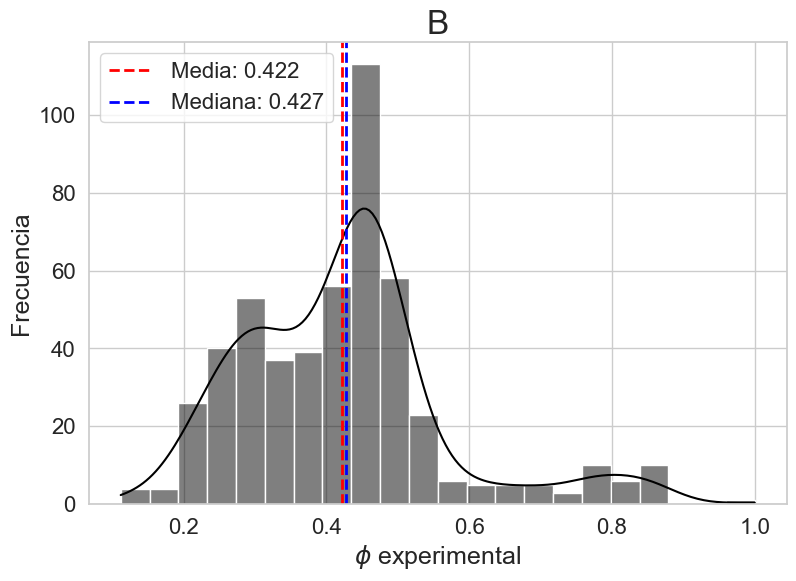

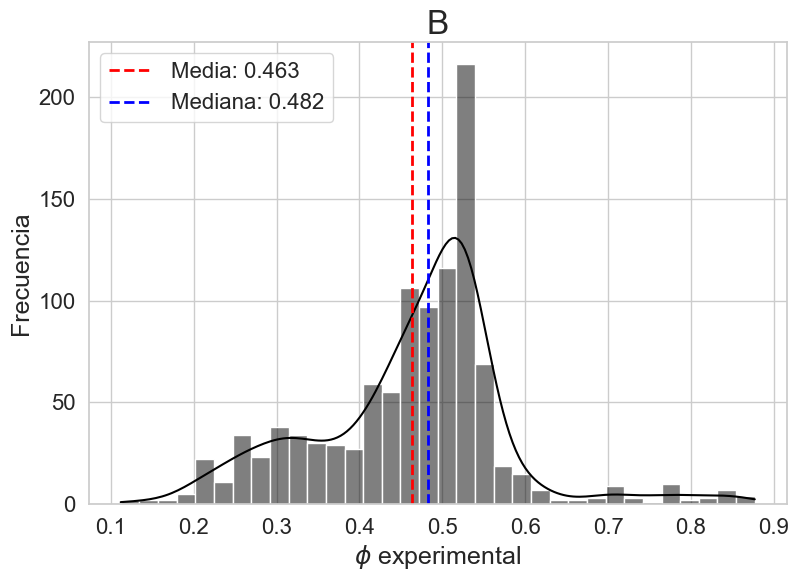

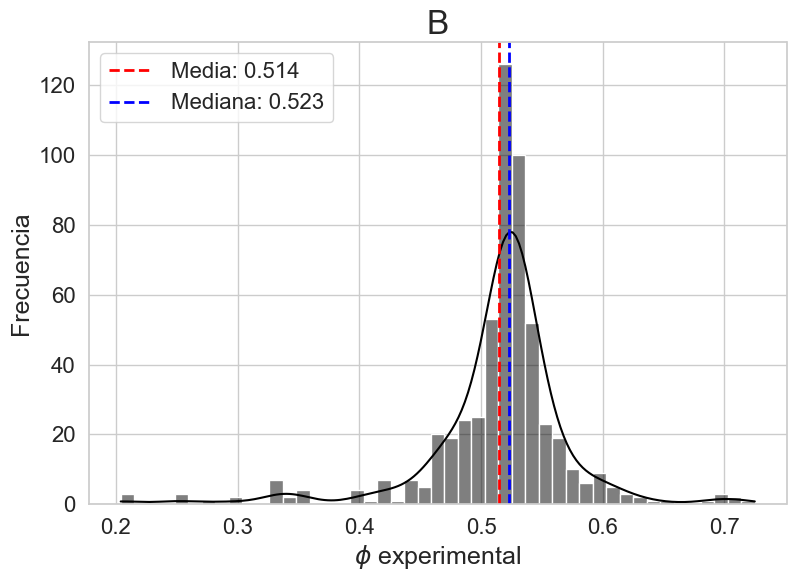

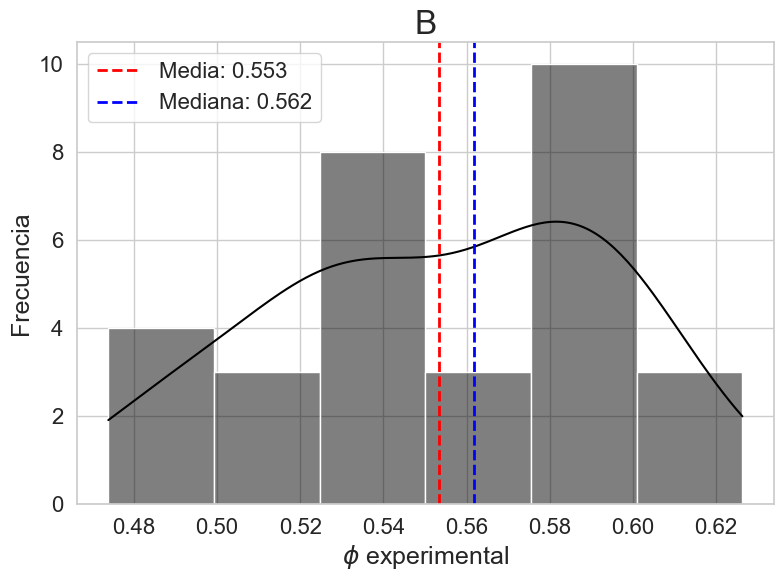

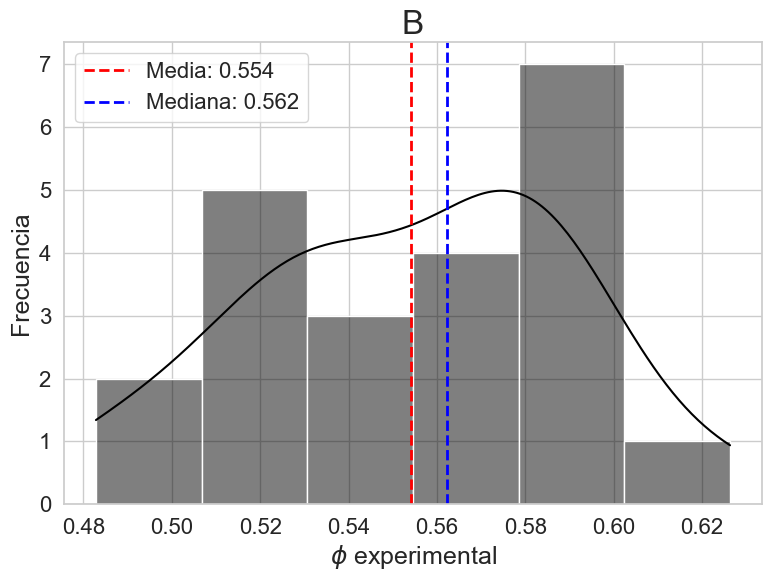

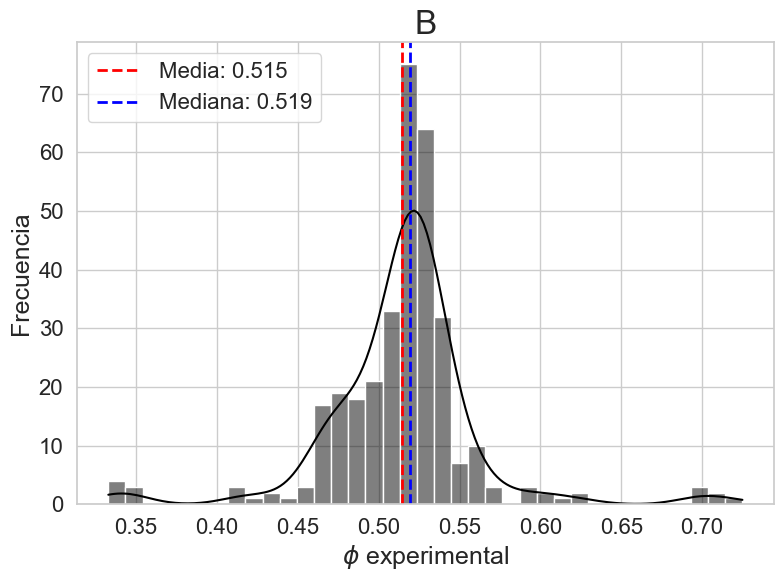

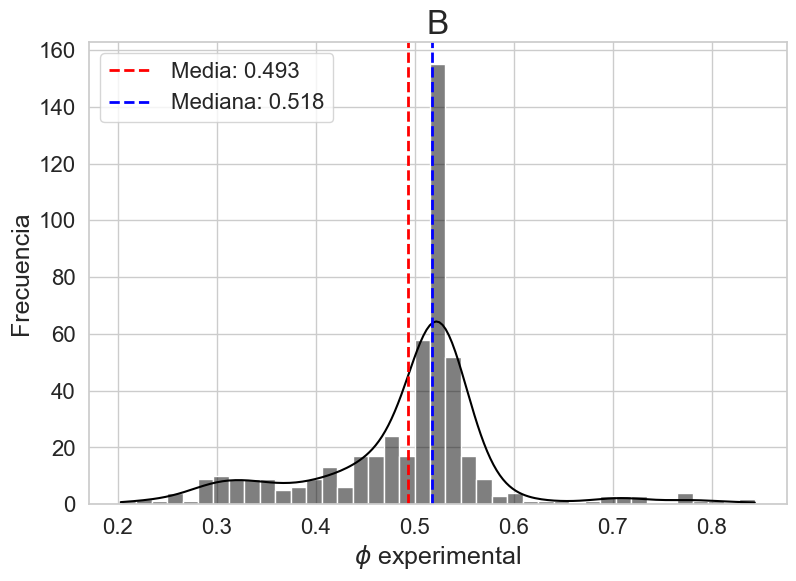

In [21]:
sns.set_theme(rc={
    'figure.figsize': (9, 6),
    'font.size': 14,
    'axes.titlesize': 20,
    'axes.labelsize': 16,
    'xtick.labelsize': 14,
    'ytick.labelsize': 14,
    'legend.fontsize': 14
})
sns.set_style("whitegrid")

feed_columns = ['FAME/FAEE_F', 'GLYCEROL_F', 'ALCOHOL_F', 'OIL_F', 'DAG_F', 'MAG_F', 'ACID_F', 'WATER_F']

for i in feed_columns:
    plt.figure()
    filter_data = filtered_phi_df.filter(pl.col(i) > 0.0)
    len_data = filter_data.shape[0]
    column_name = 'phi_' + i.rstrip('_F')
    mean_value = filter_data.select(pl.col(column_name)).mean().to_numpy()[0][0]
    median_value = filter_data.select(pl.col(column_name)).median().to_numpy()[0][0]
    
    ax = sns.histplot(x=filter_data.select(pl.col(column_name)).to_numpy().reshape(len_data), 
                      color='black', kde=True)
    ax.set_title("B", fontsize=24)
    ax.set_ylabel('Frecuencia', fontsize=18)
    ax.set_xlabel('$\phi$ experimental', fontsize=18)
    
    plt.axvline(mean_value, color='red', linestyle='--', linewidth=2,
                label=f'Media: {round(mean_value, 3)}')
    plt.axvline(median_value, color='blue', linestyle='--', linewidth=2,
                label=f'Mediana: {round(median_value, 3)}')
    
    plt.legend(loc='upper left', fontsize=16)
    plt.tick_params(axis='both', which='major', labelsize=16)
    
    # Save at 1000 DPI
    # Replace the forward slash in 'FAME/FAEE' with underscore
    safe_filename = i.rstrip('_F').replace('/', '_')
    plt.savefig(f'phi_distribution_{safe_filename}.png', 
            dpi=1000, 
            bbox_inches='tight', 
            facecolor='white',
            edgecolor='none')
    
    plt.show()

<>:12: SyntaxWarning: invalid escape sequence '\p'
<>:12: SyntaxWarning: invalid escape sequence '\p'
C:\Users\RPC\AppData\Local\Temp\ipykernel_33504\3837539515.py:12: SyntaxWarning: invalid escape sequence '\p'
  sns.histplot(x = filter_data.select(pl.col(column_name)).to_numpy().reshape(len_data), color = 'black', kde=True).set(title=f"A", ylabel = 'Frecuencia', xlabel = '$\phi$ experimental')


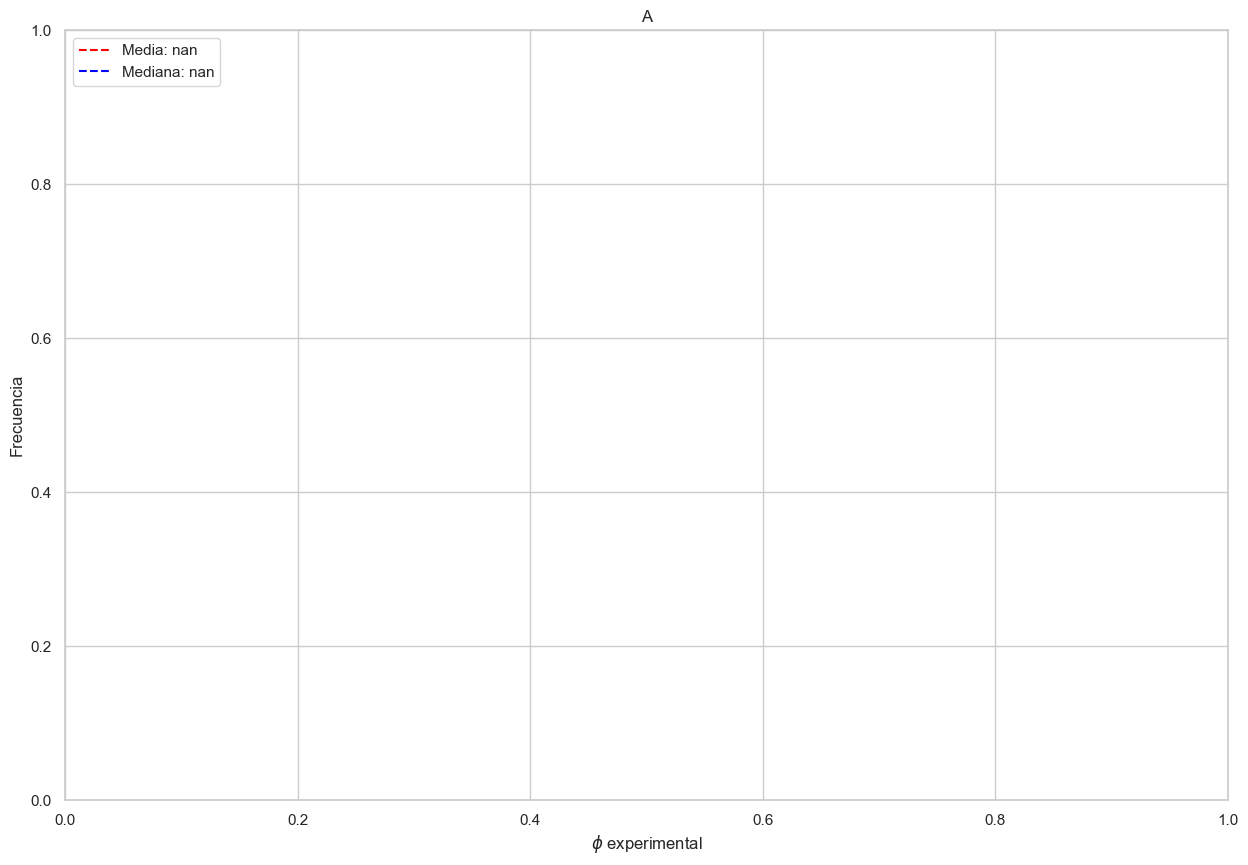

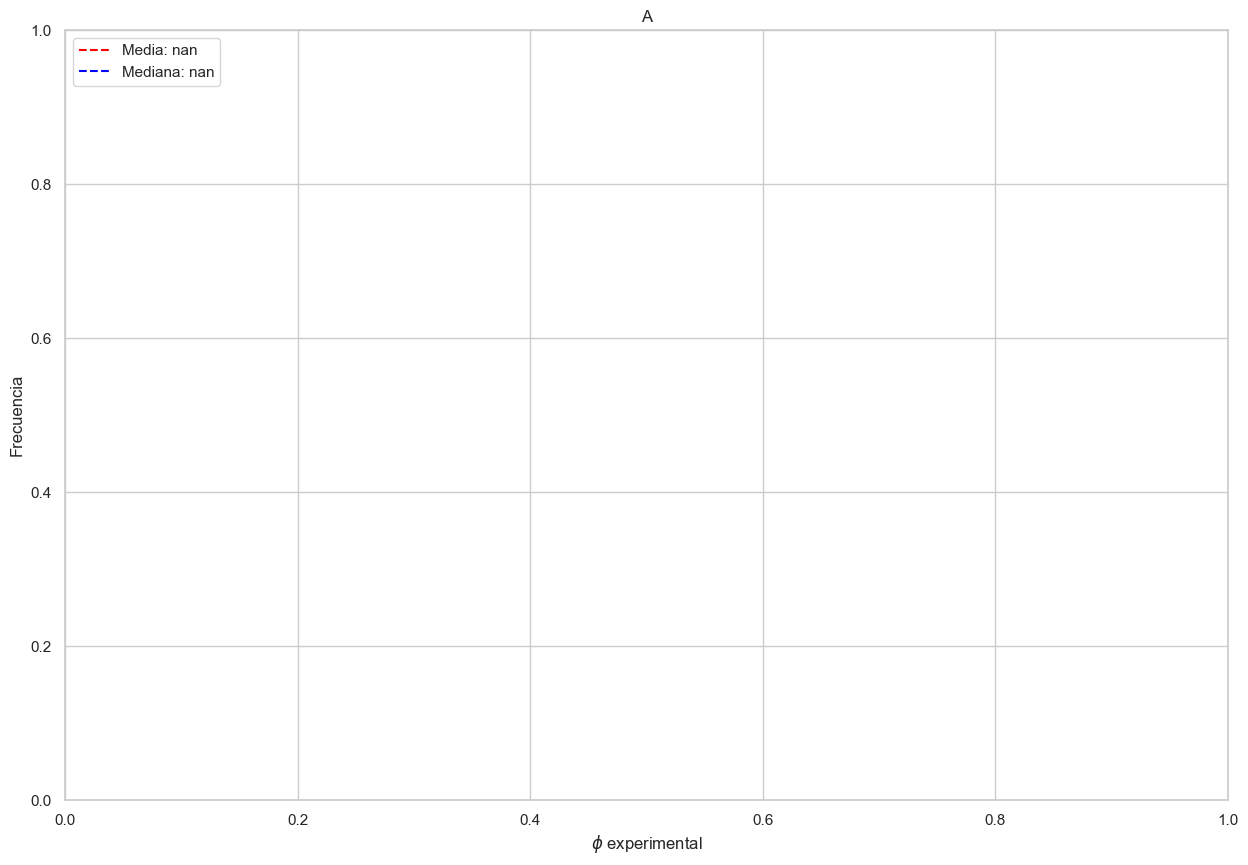

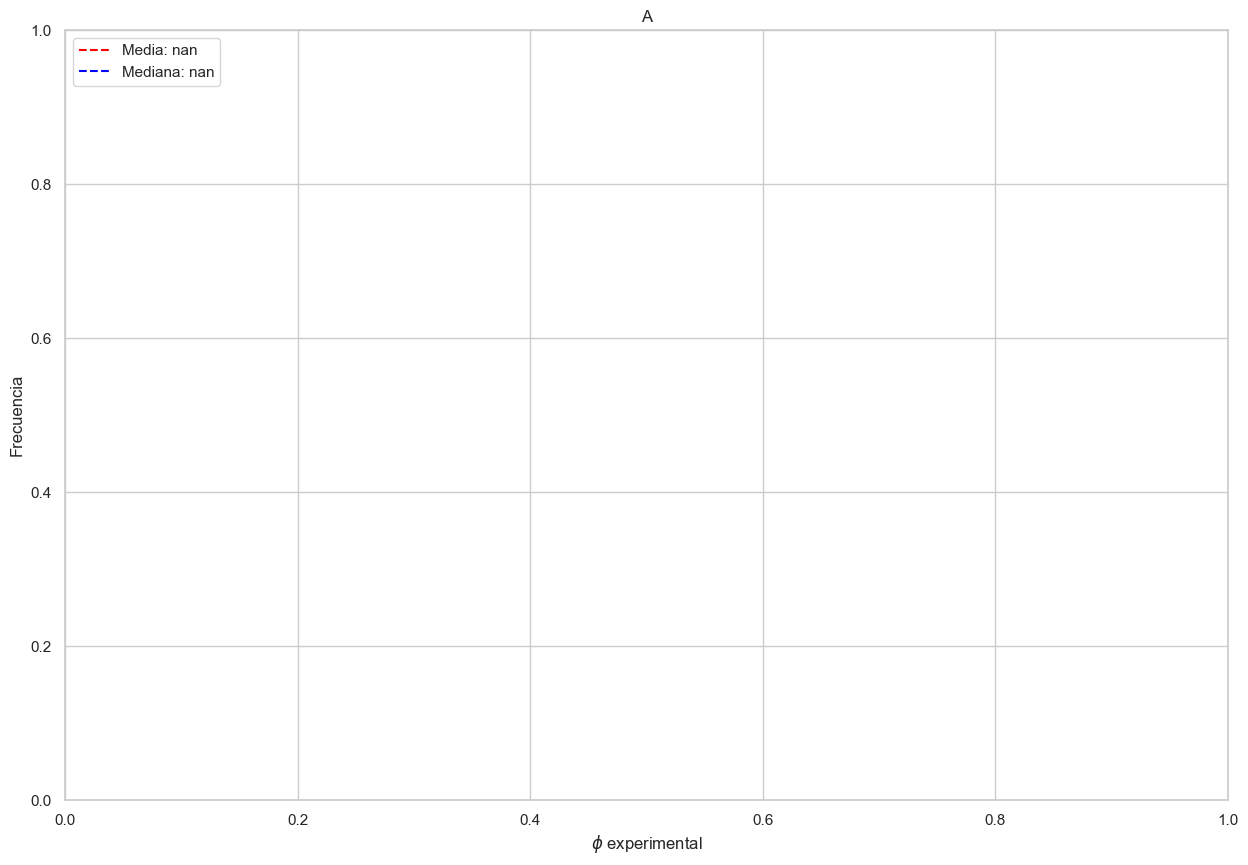

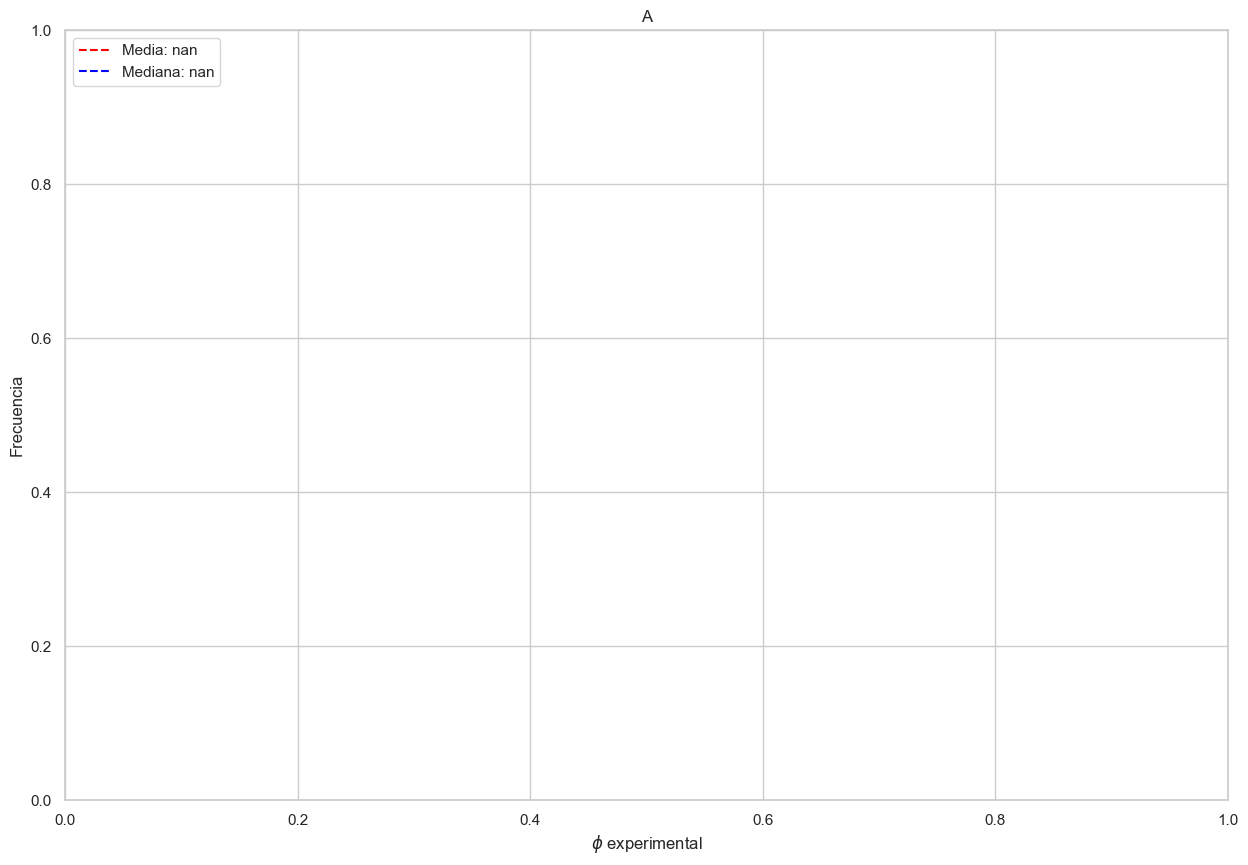

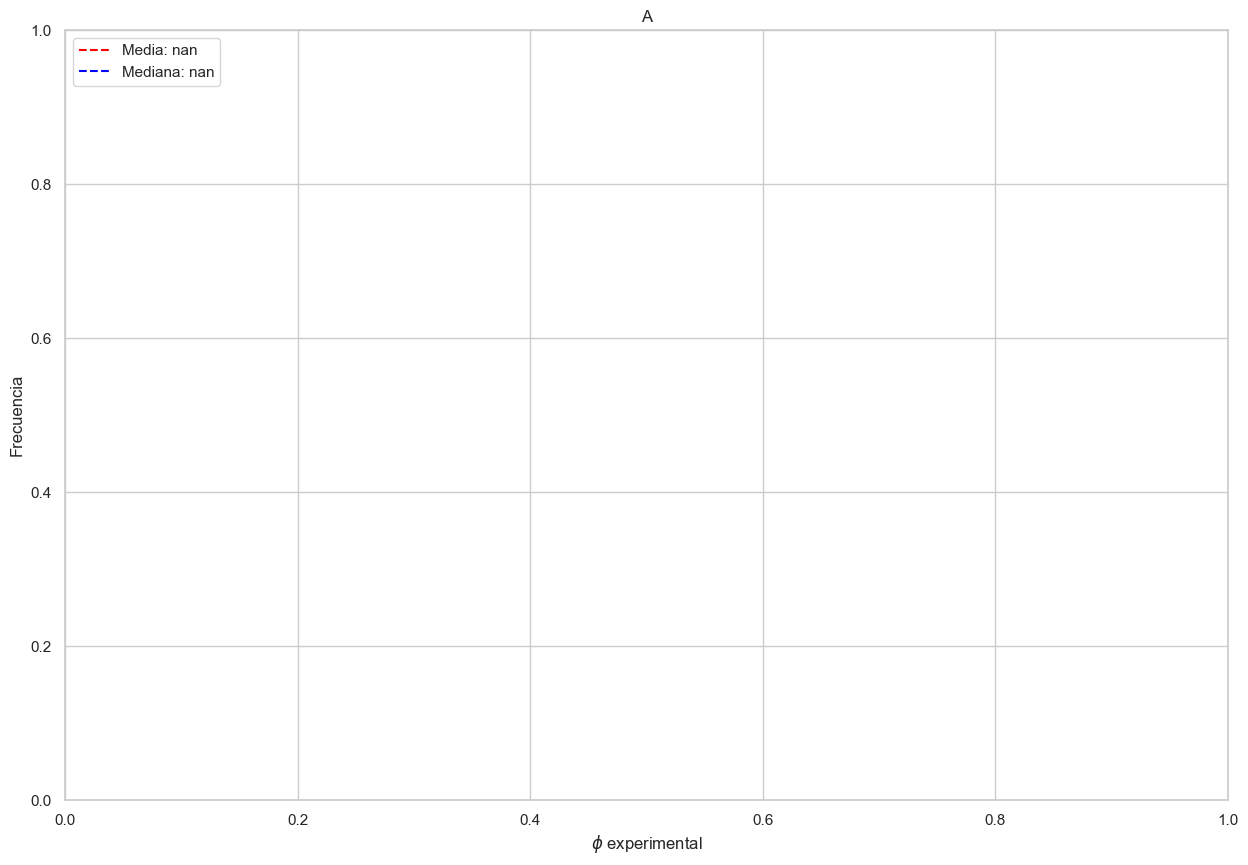

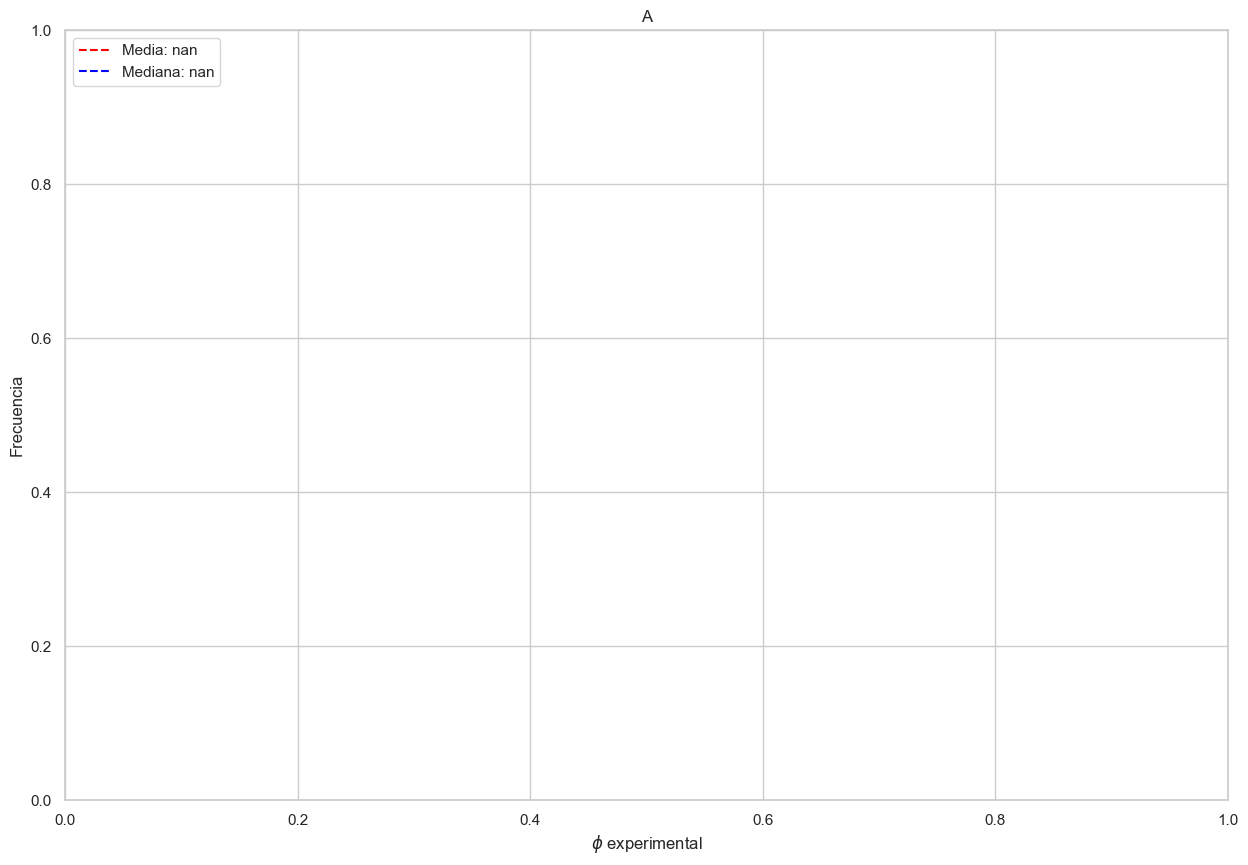

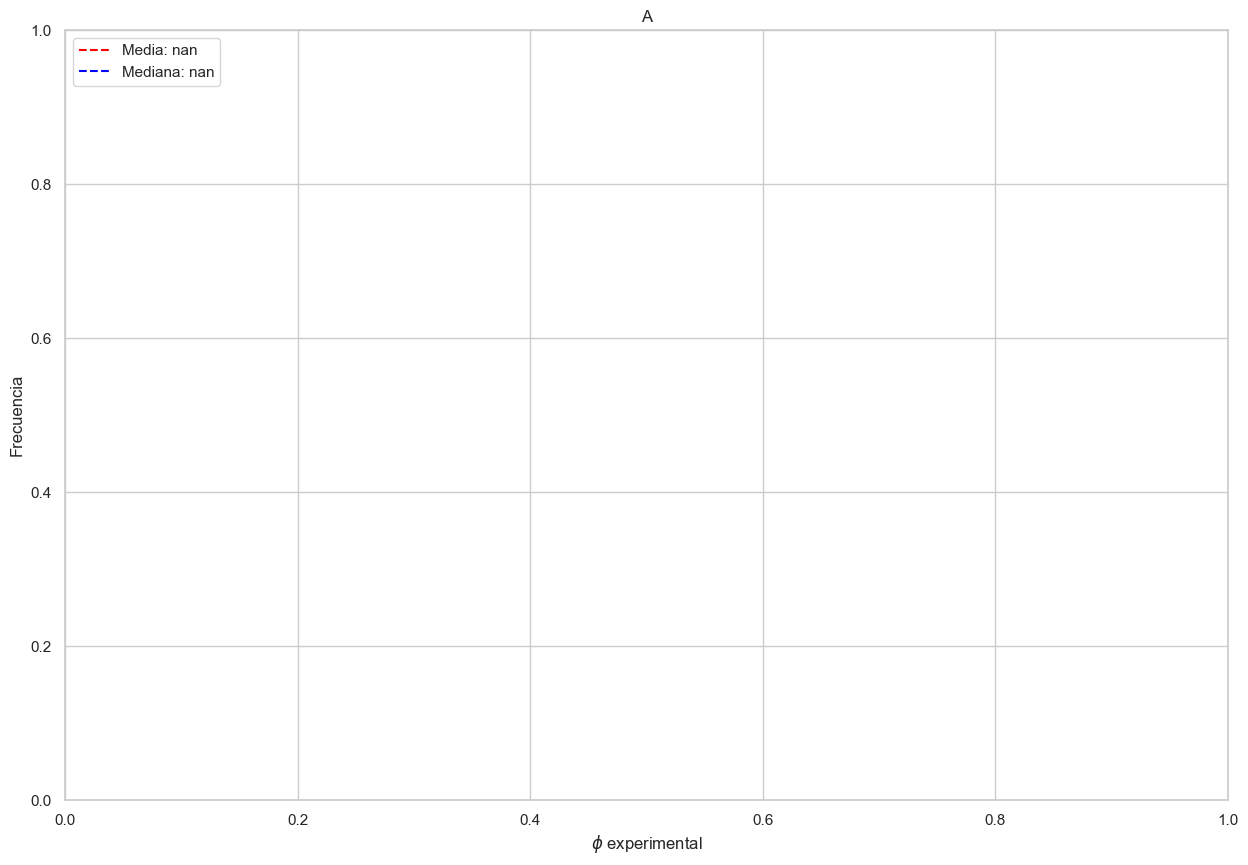

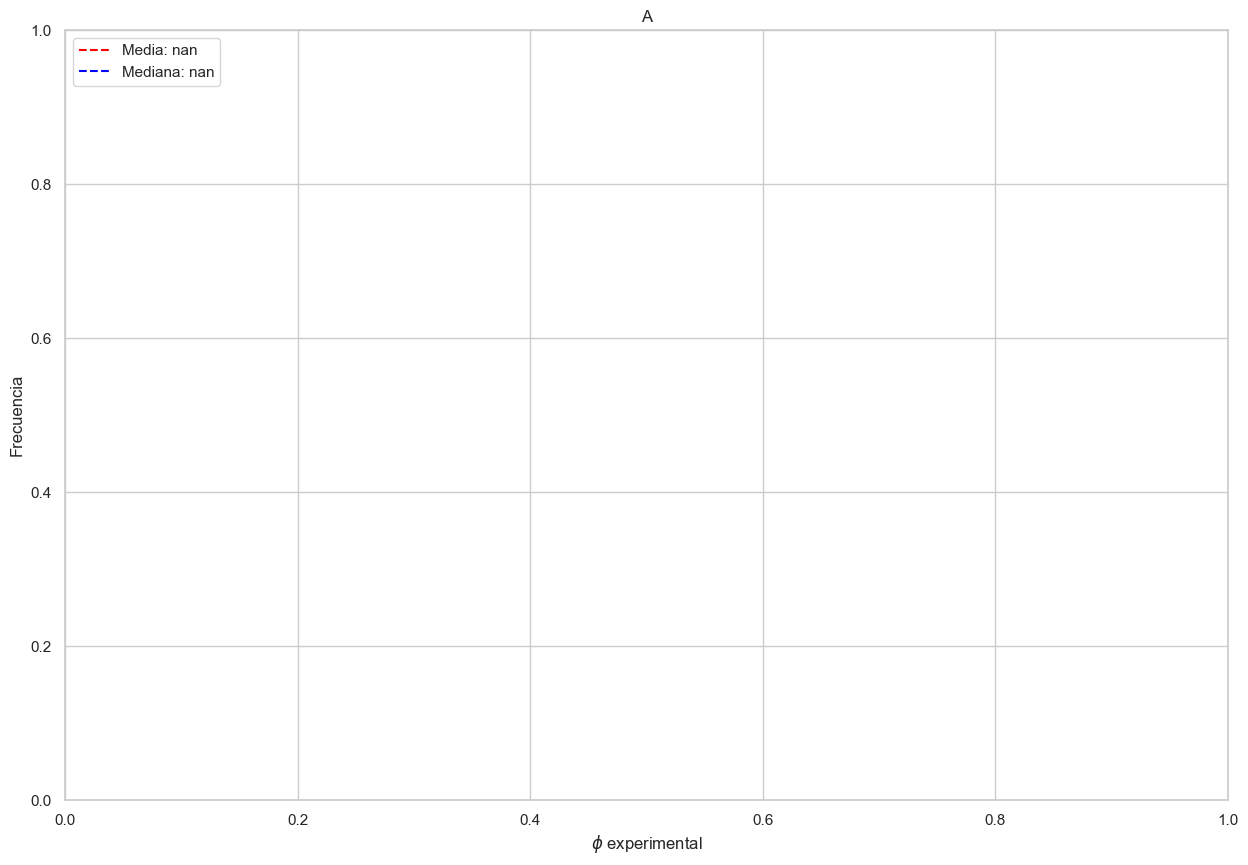

In [22]:
sns.set_theme(rc={'figure.figsize':(15, 10)})
sns.set_style("whitegrid")

feed_columns = ['FAME/FAEE_F', 'GLYCEROL_F', 'ALCOHOL_F', 'OIL_F', 'DAG_F', 'MAG_F', 'ACID_F', 'WATER_F']
for i in feed_columns:
    plt.figure()
    filter_data = filtered_phi_df.filter(pl.col(i) < 0.0)
    len_data = filter_data.shape[0]
    column_name = 'phi_' + i.rstrip('_F')
    mean_value = filter_data.select(pl.col(column_name)).mean().to_numpy()[0][0]
    median_value = filter_data.select(pl.col(column_name)).median().to_numpy()[0][0]
    sns.histplot(x = filter_data.select(pl.col(column_name)).to_numpy().reshape(len_data), color = 'black', kde=True).set(title=f"A", ylabel = 'Frecuencia', xlabel = '$\phi$ experimental')
    plt.axvline(mean_value, color = 'red', linestyle = '--',  label = f'Media: {round(mean_value, 3)}')
    plt.axvline(median_value, color = 'blue', linestyle = '--', label = f'Mediana: {round(median_value, 3)}')
    plt.legend(loc= 'upper left')
    plt.show()
#    $\phi$ {i.rstrip('_F')}


##### 2.4 Distribution of mean experimental phi per tie line

In [23]:
mean_value = filtered_phi_df.select(pl.col('Experimental mean phi')).mean().to_numpy()[0][0]
median_value = filtered_phi_df.select(pl.col('Experimental mean phi')).median().to_numpy()[0][0]
sns.histplot(x = filtered_phi_df.select(pl.col('Experimental mean phi')).to_numpy().reshape(1413), kde = True, color='black').set(title = f'Average Experimental $\phi$ per tie line',  ylabel = 'Frequency', xlabel = 'Average experimental $\phi$')
plt.axvline(mean_value, color = 'red', linestyle = '--', label = f'Mean value: {round(mean_value, 3)}')
plt.axvline(median_value, color = 'blue', linestyle = '--', label = f'Median value: {round(median_value, 3)}')
plt.legend()
plt.show()

<>:3: SyntaxWarning: invalid escape sequence '\p'
<>:3: SyntaxWarning: invalid escape sequence '\p'
<>:3: SyntaxWarning: invalid escape sequence '\p'
<>:3: SyntaxWarning: invalid escape sequence '\p'
C:\Users\RPC\AppData\Local\Temp\ipykernel_33504\1872565878.py:3: SyntaxWarning: invalid escape sequence '\p'
  sns.histplot(x = filtered_phi_df.select(pl.col('Experimental mean phi')).to_numpy().reshape(1413), kde = True, color='black').set(title = f'Average Experimental $\phi$ per tie line',  ylabel = 'Frequency', xlabel = 'Average experimental $\phi$')
C:\Users\RPC\AppData\Local\Temp\ipykernel_33504\1872565878.py:3: SyntaxWarning: invalid escape sequence '\p'
  sns.histplot(x = filtered_phi_df.select(pl.col('Experimental mean phi')).to_numpy().reshape(1413), kde = True, color='black').set(title = f'Average Experimental $\phi$ per tie line',  ylabel = 'Frequency', xlabel = 'Average experimental $\phi$')
C:\Users\RPC\AppData\Local\Temp\ipykernel_33504\1872565878.py:3: SyntaxWarning: invali

ValueError: cannot reshape array of size 1133 into shape (1413,)

##### 2.5 Distribution of average absolute error between the tie line experimental mean phi and each component phi 

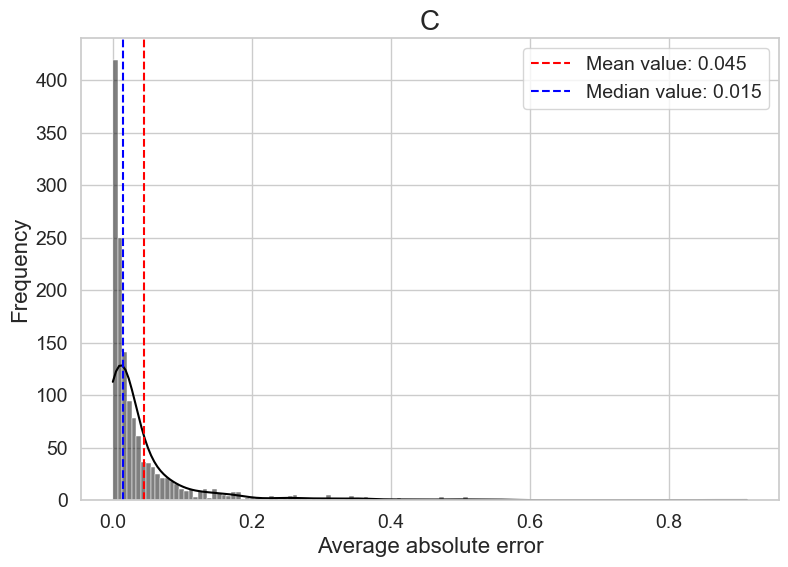

In [141]:
mean_value = filtered_phi_df.select(pl.col('average_absolute_error')).mean().to_numpy()[0][0]
median_value = filtered_phi_df.select(pl.col('average_absolute_error')).median().to_numpy()[0][0]
sns.histplot(x = filtered_phi_df.select(pl.col('average_absolute_error')).to_numpy().reshape(1413), kde = True, color='black').set(title = f'',  ylabel = 'Frequency', xlabel = 'Average absolute error')
plt.axvline(mean_value, color = 'red', linestyle = '--', label = f'Mean value: {round(mean_value, 3)}')
plt.axvline(median_value, color = 'blue', linestyle = '--', label = f'Median value: {round(median_value, 3)}')
plt.legend()
plt.title("C")
plt.savefig("Figure_1C.png", 
            dpi=1000, 
            bbox_inches='tight', 
            facecolor='white',
            edgecolor='none')
    
plt.show()

### 3.Analysis of refined data

In [68]:
thresholds = [0.05, 0.1, 0.15, 0.20, 0.25, 0.30, 0.35, 0.40, 0.45, 0.5, 0.55, 0.65, 0.70, 0.75]
lengths = []
for i in thresholds:
    validated_data, phi_names = ExperimentalValidation(path_to_data=r'C:\Juan\maestria\ThermOleo\ExperimentalData\data\raw_lle_data.xlsx', 
                                            component_list=['FAME/FAEE', 'GLYCEROL', 'ALCOHOL', 'OIL', 'DAG', 'MAG', 'ACID', 'WATER'], 
                                            column_list_to_remove=['Ref', 'Sub Ref', 'Temperature (K)', 'Type Alcohol'],
                                            error_threshold=i).validate_data()
    lengths.append(validated_data.shape[0])
    
    

Could not determine dtype for column 28, falling back to string
Could not determine dtype for column 29, falling back to string
Could not determine dtype for column 30, falling back to string
Could not determine dtype for column 31, falling back to string
Could not determine dtype for column 32, falling back to string
Could not determine dtype for column 33, falling back to string
Could not determine dtype for column 34, falling back to string
Could not determine dtype for column 35, falling back to string
Could not determine dtype for column 36, falling back to string
Could not determine dtype for column 37, falling back to string
Could not determine dtype for column 38, falling back to string
Could not determine dtype for column 39, falling back to string
Could not determine dtype for column 40, falling back to string
Could not determine dtype for column 41, falling back to string
Could not determine dtype for column 42, falling back to string
Could not determine dtype for column 43,

##### 3.1 Effect of error threshold on filtered data

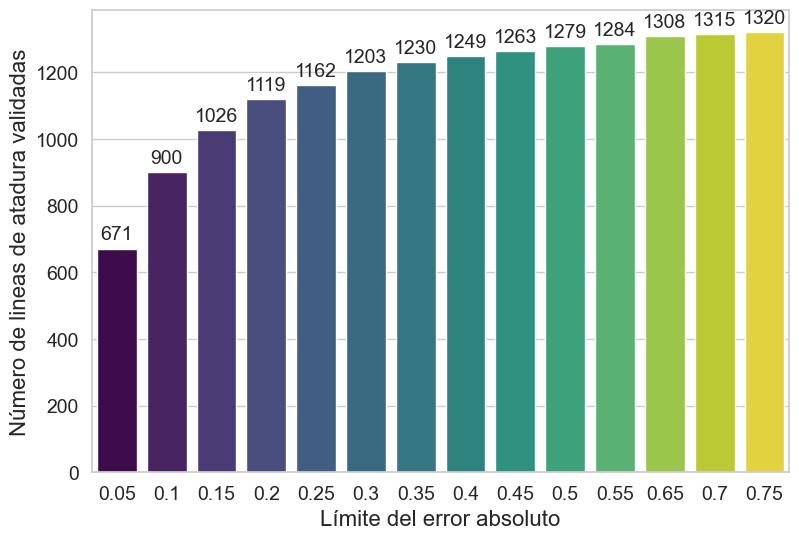

In [71]:
plt.figure(figsize=(9, 6))
ax = sns.barplot(x=thresholds, y=lengths, palette='viridis', hue=thresholds, legend=False)

# Annotate the bars with the values
for p in ax.patches:
    ax.annotate(f'{p.get_height():.0f}', 
                (p.get_x() + p.get_width() / 2., p.get_height()), 
                ha='center', va='center', 
                xytext=(0, 10), 
                textcoords='offset points')

# Set labels and title
ax.set_xlabel('Límite del error absoluto')
ax.set_ylabel('Número de lineas de atadura validadas')

plt.savefig("Figure_2.png", 
            dpi=1000, 
            bbox_inches='tight', 
            facecolor='white',
            edgecolor='none')
# Show the plot
plt.show()

##### 3.2 Statistical analysis of reconciled data and distribution of reconciled phi

In [72]:

refined_data = (pl.read_excel('data/refined_lle_data.xlsx', engine='calamine')).with_row_index()

In [73]:
refined_data.describe()

statistic,index,Ref,Sub Ref,Temperature (K),Type Alcohol,FAME/FAEE_F,GLYCEROL_F,ALCOHOL_F,OIL_F,DAG_F,MAG_F,ACID_F,WATER_F,FAME/FAEE_L,GLYCEROL_L,ALCOHOL_L,OIL_L,DAG_L,MAG_L,ACID_L,WATER_L,FAME/FAEE_H,GLYCEROL_H,ALCOHOL_H,OIL_H,DAG_H,MAG_H,ACID_H,WATER_H,Reconcile phi
str,f64,f64,str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""count""",1134.0,1134.0,"""1134""",1134.0,1134.0,1134.0,1134.0,1134.0,1134.0,1134.0,1134.0,1134.0,1134.0,1134.0,1134.0,1134.0,1134.0,1134.0,1134.0,1134.0,1134.0,1134.0,1134.0,1134.0,1134.0,1134.0,1134.0,1134.0,1134.0,1134.0
"""null_count""",0.0,0.0,"""0""",0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
"""mean""",566.5,31.878307,null,309.105203,1.609347,0.199485,0.148404,0.346987,0.220218,0.000683,0.000864,0.019264,0.064108,0.452862,0.007155,0.132847,0.376041,0.000796,0.000584,0.020479,0.01025,0.014076,0.254724,0.55037,0.044347,0.000538,0.001194,0.017999,0.116134,0.466491
"""std""",327.501908,15.471958,null,14.219168,0.625962,0.20901,0.186103,0.160127,0.229754,0.005048,0.006757,0.042645,0.128603,0.443203,0.023227,0.145449,0.411869,0.005922,0.004775,0.046833,0.036499,0.042073,0.314169,0.290997,0.121021,0.004028,0.009163,0.039578,0.232617,0.117204
"""min""",0.0,1.0,"""a""",283.15,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.111857
"""25%""",283.0,20.0,null,298.15,1.0,0.0,0.0,0.219,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.057055,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.304225,0.0,0.0,0.0,0.0,0.0,0.410645
"""50%""",567.0,34.0,null,303.15,2.0,0.2031,0.0,0.4024,0.0,0.0,0.0,0.0,0.0,0.653,0.0,0.096617,0.0,0.0,0.0,0.0,0.0,0.00001,0.0,0.60714,0.0,0.0,0.0,0.0,0.0,0.488027
"""75%""",850.0,46.0,null,318.15,2.0,0.3899,0.3275,0.4749,0.4693,0.0,0.0,0.0163,0.061,0.905043,0.007115,0.1632,0.826171,0.0,0.0,0.016204,0.004577,0.013485,0.539782,0.807624,0.027839,0.0,0.0,0.013529,0.115405,0.526961
"""max""",1133.0,57.0,"""i""",353.15,4.0,0.8459,0.7764,0.7004,0.6355,0.0586,0.0721,0.206,0.5564,1.036587,0.599996,0.941687,0.974168,0.068701,0.057142,0.260358,0.4084,0.455586,0.99999,0.9949,0.897099,0.048558,0.092427,0.206843,0.9999,0.99999


<>:3: SyntaxWarning: invalid escape sequence '\p'
<>:3: SyntaxWarning: invalid escape sequence '\p'
<>:3: SyntaxWarning: invalid escape sequence '\p'
<>:3: SyntaxWarning: invalid escape sequence '\p'
C:\Users\RPC\AppData\Local\Temp\ipykernel_37332\3194810045.py:3: SyntaxWarning: invalid escape sequence '\p'
  sns.histplot(x = refined_data.select(pl.col('Reconcile phi')).to_numpy().reshape(1134), kde = True, color='black').set(title = f'Reconcile $\phi$ per tie line',  ylabel = 'Frequency', xlabel = 'Reconcile $\phi$')
C:\Users\RPC\AppData\Local\Temp\ipykernel_37332\3194810045.py:3: SyntaxWarning: invalid escape sequence '\p'
  sns.histplot(x = refined_data.select(pl.col('Reconcile phi')).to_numpy().reshape(1134), kde = True, color='black').set(title = f'Reconcile $\phi$ per tie line',  ylabel = 'Frequency', xlabel = 'Reconcile $\phi$')


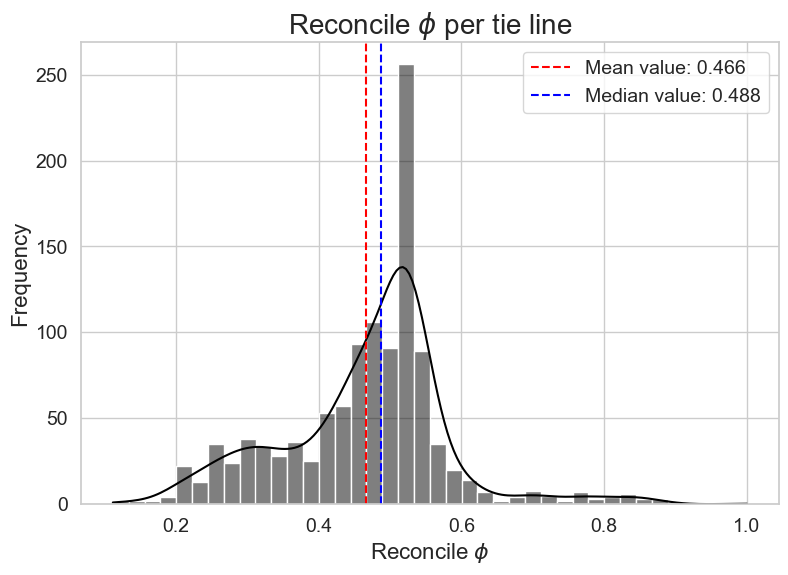

In [74]:
mean_value = refined_data.select(pl.col('Reconcile phi')).mean().to_numpy()[0][0]
median_value = refined_data.select(pl.col('Reconcile phi')).median().to_numpy()[0][0]
sns.histplot(x = refined_data.select(pl.col('Reconcile phi')).to_numpy().reshape(1134), kde = True, color='black').set(title = f'Reconcile $\phi$ per tie line',  ylabel = 'Frequency', xlabel = 'Reconcile $\phi$')
plt.axvline(mean_value, color = 'red', linestyle = '--', label = f'Mean value: {round(mean_value, 3)}')
plt.axvline(median_value, color = 'blue', linestyle = '--', label = f'Median value: {round(median_value, 3)}')
plt.legend()
plt.show()

In [75]:
refined_experimental_data = refined_data.select(pl.col(['FAME/FAEE_F', 'GLYCEROL_F', 'ALCOHOL_F', 'OIL_F', 'DAG_F', 'MAG_F', 'ACID_F', 'WATER_F',
                                                       'FAME/FAEE_L', 'GLYCEROL_L', 'ALCOHOL_L', 'OIL_L', 'DAG_L', 'MAG_L', 'ACID_L', 'WATER_L', 
                                                       'FAME/FAEE_H', 'GLYCEROL_H', 'ALCOHOL_H', 'OIL_H', 'DAG_H', 'MAG_H', 'ACID_H', 'WATER_H']))

In [76]:

component_list = ['FAME/FAEE', 'GLYCEROL', 'ALCOHOL', 'OIL', 'DAG', 'MAG', 'ACID', 'WATER']
num_components = 8
refined_experimental_data = refined_experimental_data.with_columns( 
        
            [pl.when(pl.nth(i)==0.0)
            .then(1e-20)
            .otherwise(pl.nth(i))
            .alias(refined_experimental_data.columns[i])
            for i in range(num_components, num_components*2)]   # The parameters in the range function consider the columns with compositions of the light phase  
            
        )
        

In [77]:
refined_experimental_phi = refined_experimental_data.select(
            
            [((pl.nth(i) - pl.nth(i+num_components*2))/(pl.nth(i+num_components) - pl.nth(i+num_components*2)))
            .alias(f'phi_{component_list[i]}') 
            for i in range(0, num_components)]
        ).with_row_index()
        

In [78]:
refined_experimental_phi = refined_experimental_phi.with_columns(
    pl.concat_list(columns_to_select).map_elements(mean_excluding_zeros, return_dtype= float).alias('Experimental mean phi')
)

In [79]:
refined_experimental_data = refined_experimental_data.with_row_index()

In [80]:
refined_total_data = refined_experimental_data.join(refined_experimental_phi, on = 'index')

In [81]:
refined_total_data.filter((pl.col('Experimental mean phi') > 1) | (pl.col('Experimental mean phi') < 0))

index,FAME/FAEE_F,GLYCEROL_F,ALCOHOL_F,OIL_F,DAG_F,MAG_F,ACID_F,WATER_F,FAME/FAEE_L,GLYCEROL_L,ALCOHOL_L,OIL_L,DAG_L,MAG_L,ACID_L,WATER_L,FAME/FAEE_H,GLYCEROL_H,ALCOHOL_H,OIL_H,DAG_H,MAG_H,ACID_H,WATER_H,phi_FAME/FAEE,phi_GLYCEROL,phi_ALCOHOL,phi_OIL,phi_DAG,phi_MAG,phi_ACID,phi_WATER,Experimental mean phi
u32,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
1064,0.0,0.0,0.4704,0.5208,0.0088,0.0,0.0,0.0,1.0000e-20,1.0000e-20,0.177716,0.813416,0.0088,1.0000e-20,1.0000e-20,1.0000e-20,0.0,0.0,0.8999,0.0914,0.0088,0.0,0.0,0.0,0.0,0.0,0.594724,0.594724,NaN,0.0,0.0,0.0,NaN


In [82]:
refined_total_data = refined_total_data.filter(pl.col('index')!= 1064)

In [83]:
refined_total_data = refined_total_data.with_columns(
    pl.concat_list(columns_to_select).map_elements(
        lambda row: absolute_errors(row, mean_excluding_zeros(row)),
    return_dtype=list[float]).alias('abs_errors')
)

refined_total_data = refined_total_data.with_columns(
    refined_total_data['abs_errors'].map_elements(mean_non_null, return_dtype=float).alias('average_absolute_error')
)

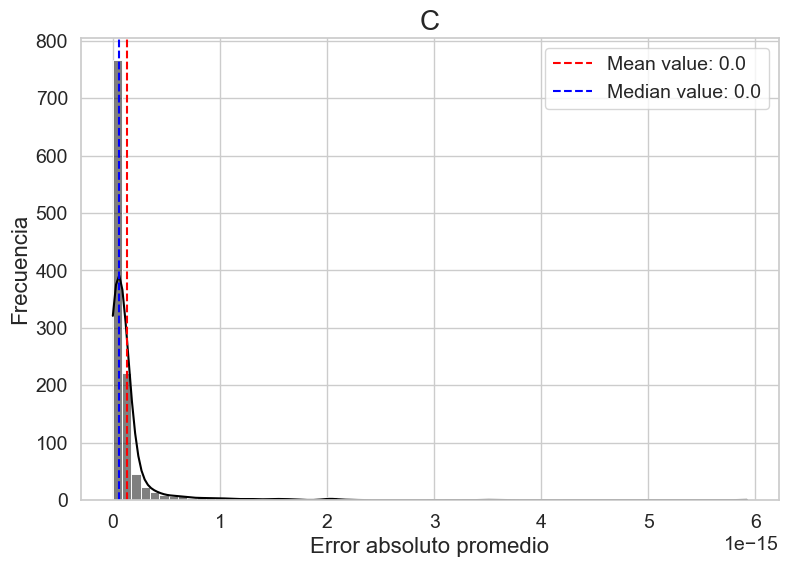

In [85]:
mean_value = refined_total_data.select(pl.col('average_absolute_error')).mean().to_numpy()[0][0]
median_value = refined_total_data.select(pl.col('average_absolute_error')).median().to_numpy()[0][0]
sns.histplot(x = refined_total_data.select(pl.col('average_absolute_error')).to_numpy().reshape(1133), kde = True, color='black').set(title = f'C',  ylabel = 'Frecuencia', xlabel = 'Error absoluto promedio')
plt.axvline(mean_value, color = 'red', linestyle = '--', label = f'Mean value: {round(mean_value, 3)}')
plt.axvline(median_value, color = 'blue', linestyle = '--', label = f'Median value: {round(median_value, 3)}')
plt.legend()
plt.savefig("Figure_3C.png", 
            dpi=1000, 
            bbox_inches='tight', 
            facecolor='white',
            edgecolor='none')
plt.show()

<>:30: SyntaxWarning: invalid escape sequence '\p'
<>:30: SyntaxWarning: invalid escape sequence '\p'
C:\Users\RPC\AppData\Local\Temp\ipykernel_35168\380448477.py:30: SyntaxWarning: invalid escape sequence '\p'
  plt.xlabel('Reconciled $\phi$', fontsize=18)


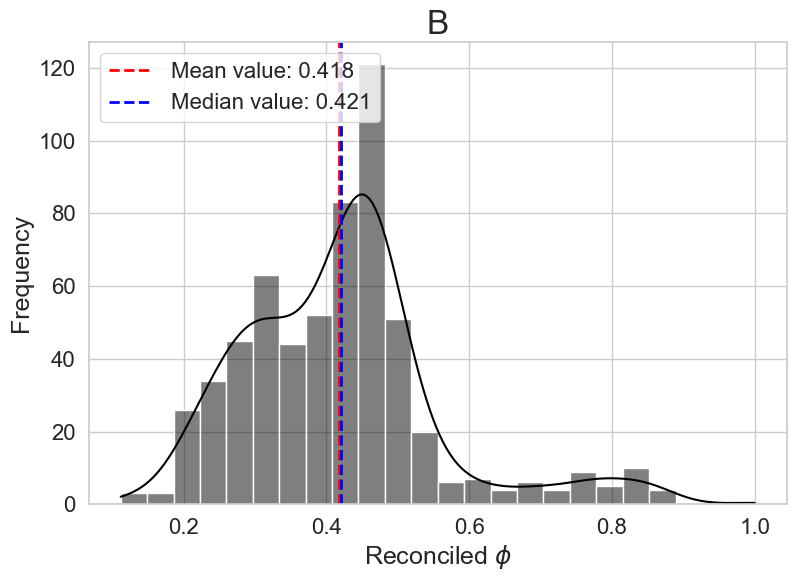

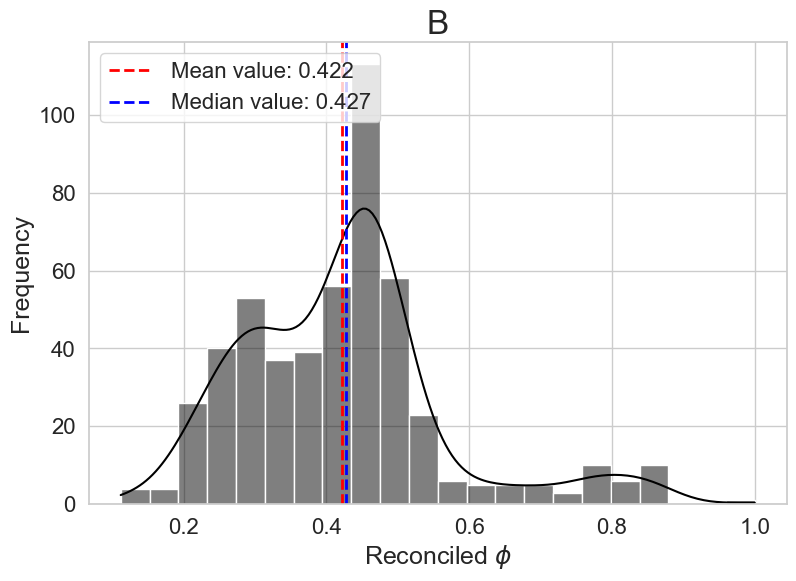

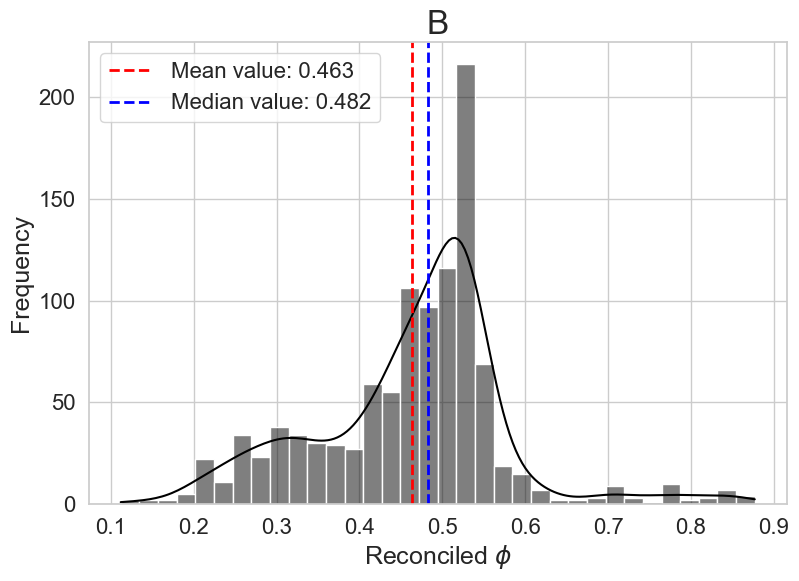

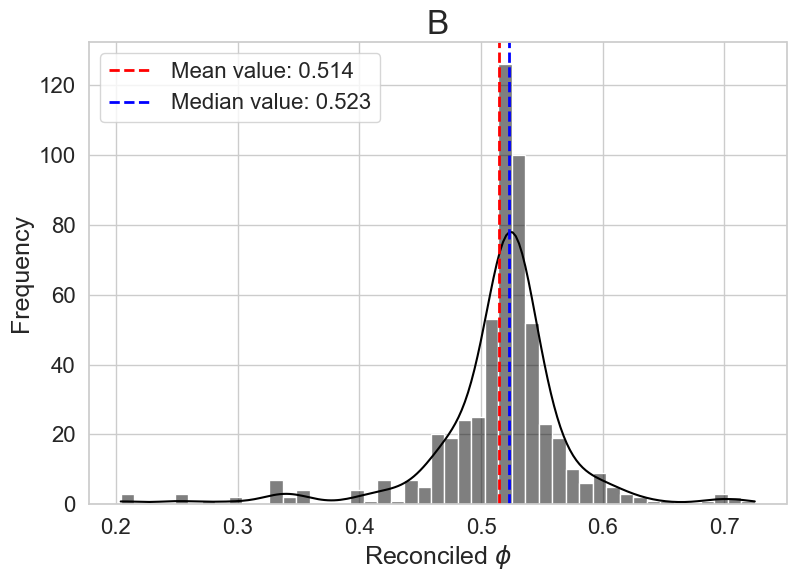

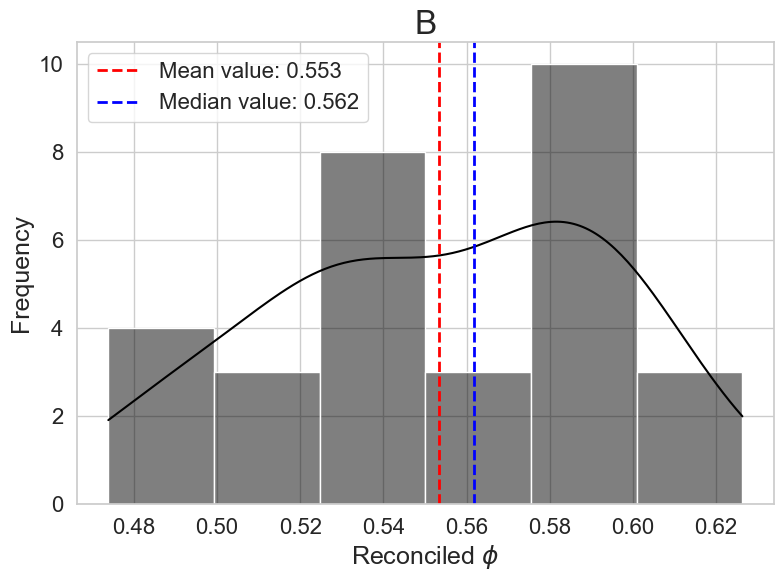

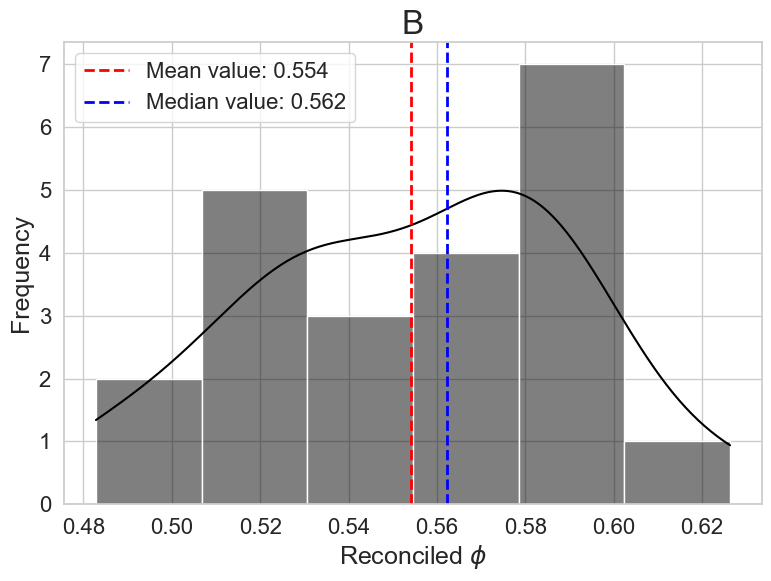

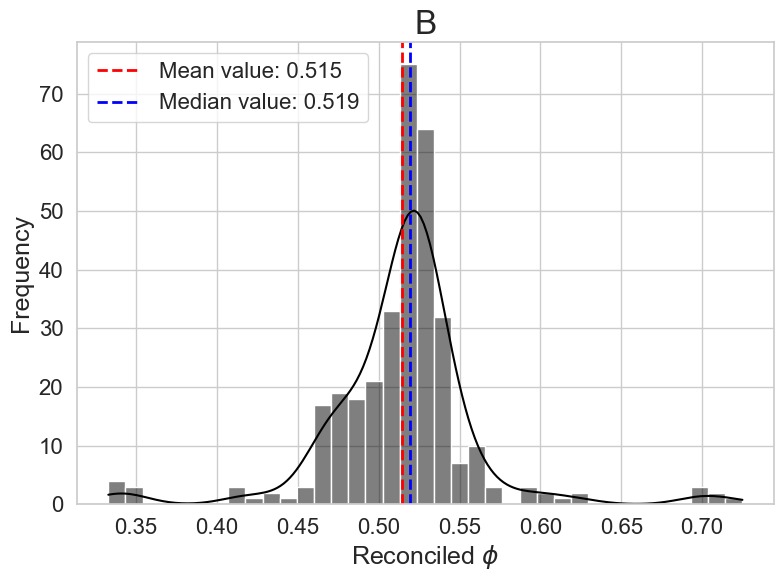

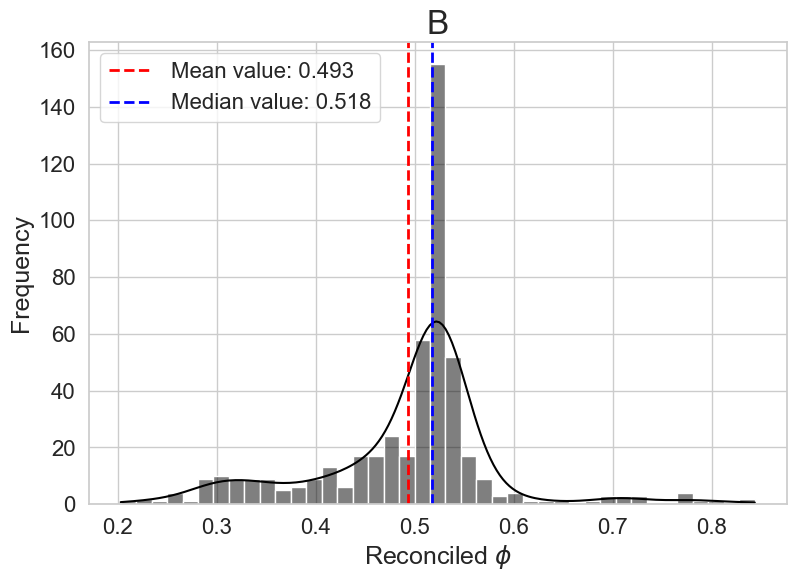

In [46]:

sns.set_theme(rc={
    'figure.figsize': (9, 6),
    'font.size': 14,
    'axes.titlesize': 20,
    'axes.labelsize': 16,
    'xtick.labelsize': 14,
    'ytick.labelsize': 14,
    'legend.fontsize': 14
})
sns.set_style("whitegrid")


feed_columns = ['FAME/FAEE_F', 'GLYCEROL_F', 'ALCOHOL_F', 'OIL_F', 'DAG_F', 'MAG_F', 'ACID_F', 'WATER_F']

for i in feed_columns:
    plt.figure()
    filter_data = refined_total_data.filter(pl.col(i) > 0.0)
    len_data = filter_data.shape[0]
    column_name = 'phi_' + i.rstrip('_F')
    mean_value = filter_data.select(pl.col(column_name)).mean().to_numpy()[0][0]
    median_value = filter_data.select(pl.col(column_name)).median().to_numpy()[0][0]
    
    # Create the histogram
    sns.histplot(x=filter_data.select(pl.col(column_name)).to_numpy().reshape(len_data), 
                 color='black', kde=True)
    
    # Set labels with larger fonts
    plt.title(f"B", fontsize=24)
    plt.ylabel('Frequency', fontsize=18)
    plt.xlabel('Reconciled $\phi$', fontsize=18)
    
    plt.axvline(mean_value, color='red', linestyle='--', linewidth=2,
                label=f'Mean value: {round(mean_value, 3)}')
    plt.axvline(median_value, color='blue', linestyle='--', linewidth=2,
                label=f'Median value: {round(median_value, 3)}')
    
    plt.legend(loc='upper left', fontsize=16)
    plt.tick_params(axis='both', which='major', labelsize=16)
    
    # Create safe filename and save at 1000 DPI
    safe_filename = i.rstrip('_F').replace('/', '_')
    plt.savefig(f'reconciled_phi_distribution_{safe_filename}.png', 
                dpi=1000, 
                bbox_inches='tight', 
                facecolor='white',
                edgecolor='none')
    
    plt.show()

<>:9: SyntaxWarning: invalid escape sequence '\p'
<>:9: SyntaxWarning: invalid escape sequence '\p'
<>:9: SyntaxWarning: invalid escape sequence '\p'
<>:9: SyntaxWarning: invalid escape sequence '\p'
C:\Users\RPC\AppData\Local\Temp\ipykernel_35168\786420164.py:9: SyntaxWarning: invalid escape sequence '\p'
  sns.histplot(x = filter_data.select(pl.col(column_name)).to_numpy().reshape(len_data), color = 'black', kde=True).set(title=f"$\phi$ {i.rstrip('_F')}", ylabel = 'Frequency', xlabel = 'Reconciled $\phi$')
C:\Users\RPC\AppData\Local\Temp\ipykernel_35168\786420164.py:9: SyntaxWarning: invalid escape sequence '\p'
  sns.histplot(x = filter_data.select(pl.col(column_name)).to_numpy().reshape(len_data), color = 'black', kde=True).set(title=f"$\phi$ {i.rstrip('_F')}", ylabel = 'Frequency', xlabel = 'Reconciled $\phi$')


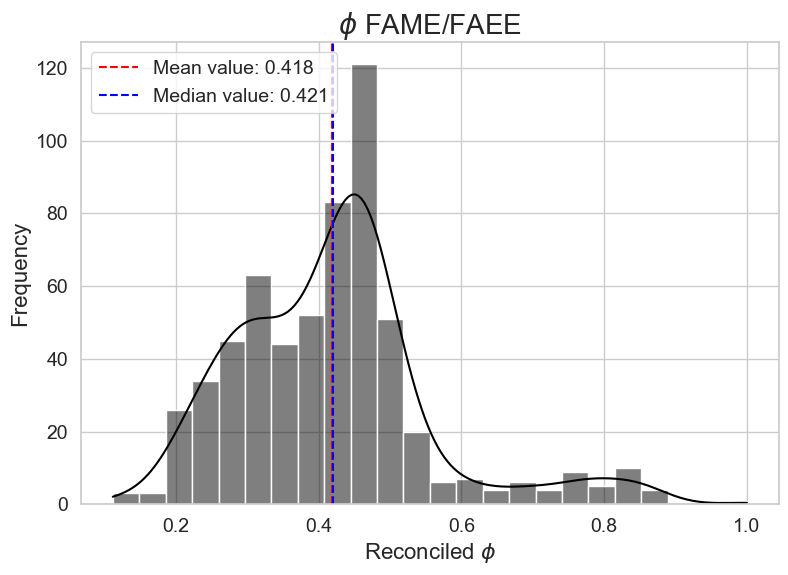

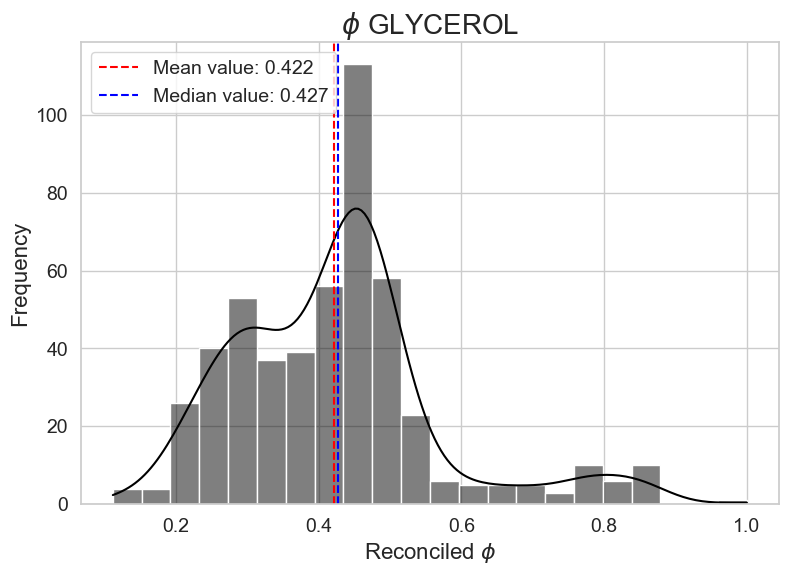

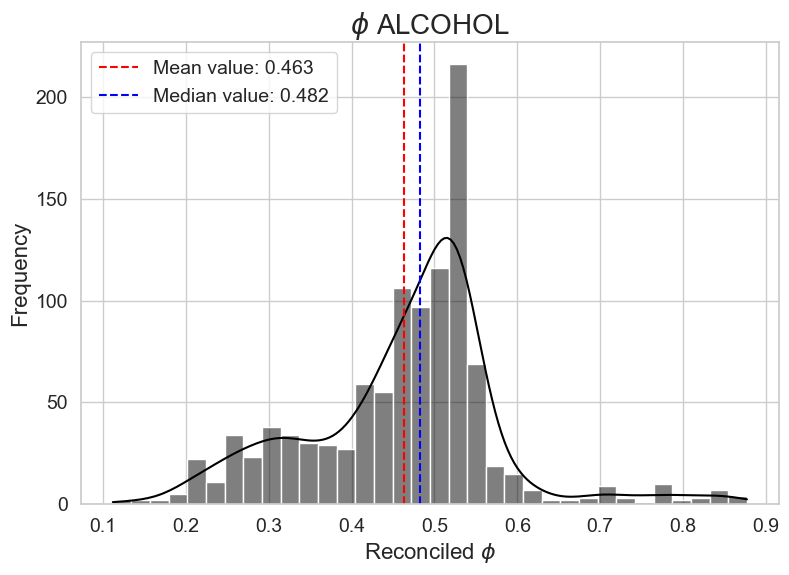

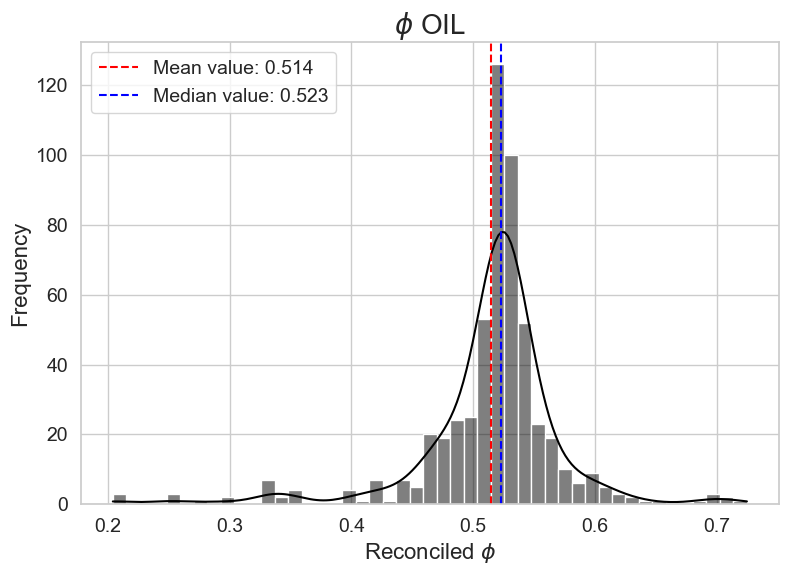

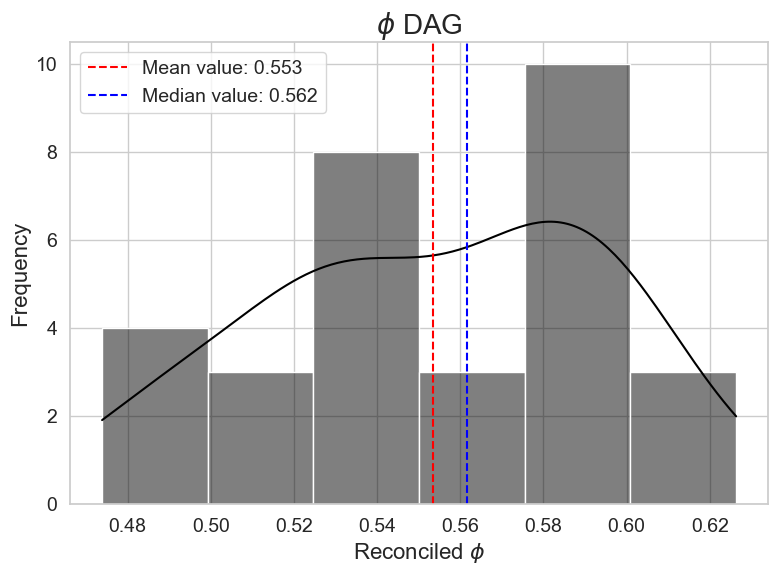

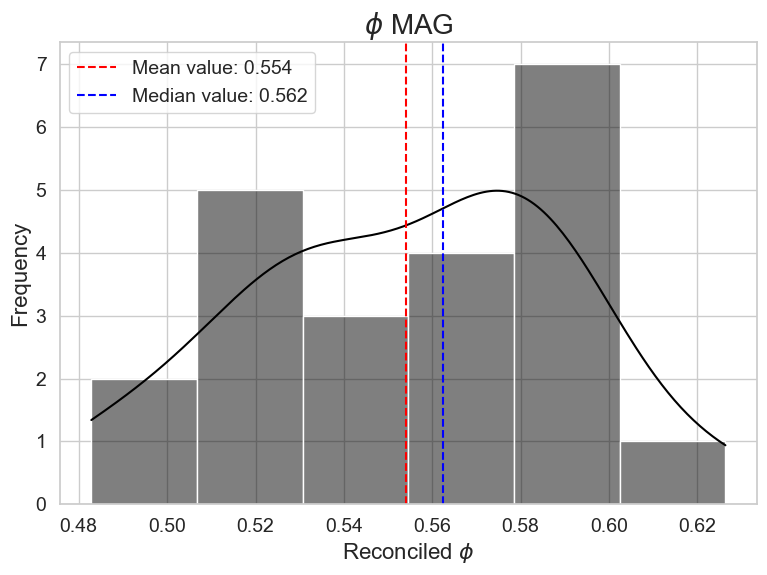

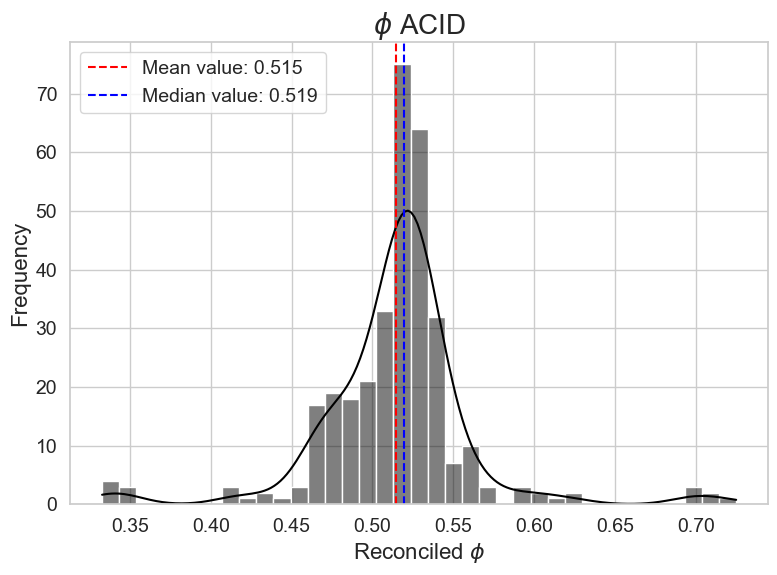

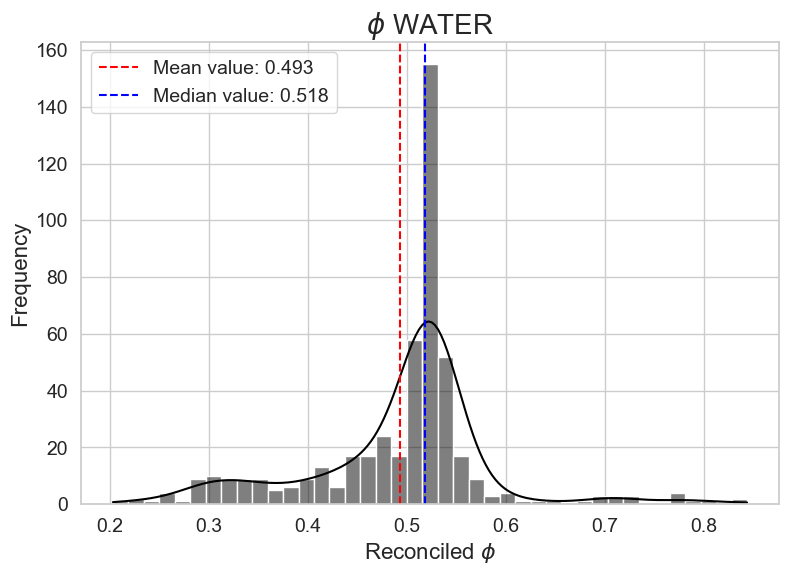

In [49]:
feed_columns = ['FAME/FAEE_F', 'GLYCEROL_F', 'ALCOHOL_F', 'OIL_F', 'DAG_F', 'MAG_F', 'ACID_F', 'WATER_F']
for i in feed_columns:
    plt.figure()
    filter_data = refined_total_data.filter(pl.col(i) > 0.0)
    len_data = filter_data.shape[0]
    column_name = 'phi_' + i.rstrip('_F')
    mean_value = filter_data.select(pl.col(column_name)).mean().to_numpy()[0][0]
    median_value = filter_data.select(pl.col(column_name)).median().to_numpy()[0][0]
    sns.histplot(x = filter_data.select(pl.col(column_name)).to_numpy().reshape(len_data), color = 'black', kde=True).set(title=f"$\phi$ {i.rstrip('_F')}", ylabel = 'Frequency', xlabel = 'Reconciled $\phi$')
    plt.axvline(mean_value, color = 'red', linestyle = '--',  label = f'Mean value: {round(mean_value, 3)}')
    plt.axvline(median_value, color = 'blue', linestyle = '--', label = f'Median value: {round(median_value, 3)}')
    plt.legend(loc= 'upper left')
    plt.show()

###  4. Source Data

In [2]:
import polars as pl
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import numpy as np
from sklearn.metrics import root_mean_squared_error

from matplotlib import cm
from scipy.interpolate import griddata

In [2]:
comps_mw = pl.read_excel(r"C:\Juan\Maestría\Code\oleosim\ExperimentalData\data\comps_MW.xlsx")
profile_coeffs_ref = pl.read_excel(r"C:\Juan\Maestría\Code\oleosim\SensitivityAnalysis\data\profile_coeffs_ref.xlsx")


In [3]:
profile_coeffs_ref = profile_coeffs_ref.filter(
    ~(pl.col("Source").str.contains("- Acid") | pl.col("Source").str.contains("- FAME")| pl.col("Source").str.contains("- MAG/DAG"))
)

In [4]:
result = comps_mw.join(
    profile_coeffs_ref.select(["Ref", "Sub Ref", "Source"]),  # Select only the columns you need from df2
    on=["Ref", "Sub Ref"],  # Join on these two columns
    how="left"  # Use left join to keep all rows from df1
)

In [5]:
results_pd = result.to_pandas()

In [6]:
def calculate_stats(df, parameters):
    mean_value = df[parameters].mean()
    std_value = df[parameters].std()
    max_value = df[parameters].max()
    min_value = df[parameters].min()

    return {"mean":mean_value, "std":std_value, "max":max_value, "min":min_value}

    
stats_fame = calculate_stats(results_pd, "MW_FAME/FAEE")
stats_oil = calculate_stats(results_pd, "MW_Oil")

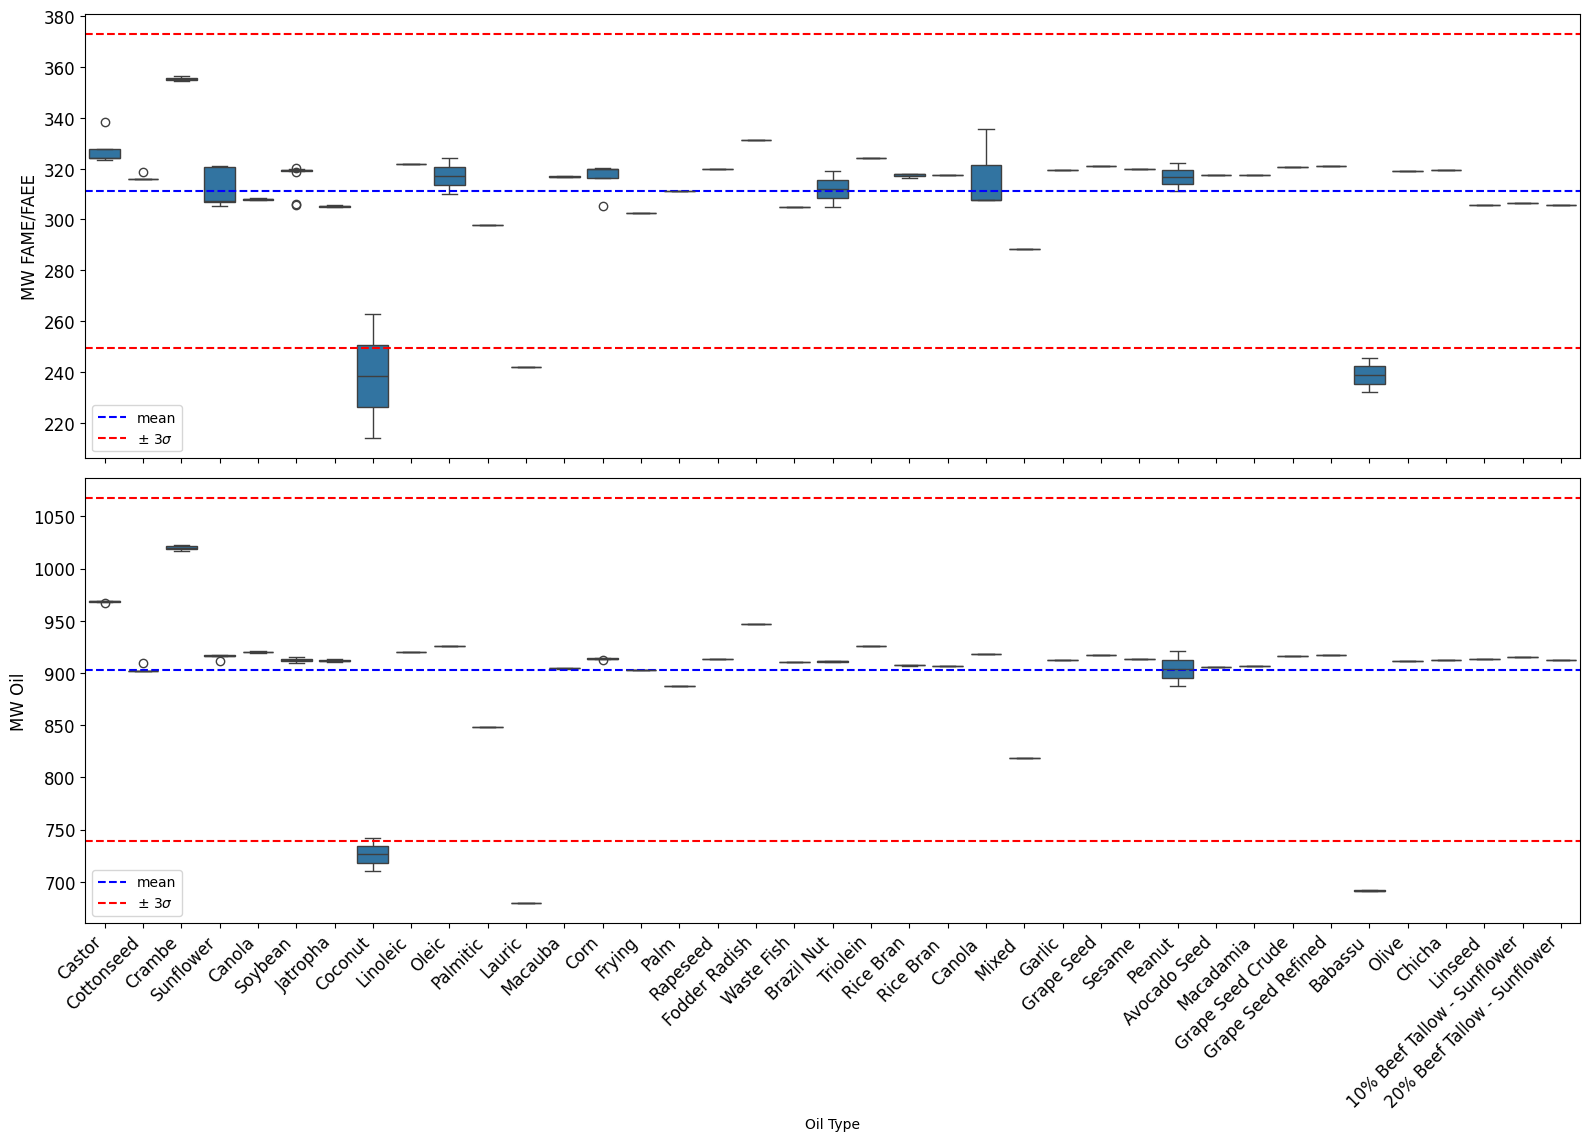

In [7]:
columns = ['m', 'n', 'p']
# for comparing distributions between groups
fig, axes = plt.subplots(2, 1, figsize=(16, 12), sharex=True)
axes = axes.flatten()

sns.boxplot(x='Source', y="MW_FAME/FAEE", data=results_pd, ax=axes[0])
axes[0].set_xlabel('Oil Type')
axes[0].set_ylabel("MW FAME/FAEE", fontsize=12)
axes[0].axhline(y=stats_fame["mean"], color="blue", linestyle="--", label="mean")
axes[0].axhline(y=stats_fame["mean"] + stats_fame["std"]*3, color="red", linestyle="--", label="$\pm$ 3$\sigma$")
axes[0].axhline(y=stats_fame["mean"] - stats_fame["std"]*3, color="red", linestyle="--")
axes[0].tick_params(axis='both', labelsize=12)
plt.setp(axes[0].get_xticklabels(), rotation=45, ha='right')
axes[0].legend()

sns.boxplot(x='Source', y="MW_Oil", data=results_pd, ax=axes[1])
axes[1].set_xlabel('Oil Type')
axes[1].set_ylabel("MW Oil", fontsize=12)
axes[1].axhline(y=stats_oil["mean"], color="blue", linestyle="--", label="mean")
axes[1].axhline(y=stats_oil["mean"] + stats_oil["std"]*3, color="red", linestyle="--", label="$\pm$ 3$\sigma$")
axes[1].axhline(y=stats_oil["mean"] - stats_oil["std"]*3, color="red", linestyle="--")
axes[1].tick_params(axis='both', labelsize=12)
plt.setp(axes[1].get_xticklabels(), rotation=45, ha='right')
axes[1].legend()


plt.tight_layout(rect=[0, 0, 1, 0.96])
#plt.savefig(f'Figure_4.png', dpi=1000, bbox_inches='tight', facecolor='white',edgecolor='none')
    
plt.show()

##### Acid Profiles

In [24]:
acid_profiles = pl.read_excel(r"C:\Juan\Maestría\Code\oleosim\ExperimentalData\data\acid_profile.xlsx")

FileNotFoundError: no workbook found at path 'C:\\Juan\\Maestría\\Code\\oleosim\\ExperimentalData\\data\\acid_profile.xlsx'

In [ ]:
acid_profiles_pd = acid_profiles.to_pandas()

In [10]:
acid_profiles_pd

,Ref,Sub Ref,MAG/DAG Profile?,Additional FAME Profile?,Acid mix Profile?,Caproic,Caprilic,Capric,Lauric,Mirystic,...,Tetracosanoic,Pentadecanoic,Gadoleic,Elaidic,"9,10-methylene-hexadecanoic",Dihydrosterculic,Paullinic,Malvalic,Sterculic,Total
0,1,a,No,No,No,0.0,0.0000,0.0000,0.00000,0.0000,...,0.0,0.0,0.0000,0.0,0.0,0.0,0.0,0.0,0.0,0.998000
1,2,a,No,No,No,0.0,0.0000,0.0000,0.00000,0.0000,...,0.0,0.0,0.0000,0.0,0.0,0.0,0.0,0.0,0.0,0.983000
2,3,a,No,No,No,0.0,0.0000,0.0000,0.00000,0.0000,...,0.0,0.0,0.0000,0.0,0.0,0.0,0.0,0.0,0.0,1.001000
3,4,a,No,No,No,0.0,0.0000,0.0000,0.00000,0.0000,...,0.0,0.0,0.0000,0.0,0.0,0.0,0.0,0.0,0.0,1.001000
4,5,a,No,No,No,0.0,0.0000,0.0000,0.00000,0.0000,...,0.0,0.0,0.0000,0.0,0.0,0.0,0.0,0.0,0.0,1.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
120,55,c,Yes,No,No,0.0,0.0000,0.0000,0.00040,0.0009,...,0.0,0.0,0.0014,0.0,0.0,0.0,0.0,0.0,0.0,0.998300
121,56,a,No,No,No,0.0,0.0000,0.0000,0.00100,0.0000,...,0.0,0.0,0.0000,0.0,0.0,0.0,0.0,0.0,0.0,0.981400
122,56,b,No,No,No,0.0,0.0000,0.0000,0.00467,0.0000,...,0.0,0.0,0.0000,0.0,0.0,0.0,0.0,0.0,0.0,0.980076
123,56,c,No,No,No,0.0,0.0000,0.0000,0.00834,0.0000,...,0.0,0.0,0.0000,0.0,0.0,0.0,0.0,0.0,0.0,0.978752


In [11]:
acid_profiles_pd_masked  = acid_profiles_pd[['Caproic', 'Caprilic', 'Capric', 'Lauric',
       'Mirystic', 'Palmitic', 'Palmitoleic', 'Heptadecanoic',
       'cis-9-heptadecenoic', 'Stearic', 'Oleic', 'Linoleic', 'Linolenic',
       'Ricinoleic', 'Densipolic', 'Arachidic', 'Arachidonic', 'Gondoic',
       'cis-11,14 eicosadienoic', 'Behenic', 'Erucic',
       'cis-13 cis-16 docosadienoic', 'Tetracosanoic', 'Pentadecanoic',
       'Gadoleic', 'Elaidic', '9,10-methylene-hexadecanoic',
       'Dihydrosterculic', 'Paullinic', 'Malvalic', 'Sterculic']].replace(0, np.nan)

pd.set_option('display.max_columns', None)

acid_profiles_pd_masked[['Caproic', 'Caprilic', 'Capric', 'Lauric',
       'Mirystic', 'Palmitic', 'Palmitoleic', 'Heptadecanoic',
       'cis-9-heptadecenoic', 'Stearic', 'Oleic', 'Linoleic', 'Linolenic',
       'Ricinoleic', 'Densipolic', 'Arachidic', 'Arachidonic', 'Gondoic',
       'cis-11,14 eicosadienoic', 'Behenic', 'Erucic',
       'cis-13 cis-16 docosadienoic', 'Tetracosanoic', 'Pentadecanoic',
       'Gadoleic', 'Elaidic', '9,10-methylene-hexadecanoic',
       'Dihydrosterculic', 'Paullinic', 'Malvalic', 'Sterculic']].describe()


,Caproic,Caprilic,Capric,Lauric,Mirystic,Palmitic,Palmitoleic,Heptadecanoic,cis-9-heptadecenoic,Stearic,Oleic,Linoleic,Linolenic,Ricinoleic,Densipolic,Arachidic,Arachidonic,Gondoic,"cis-11,14 eicosadienoic",Behenic,Erucic,cis-13 cis-16 docosadienoic,Tetracosanoic,Pentadecanoic,Gadoleic,Elaidic,"9,10-methylene-hexadecanoic",Dihydrosterculic,Paullinic,Malvalic,Sterculic
count,6.000000,5.000000,7.000000,37.000000,64.000000,114.000000,59.000000,5.000000,10.000000,104.000000,115.000000,112.000000,81.000000,5.000000,1.0000,51.000000,4.000000,8.000000,1.0000,38.000000,5.000000,4.000000,5.000000,2.000000,24.000000,2.0000,1.000,1.000,1.000,1.000,1.00
mean,0.019850,0.035560,0.310114,0.141760,0.017863,0.134168,0.018446,0.048840,0.017500,0.043136,0.374584,0.377909,0.030750,0.733700,0.0093,0.005317,0.003050,0.025700,0.0292,0.023734,0.113280,0.003350,0.002340,0.010550,0.003650,0.0466,0.011,0.046,0.119,0.359,0.12
std,0.042146,0.025639,0.471766,0.297411,0.042283,0.148235,0.032390,0.105193,0.017759,0.066846,0.257499,0.255039,0.059456,0.378801,NaN,0.004554,0.000614,0.034241,NaN,0.097292,0.247493,0.001797,0.001695,0.014354,0.004831,0.0000,NaN,NaN,NaN,NaN,NaN
min,0.001000,0.004800,0.004400,0.000200,0.000097,0.007400,0.000600,0.000500,0.000500,0.006100,0.024200,0.004100,0.000500,0.056300,0.0093,0.000326,0.002200,0.001000,0.0292,0.000500,0.001300,0.002000,0.000500,0.000400,0.000600,0.0466,0.011,0.046,0.119,0.359,0.12
25%,0.001375,0.014400,0.025300,0.001800,0.001325,0.055550,0.001150,0.000500,0.002800,0.021075,0.196900,0.114450,0.003800,0.889300,0.0093,0.002100,0.002800,0.001200,0.0292,0.001350,0.001300,0.002525,0.001000,0.005475,0.001400,0.0466,0.011,0.046,0.119,0.359,0.12
50%,0.002650,0.040800,0.045300,0.004900,0.003600,0.097100,0.003200,0.003100,0.009600,0.030500,0.278400,0.431600,0.011000,0.898700,0.0093,0.004100,0.003250,0.011200,0.0292,0.003700,0.002800,0.002700,0.002000,0.010550,0.002350,0.0466,0.011,0.046,0.119,0.359,0.12
75%,0.005200,0.051200,0.535250,0.025400,0.009650,0.154050,0.028500,0.003100,0.031975,0.040700,0.492250,0.559000,0.045900,0.912100,0.0093,0.006600,0.003500,0.039350,0.0292,0.005200,0.005000,0.003525,0.004100,0.015625,0.003925,0.0466,0.011,0.046,0.119,0.359,0.12
max,0.105800,0.066600,1.000000,1.000000,0.198400,1.000000,0.192800,0.237000,0.050100,0.487500,1.000000,1.000000,0.495441,0.912100,0.0093,0.025600,0.003500,0.100400,0.0292,0.593500,0.556000,0.006000,0.004100,0.020700,0.024800,0.0466,0.011,0.046,0.119,0.359,0.12


In [12]:
repeated_FA = (acid_profiles_pd[['Caproic', 'Caprilic', 'Capric', 'Lauric',
       'Mirystic', 'Palmitic', 'Palmitoleic', 'Heptadecanoic',
       'cis-9-heptadecenoic', 'Stearic', 'Oleic', 'Linoleic', 'Linolenic',
       'Ricinoleic', 'Densipolic', 'Arachidic', 'Arachidonic', 'Gondoic',
       'cis-11,14 eicosadienoic', 'Behenic', 'Erucic',
       'cis-13 cis-16 docosadienoic', 'Tetracosanoic', 'Pentadecanoic',
       'Gadoleic', 'Elaidic', '9,10-methylene-hexadecanoic',
       'Dihydrosterculic', 'Paullinic', 'Malvalic', 'Sterculic']] > 0).sum().sort_values(ascending=False)

repeated_FA

Oleic                          115
Palmitic                       114
Linoleic                       112
Stearic                        104
Linolenic                       81
Mirystic                        64
Palmitoleic                     59
Arachidic                       51
Behenic                         38
Lauric                          37
Gadoleic                        24
cis-9-heptadecenoic             10
Gondoic                          8
Capric                           7
Caproic                          6
Caprilic                         5
Ricinoleic                       5
Erucic                           5
Tetracosanoic                    5
Heptadecanoic                    5
Arachidonic                      4
cis-13 cis-16 docosadienoic      4
Pentadecanoic                    2
Elaidic                          2
Densipolic                       1
cis-11,14 eicosadienoic          1
9,10-methylene-hexadecanoic      1
Dihydrosterculic                 1
Paullinic           

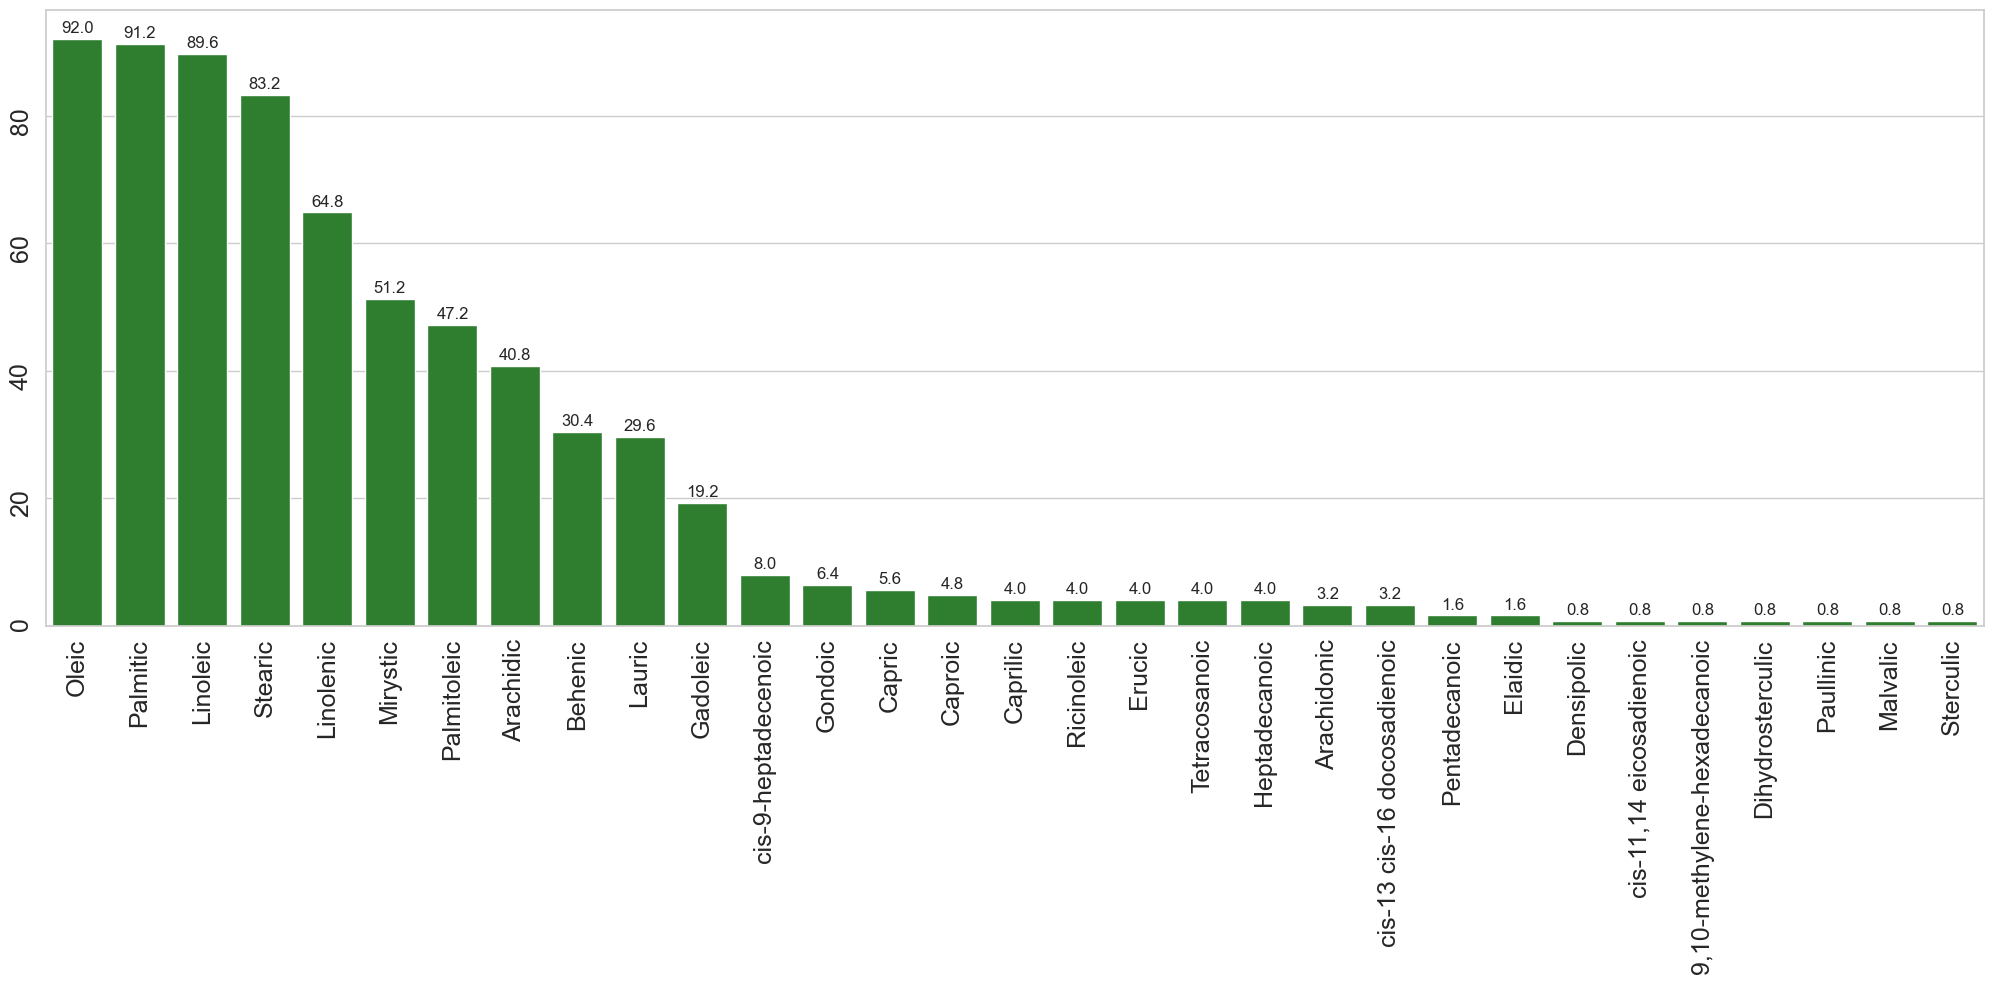

In [13]:
sns.set_theme(rc={'figure.figsize':(25,8)})
sns.set_style("whitegrid")
# Create barplot
ax = sns.barplot(repeated_FA/125*100, color="forestgreen")

# Add value labels
for bar in ax.patches:
    height = bar.get_height()
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        height + 0.5,
        f'{height:.1f}',
        ha='center',
        va='bottom'
    )
    
plt.xticks(rotation=90, fontsize=18)
plt.yticks(rotation=90, fontsize=18)

plt.show()

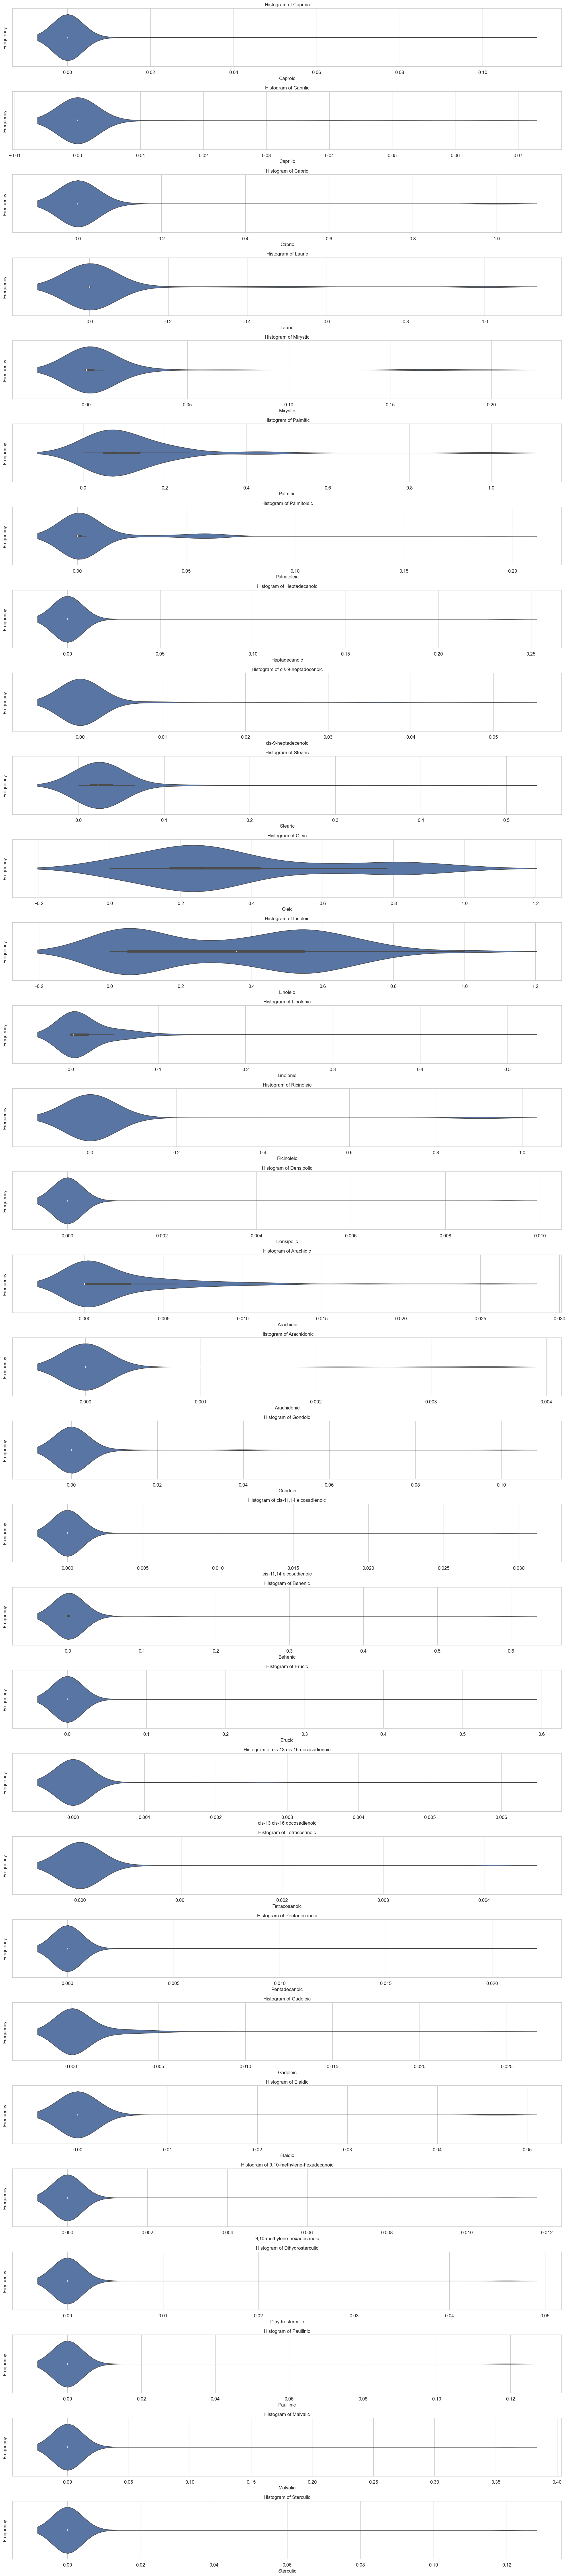

In [14]:
columns_to_plot = ['Caproic', 'Caprilic', 'Capric', 'Lauric',
       'Mirystic', 'Palmitic', 'Palmitoleic', 'Heptadecanoic',
       'cis-9-heptadecenoic', 'Stearic', 'Oleic', 'Linoleic', 'Linolenic',
       'Ricinoleic', 'Densipolic', 'Arachidic', 'Arachidonic', 'Gondoic',
       'cis-11,14 eicosadienoic', 'Behenic', 'Erucic',
       'cis-13 cis-16 docosadienoic', 'Tetracosanoic', 'Pentadecanoic',
       'Gadoleic', 'Elaidic', '9,10-methylene-hexadecanoic',
       'Dihydrosterculic', 'Paullinic', 'Malvalic', 'Sterculic']

# Create subplots
fig, axes = plt.subplots(len(columns_to_plot), 1, figsize=(20, 90))

# If only one column, wrap axis in a list for consistency
if len(columns_to_plot) == 1:
    axes = [axes]

# Plot each histogram
for i, col in enumerate(columns_to_plot):
    sns.violinplot(data=acid_profiles_pd, x=col,  ax=axes[i])
    axes[i].set_title(f'Histogram of {col}')
    axes[i].set_xlabel(col)
    axes[i].set_ylabel('Frequency')
    axes[i].tick_params(axis='both', labelsize=12)

plt.tight_layout()
plt.show()

##### Equilibrium data

In [53]:
df = pl.read_excel(r"C:\Juan\maestria\ThermOleo\SensitivityAnalysis\data\profile_coeffs_ref.xlsx")

In [54]:
filtered_df = df.filter(
    ~(
        pl.col("Source").str.contains("Acid") | 
        pl.col("Source").str.contains("FAME") | 
        pl.col("Source").str.contains("MAG/DAG")
    )
)

In [55]:
filtered_df
with pl.Config(tbl_rows=len(filtered_df), tbl_cols=-1):
    print(filtered_df)

shape: (83, 11)
┌─────┬─────┬──────────┬─────────┬─────────┬─────────┬─────────┬─────────┬─────────┬─────┬─────────┐
│ Ref ┆ Sub ┆ MAG/DAG  ┆ Additio ┆ Acid    ┆ Type    ┆ m       ┆ n       ┆ p       ┆ b   ┆ Source  │
│ --- ┆ Ref ┆ Profile? ┆ nal     ┆ mix Pro ┆ Alcohol ┆ ---     ┆ ---     ┆ ---     ┆ --- ┆ ---     │
│ i64 ┆ --- ┆ ---      ┆ FAME    ┆ file?   ┆ ---     ┆ f64     ┆ f64     ┆ f64     ┆ i64 ┆ str     │
│     ┆ str ┆ str      ┆ Profile ┆ ---     ┆ i64     ┆         ┆         ┆         ┆     ┆         │
│     ┆     ┆          ┆ ?       ┆ str     ┆         ┆         ┆         ┆         ┆     ┆         │
│     ┆     ┆          ┆ ---     ┆         ┆         ┆         ┆         ┆         ┆     ┆         │
│     ┆     ┆          ┆ str     ┆         ┆         ┆         ┆         ┆         ┆     ┆         │
╞═════╪═════╪══════════╪═════════╪═════════╪═════════╪═════════╪═════════╪═════════╪═════╪═════════╡
│ 1   ┆ a   ┆ No       ┆ No      ┆ No      ┆ 1       ┆ 12.9912 ┆ 1.04369 ┆ 

In [56]:
filtered_df.filter(pl.col("Source")=="Palm")

Ref,Sub Ref,MAG/DAG Profile?,Additional FAME Profile?,Acid mix Profile?,Type Alcohol,m,n,p,b,Source
i64,str,str,str,str,i64,f64,f64,f64,i64,str
20,"""a""","""No""","""No""","""No""",2,13.851386,0.587797,0.0,1,"""Palm"""
34,"""a""","""No ""","""No""","""No""",2,13.882211,0.573585,0.0,1,"""Palm"""
34,"""b""","""No""","""No""","""No""",2,13.882211,0.573585,0.0,1,"""Palm"""


In [57]:
stats_df = filtered_df.group_by('Source').agg([
    # For column 'm'
    pl.col('m').min().alias('m_min'),
    pl.col('m').quantile(0.25).alias('m_q25'),
    pl.col('m').median().alias('m_median'),
    pl.col('m').quantile(0.75).alias('m_q75'),
    pl.col('m').max().alias('m_max'),
    pl.col('m').mean().alias('m_mean'),
    
    # For column 'n'
    pl.col('n').min().alias('n_min'),
    pl.col('n').quantile(0.25).alias('n_q25'),
    pl.col('n').median().alias('n_median'),
    pl.col('n').quantile(0.75).alias('n_q75'),
    pl.col('n').max().alias('n_max'),
    pl.col('n').mean().alias('n_mean'),
    
    # For column 'p'
    pl.col('p').min().alias('p_min'),
    pl.col('p').quantile(0.25).alias('p_q25'),
    pl.col('p').median().alias('p_median'),
    pl.col('p').quantile(0.75).alias('p_q75'),
    pl.col('p').max().alias('p_max'),
    pl.col('p').mean().alias('p_mean'),
    
])

with pl.Config(tbl_rows=len(stats_df), tbl_cols=-1):
    print(stats_df)

shape: (39, 19)
┌─────┬─────┬─────┬─────┬─────┬─────┬─────┬─────┬─────┬─────┬─────┬─────┬─────┬─────┬─────┬─────┬─────┬─────┬─────┐
│ Sou ┆ m_m ┆ m_q ┆ m_m ┆ m_q ┆ m_m ┆ m_m ┆ n_m ┆ n_q ┆ n_m ┆ n_q ┆ n_m ┆ n_m ┆ p_m ┆ p_q ┆ p_m ┆ p_q ┆ p_m ┆ p_m │
│ rce ┆ in  ┆ 25  ┆ edi ┆ 75  ┆ ax  ┆ ean ┆ in  ┆ 25  ┆ edi ┆ 75  ┆ ax  ┆ ean ┆ in  ┆ 25  ┆ edi ┆ 75  ┆ ax  ┆ ean │
│ --- ┆ --- ┆ --- ┆ an  ┆ --- ┆ --- ┆ --- ┆ --- ┆ --- ┆ an  ┆ --- ┆ --- ┆ --- ┆ --- ┆ --- ┆ an  ┆ --- ┆ --- ┆ --- │
│ str ┆ f64 ┆ f64 ┆ --- ┆ f64 ┆ f64 ┆ f64 ┆ f64 ┆ f64 ┆ --- ┆ f64 ┆ f64 ┆ f64 ┆ f64 ┆ f64 ┆ --- ┆ f64 ┆ f64 ┆ f64 │
│     ┆     ┆     ┆ f64 ┆     ┆     ┆     ┆     ┆     ┆ f64 ┆     ┆     ┆     ┆     ┆     ┆ f64 ┆     ┆     ┆     │
╞═════╪═════╪═════╪═════╪═════╪═════╪═════╪═════╪═════╪═════╪═════╪═════╪═════╪═════╪═════╪═════╪═════╪═════╪═════╡
│ Ric ┆ 13. ┆ 13. ┆ 13. ┆ 13. ┆ 13. ┆ 13. ┆ 1.1 ┆ 1.1 ┆ 1.1 ┆ 1.1 ┆ 1.1 ┆ 1.1 ┆ 0.0 ┆ 0.0 ┆ 0.0 ┆ 0.0 ┆ 0.0 ┆ 0.0 │
│ e   ┆ 282 ┆ 282 ┆ 282 ┆ 282 ┆ 282 ┆ 282 ┆ 350 ┆ 350 ┆ 

In [58]:
count_values = filtered_df.group_by('Source').agg(
    pl.col('m').count().alias('m_count')
)

count_values = count_values.sort(by="m_count", descending=True)

with pl.Config(tbl_rows=len(count_values)):
    print(count_values)

shape: (39, 2)
┌─────────────────────────────┬─────────┐
│ Source                      ┆ m_count │
│ ---                         ┆ ---     │
│ str                         ┆ u32     │
╞═════════════════════════════╪═════════╡
│ Soybean                     ┆ 13      │
│ Sunflower                   ┆ 7       │
│ Cottonseed                  ┆ 5       │
│ Corn                        ┆ 4       │
│ Castor                      ┆ 4       │
│ Rice Bran                   ┆ 3       │
│ Canola                      ┆ 3       │
│ Palm                        ┆ 3       │
│ Canola                      ┆ 3       │
│ Jatropha                    ┆ 2       │
│ Coconut                     ┆ 2       │
│ Oleic                       ┆ 2       │
│ Babassu                     ┆ 2       │
│ Brazil Nut                  ┆ 2       │
│ Crambe                      ┆ 2       │
│ Macauba                     ┆ 2       │
│ Peanut                      ┆ 2       │
│ Sesame                      ┆ 1       │
│ Avocado Seed     

In [59]:
df_pandas = filtered_df.to_pandas()

In [60]:
def calculate_stats(df, parameters):
    mean_value = df[parameters].mean()
    std_value = df[parameters].std()
    max_value = df[parameters].max()
    min_value = df[parameters].min()

    return {"mean":mean_value, "std":std_value, "max":max_value, "min":min_value}

    
stats_m = calculate_stats(df_pandas, "m")
stats_n = calculate_stats(df_pandas, "n")
stats_p = calculate_stats(df_pandas, "p")


In [61]:
print(f"m: {stats_m} \n", f"n: {stats_n} \n", f"p: {stats_p} \n")

m: {'mean': np.float64(13.040792518062323), 'std': np.float64(0.9779327887372177), 'max': np.float64(17.05411199780443), 'min': np.float64(10.0)} 
 n: {'mean': np.float64(1.1693300246015552), 'std': np.float64(0.4197608338972609), 'max': np.float64(2.033213061043078), 'min': np.float64(0.0)} 
 p: {'mean': np.float64(0.044221110393172974), 'std': np.float64(0.19476429553145658), 'max': np.float64(0.9149194700052542), 'min': np.float64(0.0)} 



In [62]:
rows = ['Soybean', 'Cottonseed', 'Palm', 'Crambe', 'Coconut', 'Babassu', 'Sunflower', 'Canola', 'Castor', 'Corn', 'Peanut', 'Linoleic', 'Linseed']
df_pandas_filtered = df_pandas[df_pandas['Source'].isin(rows)]

In [63]:
translation = {
    'Soybean': 'Soya',
    'Cottonseed': 'Algodón',
    'Palm': 'Palma',
    'Crambe': 'Crambe',
    'Coconut': 'Coco',
    'Babassu': 'Babasú',
    'Sunflower': 'Girasol',
    'Canola': 'Canola',
    'Castor': 'Ricino',
    'Corn': 'Maíz',
    'Peanut': 'Maní',
    'Linoleic': 'Linoleico',
    'Linseed': 'Linaza'
}

# Apply translation
df_pandas_filtered['Source'] = df_pandas_filtered['Source'].replace(translation)

C:\Users\RPC\AppData\Local\Temp\ipykernel_33504\3483735008.py:18: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_pandas_filtered['Source'] = df_pandas_filtered['Source'].replace(translation)


<>:10: SyntaxWarning: invalid escape sequence '\p'
<>:20: SyntaxWarning: invalid escape sequence '\p'
<>:10: SyntaxWarning: invalid escape sequence '\p'
<>:20: SyntaxWarning: invalid escape sequence '\p'
C:\Users\RPC\AppData\Local\Temp\ipykernel_33504\4016271884.py:10: SyntaxWarning: invalid escape sequence '\p'
  axes[0].axhline(y=stats_m["mean"] + stats_m["std"]*3, color="red", linestyle="--", label="$\pm$ 3$\sigma$")
C:\Users\RPC\AppData\Local\Temp\ipykernel_33504\4016271884.py:20: SyntaxWarning: invalid escape sequence '\p'
  axes[1].axhline(y=stats_n["mean"] + stats_n["std"]*3, color="red", linestyle="--", label="$\pm$ 3$\sigma$")


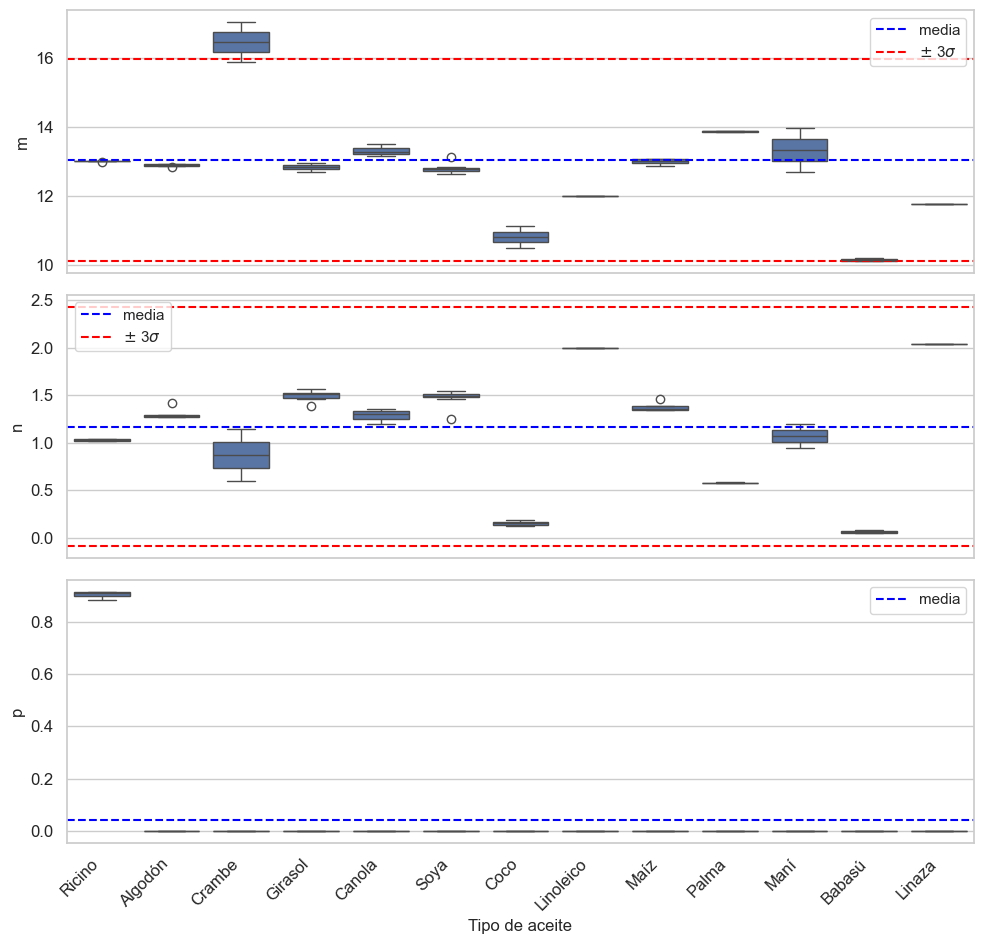

In [64]:
columns = ['m', 'n', 'p']
# for comparing distributions between groups
fig, axes = plt.subplots(3, 1, figsize=(10, 10), sharex=True)
axes = axes.flatten()

sns.boxplot(x='Source', y="m", data=df_pandas_filtered, ax=axes[0])
axes[0].set_xlabel('Tipo de aceite')
axes[0].set_ylabel("m", fontsize=12)
axes[0].axhline(y=stats_m["mean"], color="blue", linestyle="--", label="media")
axes[0].axhline(y=stats_m["mean"] + stats_m["std"]*3, color="red", linestyle="--", label="$\pm$ 3$\sigma$")
axes[0].axhline(y=stats_m["mean"] - stats_m["std"]*3, color="red", linestyle="--")
axes[0].tick_params(axis='both', labelsize=12)
plt.setp(axes[0].get_xticklabels(), rotation=45, ha='right')
axes[0].legend()

sns.boxplot(x='Source', y="n", data=df_pandas_filtered, ax=axes[1])
axes[1].set_xlabel('Tipo de aceite')
axes[1].set_ylabel("n", fontsize=12)
axes[1].axhline(y=stats_n["mean"], color="blue", linestyle="--", label="media")
axes[1].axhline(y=stats_n["mean"] + stats_n["std"]*3, color="red", linestyle="--", label="$\pm$ 3$\sigma$")
axes[1].axhline(y=stats_n["mean"] - stats_n["std"]*3, color="red", linestyle="--")
axes[1].tick_params(axis='both', labelsize=12)
plt.setp(axes[1].get_xticklabels(), rotation=45, ha='right')
axes[1].legend()

sns.boxplot(x='Source', y="p", data=df_pandas_filtered, ax=axes[2])
axes[2].set_xlabel('Tipo de aceite')
axes[2].set_ylabel("p", fontsize=12)
axes[2].axhline(y=stats_p["mean"], color="blue", linestyle="--", label="media")
plt.setp(axes[2].get_xticklabels(), rotation=45, ha='right')
axes[2].legend()
axes[2].tick_params(axis='both', labelsize=12)

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.savefig(f'Figure_4.png', 
                dpi=1000, 
                bbox_inches='tight', 
                facecolor='white',
                edgecolor='none')
    
plt.show()

In [65]:
refined_data = pl.read_excel(r"C:\Juan\maestria\ThermOleo\ExperimentalData\data\No 47exp\refined_lle_data_v5.xlsx")
raw_data = pl.read_excel(r"C:\Juan\maestria\ThermOleo\ExperimentalData\data\raw_lle_data.xlsx")

Could not determine dtype for column 28, falling back to string
Could not determine dtype for column 29, falling back to string
Could not determine dtype for column 30, falling back to string
Could not determine dtype for column 31, falling back to string
Could not determine dtype for column 32, falling back to string
Could not determine dtype for column 33, falling back to string
Could not determine dtype for column 34, falling back to string
Could not determine dtype for column 35, falling back to string
Could not determine dtype for column 36, falling back to string
Could not determine dtype for column 37, falling back to string
Could not determine dtype for column 38, falling back to string
Could not determine dtype for column 39, falling back to string
Could not determine dtype for column 40, falling back to string
Could not determine dtype for column 41, falling back to string
Could not determine dtype for column 42, falling back to string
Could not determine dtype for column 43,

In [66]:
raw_data = raw_data.with_columns(pl.col("Sub Ref").str.slice(0, 1).alias("Sub Ref"))

In [67]:
raw_data.group_by(["Ref", "Sub Ref", "Temperature (K)", "Type Alcohol"]).len()

Ref,Sub Ref,Temperature (K),Type Alcohol,len
i64,str,f64,i64,u32
43,"""a""",313.15,2,5
47,"""a""",318.15,1,1
50,"""b""",303.2,2,6
5,"""a""",293.15,1,5
12,"""c""",323.15,2,7
…,…,…,…,…
40,"""a""",313.15,2,5
23,"""c""",298.2,2,5
47,"""a""",328.15,2,1


In [68]:
comps_MW = pl.read_excel(r"C:\Juan\maestria\ThermOleo\ExperimentalData\data\comps_MW.xlsx")

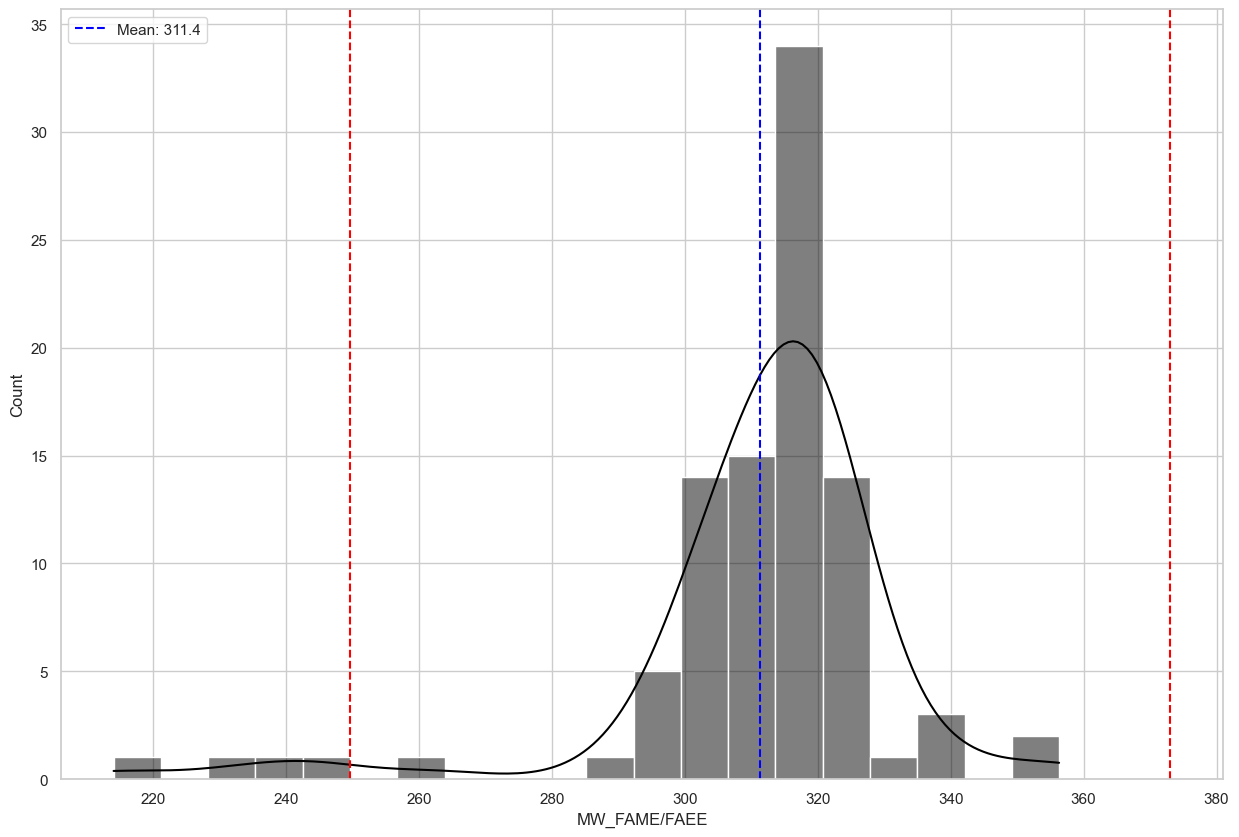

In [69]:
mean_FAME = comps_MW["MW_FAME/FAEE"].mean()
std_FAME = comps_MW["MW_FAME/FAEE"].std()

sns.histplot(x = comps_MW["MW_FAME/FAEE"], color="black", kde=True)
plt.axvline(x=mean_FAME, color="blue", linestyle="--", label = f"Mean: {mean_FAME:.1f}")
plt.axvline(x=mean_FAME + std_FAME*3, color="red", linestyle="--")
plt.axvline(x=mean_FAME - std_FAME*3, color="red", linestyle="--")
plt.legend()
plt.show()

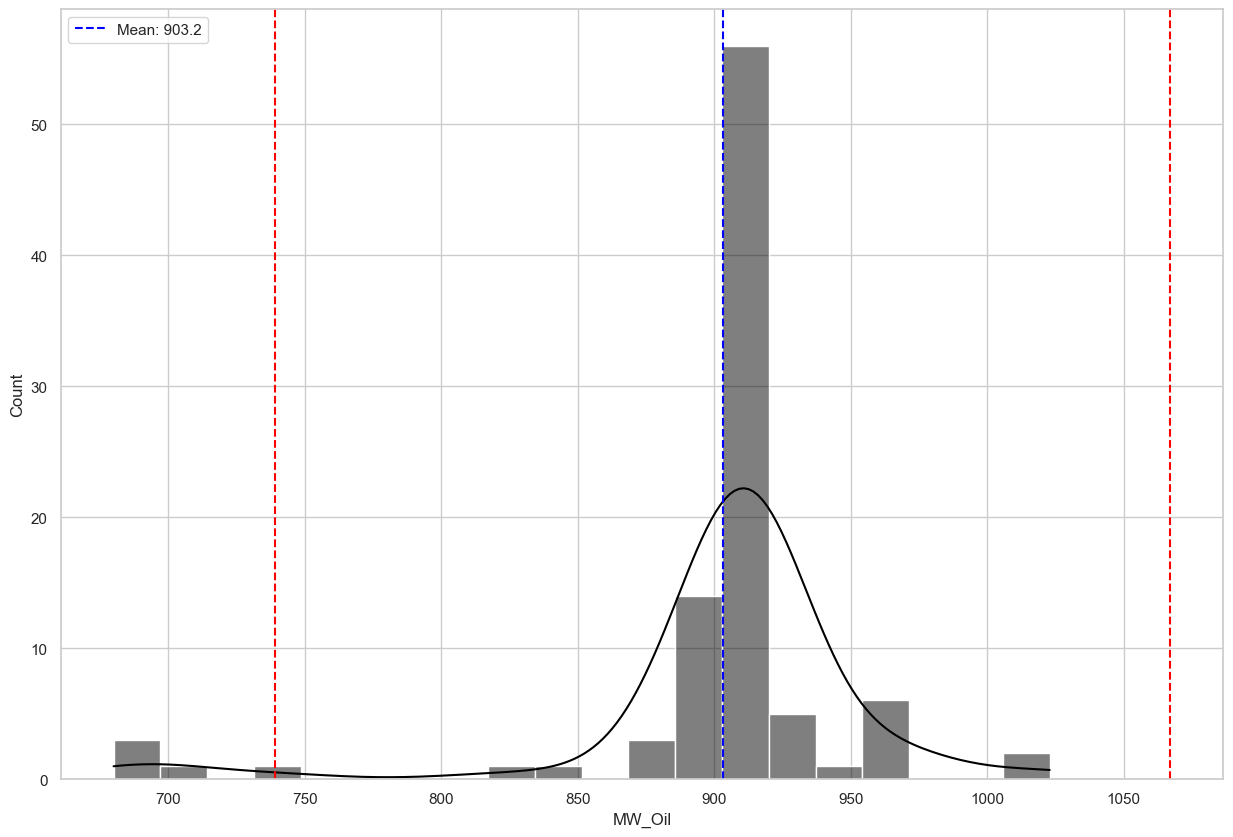

In [70]:
mean_Oil = comps_MW["MW_Oil"].mean()
std_Oil = comps_MW["MW_Oil"].std()
sns.histplot(x = comps_MW["MW_Oil"], color="black", kde=True)
plt.axvline(x=mean_Oil, color="blue", linestyle="--", label = f"Mean: {mean_Oil:.1f}")
plt.axvline(x=mean_Oil + std_Oil*3, color="red", linestyle="--")
plt.axvline(x=mean_Oil - std_Oil*3, color="red", linestyle="--")
plt.legend()
plt.show()

In [71]:
refined_data = refined_data.with_columns(pl.col("Sub Ref").str.slice(0, 1).alias("Sub Ref"))

In [72]:
refined_data.group_by(["Ref", "Sub Ref", "Temperature (K)", "Type Alcohol"]).len()

Ref,Sub Ref,Temperature (K),Type Alcohol,len
i64,str,f64,i64,u32
39,"""b""",298.15,2,14
16,"""a""",318.15,1,6
23,"""c""",298.2,2,5
53,"""a""",303.15,2,4
35,"""a""",283.15,3,4
…,…,…,…,…
56,"""c""",318.15,1,5
35,"""a""",303.15,2,10
32,"""a""",333.15,2,7


In [73]:
result = refined_data.join(
    comps_MW,
    on=["Ref", "Sub Ref"],
    how="left"
)

result = result.with_columns(
    pl.col('Sub Ref').str.slice(0, 1).alias('Sub Ref')
)

In [74]:
base_columns = [
    'FAME/FAEE',
    'GLYCEROL',
    'ALCOHOL',
    'OIL',
    'DAG',
    'MAG',
    'ACID',
    'WATER'
]

# Create the K_ columns with the condition: if _H is 0, then K_ is 0
for col in base_columns:
    col_l = f"{col}_L"
    col_h = f"{col}_H"
    k_col = f"K_{col}"
    
    # Using when/then/otherwise for conditional logic
    result = result.with_columns(
        pl.when(pl.col(col_h) == 0)
        .then(pl.lit(0))
        .otherwise(np.log10(pl.col(col_h) / pl.col(col_l)))
        .alias(k_col)
    )
    
    


c:\Users\RPC\anaconda3\envs\maestria\Lib\site-packages\polars\series\series.py:1571: RuntimeWarning: divide by zero encountered in log10
  lambda out: ufunc(*args, out=out, dtype=dtype_char, **kwargs),


In [75]:
result = result.drop("Type Alcohol_right")

In [76]:
joined_types = result.join(filtered_df, on=["Ref", "Sub Ref"], how="inner")

In [77]:
(joined_types
 .group_by("Source")
 .agg(pl.col("K_OIL").mean().alias("K_OIL_mean"))
 .filter((pl.col("Source")=="Palm") | (pl.col("Source")=="Corn") | (pl.col("Source")=="Cottonseed")| (pl.col("Source")=="Soybean")))

Source,K_OIL_mean
str,f64
"""Cottonseed""",-0.539088
"""Palm""",-0.659617
"""Corn""",-0.444498
"""Soybean""",-0.618019


In [78]:
(joined_types
 .group_by("Source")
 .agg(pl.col("K_OIL").std().alias("K_OIL_std"))
 .filter((pl.col("Source")=="Palm") | (pl.col("Source")=="Corn") | (pl.col("Source")=="Cottonseed")| (pl.col("Source")=="Soybean")))

Source,K_OIL_std
str,f64
"""Soybean""",1.054324
"""Palm""",0.960284
"""Corn""",1.289902
"""Cottonseed""",1.595794


In [79]:
(joined_types
 .group_by("Source")
 .agg(pl.col("K_OIL").min().alias("K_OIL_min"))
 .filter((pl.col("Source")=="Palm") | (pl.col("Source")=="Corn") | (pl.col("Source")=="Cottonseed")| (pl.col("Source")=="Soybean")))

Source,K_OIL_min
str,f64
"""Corn""",-2.324807
"""Soybean""",-4.976828
"""Cottonseed""",-4.960204
"""Palm""",-2.287639


In [80]:
(joined_types
 .group_by("Source")
 .agg(pl.col("K_OIL").max().alias("K_OIL_max"))
 .filter((pl.col("Source")=="Palm") | (pl.col("Source")=="Corn") | (pl.col("Source")=="Cottonseed")| (pl.col("Source")=="Soybean")))

Source,K_OIL_max
str,f64
"""Palm""",0.809108
"""Corn""",2.095884
"""Soybean""",1.242963
"""Cottonseed""",1.093462


In [81]:
with pl.Config(tbl_rows=len(result), tbl_cols=-1):
    print(result.group_by(["Ref", "Sub Ref", "Temperature (K)"], maintain_order=True).agg(pl.col(['K_FAME/FAEE', 'K_GLYCEROL', 'K_ALCOHOL', 'K_OIL', 'K_DAG', 'K_MAG', 'K_ACID','K_WATER']).mean()).write_csv("K_means.csv"))
    print(result.group_by(["Ref", "Sub Ref", "Temperature (K)"], maintain_order=True).agg(pl.col(['K_FAME/FAEE', 'K_GLYCEROL', 'K_ALCOHOL', 'K_OIL', 'K_DAG', 'K_MAG', 'K_ACID','K_WATER']).std()).write_csv("K_std.csv"))
    

None
None


In [82]:
K_means = pl.read_csv("K_means.csv")
K_std = pl.read_csv("K_std.csv")

In [83]:
references = {
    
    '1a': ['B. B. França, F. M. Pinto, F. L. P. Pessoa, and A. M. C. Uller, “Liquid−Liquid Equilibria for Castor Oil Biodiesel + Glycerol + Alcohol,” J Chem Eng Data, vol. 54, no. 9, pp. 2359–2364, Sep. 2009, doi: 10.1021/je800564d.', 
           'Castor oil biodiesel - Methanol - Glycerol'],
    
    '2a': ['F. M. R. Mesquita, A. M. M. Bessa, D. D. de Lima, H. B. de Sant’Ana, and R. S. de Santiago-Aguiar, “Liquid–liquid equilibria of systems containing cottonseed biodiesel+glycerol+ethanol at 293.15, 313.15 and 333.15K,” Fluid Phase Equilib, vol. 318, pp. 51–55, Mar. 2012, doi: 10.1016/j.fluid.2012.01.016', 
           'Cottonseed oil biodiesel - Ethanol - Glycerol'],
    
    '3a': ['R. C. Basso, A. J. de Almeida Meirelles, and E. A. C. Batista, “Liquid–liquid equilibrium of pseudoternary systems containing glycerol+ethanol+ethylic biodiesel from crambe oil (Crambe abyssinica) at T/K=(298.2, 318.2, 338.2) and thermodynamic modeling,” Fluid Phase Equilib, vol. 333, pp. 55–62, Nov. 2012, doi: 10.1016/j.fluid.2012.07.018.', 
           'Cambre oil biodiesel - Ethanol - Glycerol'],
   
    '4a': ['M. Rostami, S. Raeissi, M. Mahmoodi, and M. Nowroozi, “Liquid–Liquid Equilibria in Biodiesel Production,” J Am Oil Chem Soc, vol. 90, no. 1, pp. 147–154, Jan. 2013, doi: 10.1007/s11746-012-2144-5.',
           'Sunflower oil biodiesel - Methanol - Glycerol'],
    
    '5a': ['M. Rostami, S. Raeissi, M. Mahmoodi, and M. Nowroozi, “Liquid–Liquid Equilibria in Biodiesel Production,” J Am Oil Chem Soc, vol. 90, no. 1, pp. 147–154, Jan. 2013, doi: 10.1007/s11746-012-2144-5.', 
           'Canola oil biodiesel - Methanol - Glycerol'], 
    
    '6a': ['X. Liu, X. Piao, Y. Wang, and S. Zhu, “Liquid–Liquid Equilibrium for Systems of (Fatty Acid Ethyl Esters + Ethanol + Soybean Oil and Fatty Acid Ethyl Esters + Ethanol + Glycerol),” J Chem Eng Data, vol. 53, no. 2, pp. 359–362, Feb. 2008, doi: 10.1021/je700382s.',
           'Soybean oil biodiesel - Ethanol - Glycerol'],  
    
    '7a': ['J. R. F. Silva et al., “Thermophysical properties of biodiesel and related systems: (Liquid + liquid) equilibrium data for Jatropha curcas biodiesel,” J Chem Thermodyn, vol. 58, pp. 467–475, Mar. 2013, doi: 10.1016/j.jct.2012.10.006.',
           'Jatropha oil biodiesel - Methanol - Glycerol'],
    
    '8a': ['M. A. Mazutti et al., “Thermophysical properties of biodiesel and related systems: (Liquid + liquid) equilibrium data for soybean biodiesel,” J Chem Thermodyn, vol. 58, pp. 83–94, Mar. 2013, doi: 10.1016/j.jct.2012.10.026.',
           'Soybean oil biodiesel - Methanol - Glycerol'],
    
    '9a': ['A. B. Machado, Y. C. Ardila, L. H. de Oliveira, M. Aznar, and M. R. Wolf Maciel, “Liquid–Liquid Equilibria in Ternary and Quaternary Systems Present in Biodiesel Production from Soybean Oil at (298.2 and 333.2) K,” J Chem Eng Data, vol. 57, no. 5, pp. 1417–1422, May 2012, doi: 10.1021/je201243u.',
           'Soybean oil biodiesel - Ethanol - Glycerol'],
    
    '10a': ['F. M. R. Mesquita, F. X. Feitosa, N. E. Sombra, R. S. de Santiago-Aguiar, and H. B. de Sant’Ana, “Liquid–Liquid Equilibrium for Ternary Mixtures of Biodiesel (Soybean or Sunflower) + Glycerol + Ethanol at Different Temperatures,” J Chem Eng Data, vol. 56, no. 11, pp. 4061–4067, Nov. 2011, doi: 10.1021/je200340x.',
            'Soybean oil biodiesel - Ethanol - Glycerol'],
    
    '10b': ['F. M. R. Mesquita, F. X. Feitosa, N. E. Sombra, R. S. de Santiago-Aguiar, and H. B. de Sant’Ana, “Liquid–Liquid Equilibrium for Ternary Mixtures of Biodiesel (Soybean or Sunflower) + Glycerol + Ethanol at Different Temperatures,” J Chem Eng Data, vol. 56, no. 11, pp. 4061–4067, Nov. 2011, doi: 10.1021/je200340x.',
            'Sunflower oil biodiesel - Ethanol - Glycerol'],
    
    '11a': ['F. M. R. Mesquita, N. S. Evangelista, H. B. de Sant’Ana, and R. S. de Santiago-Aguiar, “Liquid–Liquid Equilibrium for the Glycerol + Alcohol + Coconut Biodiesel System at Different Temperatures and Atmospheric Pressure,” J Chem Eng Data, vol. 57, no. 12, pp. 3557–3562, Dec. 2012, doi: 10.1021/je300749n.',
            'Coconut oil biodiesel - Ethanol - Glycerol'],
    
    '12a': ['L. A. Follegatti-Romero, M. B. Oliveira, F. R. M. Batista, E. A. C. Batista, J. A. P. Coutinho, and A. J. A. Meirelles, “Liquid–liquid equilibria for ternary systems containing ethyl esters, ethanol and glycerol at 323.15 and 353.15K,” Fuel, vol. 94, pp. 386–394, Apr. 2012, doi: 10.1016/j.fuel.2011.09.020.',
            'Linoleic oil biodiesel - Ethanol - Glycerol'],
    
    '12b': ['L. A. Follegatti-Romero, M. B. Oliveira, F. R. M. Batista, E. A. C. Batista, J. A. P. Coutinho, and A. J. A. Meirelles, “Liquid–liquid equilibria for ternary systems containing ethyl esters, ethanol and glycerol at 323.15 and 353.15K,” Fuel, vol. 94, pp. 386–394, Apr. 2012, doi: 10.1016/j.fuel.2011.09.020.',
            'Oleic oil biodiesel - Ethanol - Glycerol'],
    
    '12c': ['L. A. Follegatti-Romero, M. B. Oliveira, F. R. M. Batista, E. A. C. Batista, J. A. P. Coutinho, and A. J. A. Meirelles, “Liquid–liquid equilibria for ternary systems containing ethyl esters, ethanol and glycerol at 323.15 and 353.15K,” Fuel, vol. 94, pp. 386–394, Apr. 2012, doi: 10.1016/j.fuel.2011.09.020.',
            'Palmitic oil biodiesel - Ethanol - Glycerol'],
    
    '12d': ['L. A. Follegatti-Romero, M. B. Oliveira, F. R. M. Batista, E. A. C. Batista, J. A. P. Coutinho, and A. J. A. Meirelles, “Liquid–liquid equilibria for ternary systems containing ethyl esters, ethanol and glycerol at 323.15 and 353.15K,” Fuel, vol. 94, pp. 386–394, Apr. 2012, doi: 10.1016/j.fuel.2011.09.020.',
            'Lauric oil biodiesel - Ethanol - Glycerol'],
           
    '13a': ['R. C. Basso, C. A. S. da Silva, C. de O. Sousa, A. J. de A. Meirelles, and E. A. C. Batista, “LLE experimental data, thermodynamic modeling and sensitivity analysis in the ethyl biodiesel from macauba pulp oil settling step,” Bioresour Technol, vol. 131, pp. 468–475, Mar. 2013, doi: 10.1016/j.biortech.2012.12.190.',
            'Macuba oil biodiesel - Ethanol - Glycerol'],    
    
    '14a': ['H. Zhou, H. Lu, and B. Liang, “Solubility of Multicomponent Systems in the Biodiesel Production by Transesterification of Jatropha c urcas L. Oil with Methanol,” J Chem Eng Data, vol. 51, no. 3, pp. 1130–1135, May 2006, doi: 10.1021/je0600294.',
            'Jatropha oil biodiesel - Methanol - Glycerol'],
    
    '15a': ['M. B. Oliveira, Sérgio. Barbedo, J. I. Soletti, S. H. V. Carvalho, A. J. Queimada, and J. A. P. Coutinho, “Liquid–liquid equilibria for the canola oil biodiesel + ethanol + glycerol system,” Fuel, vol. 90, no. 8, pp. 2738–2745, Aug. 2011, doi: 10.1016/j.fuel.2011.03.017.',
            'Canola oil biodiesel - Methanol - Glycerol'],
    
    '16a': ['M.-J. Lee, Y.-C. Lo, and H.-M. Lin, “Liquid–liquid equilibria for mixtures containing water, methanol, fatty acid methyl esters, and glycerol,” Fluid Phase Equilib, vol. 299, no. 2, pp. 180–190, Dec. 2010, doi: 10.1016/j.fluid.2010.10.010.',
            'Oleic oil biodiesel - Methanol - Glycerol'],
    
    '17a': ['A. B. Machado, Y. C. Ardila, L. H. de Oliveira, M. Aznar, and M. R. Wolf Maciel, “Liquid−Liquid Equilibrium Study in Ternary Castor Oil Biodiesel + Ethanol + Glycerol and Quaternary Castor Oil Biodiesel + Ethanol + Glycerol + NaOH Systems at (298.2 and 333.2) K,” J Chem Eng Data, vol. 56, no. 5, pp. 2196–2201, May 2011, doi: 10.1021/je101235f.',
            'Castor oil biodiesel - Ethanol - Glycerol'],
    
    '18a': ['S. C. Beneti, M. Lanza, M. A. Mazutti, M. H. Kunita, L. Cardozo-Filho, and J. Vladimir Oliveira, “Experimental (liquid+liquid) equilibrium data for ternary and quaternary mixtures of fatty acid methyl and ethyl esters (FAME/FAEE) from soybean oil,” J Chem Thermodyn, vol. 68, pp. 60–70, Jan. 2014, doi: 10.1016/j.jct.2013.08.032.',
            'Soybean oil biodiesel - Methanol - Glycerol'],
    
    '19a': ['M. Rostami, S. Raeissi, M. Ranjbaran, M. Mahmoodi, and M. Nowroozi, “Experimental investigation and modeling of liquid–liquid equilibria in two systems of concern in biodiesel production,” Fluid Phase Equilib, vol. 353, pp. 31–37, Sep. 2013, doi: 10.1016/j.fluid.2013.05.015.',
            'Corn oil biodiesel - Methanol - Glycerol'],
     
    '19b': ['M. Rostami, S. Raeissi, M. Ranjbaran, M. Mahmoodi, and M. Nowroozi, “Experimental investigation and modeling of liquid–liquid equilibria in two systems of concern in biodiesel production,” Fluid Phase Equilib, vol. 353, pp. 31–37, Sep. 2013, doi: 10.1016/j.fluid.2013.05.015.',
            'Frying oil biodiesel - Methanol - Glycerol'],
    
    '20a': ['E. G. de A. Rocha, L. A. Follegatti-Romero, S. Duvoisin, and M. Aznar, “Liquid–liquid equilibria for ternary systems containing ethylic palm oil biodiesel+ethanol+glycerol/water: Experimental data at 298.15 and 323.15K and thermodynamic modeling,” Fuel, vol. 128, pp. 356–365, Jul. 2014, doi: 10.1016/j.fuel.2014.01.074.',
            'Palm oil biodiesel - Ethanol - Glycerol'],
   
    '21a': ['A. L. Esipovich, A. E. Rogozhin, A. S. Belousov, E. A. Kanakov, K. V. Otopkova, and S. M. Danov, “Liquid–liquid equilibrium in the systems FAMEs + vegetable oil + methyl alcohol and FAMEs + glycerol + methyl alcohol,” Fuel, vol. 217, pp. 31–37, Apr. 2018, doi: 10.1016/j.fuel.2017.12.083.',
           'Rapeseed oil biodiesel - Ethanol - Rapeseed oil'],
   
    '22a': ['J. D. S. Serres, D. Soares, M. L. Corazza, N. Krieger, and D. A. Mitchell, “Liquid–liquid equilibrium data and thermodynamic modeling for systems related to the production of ethyl esters of fatty acids from soybean soapstock acid oil,” Fuel, vol. 147, pp. 147–154, May 2015, doi: 10.1016/j.fuel.2015.01.059.',
           'Soybean oil biodiesel - Ethanol - Water'],
   
    '23a': ['R. C. Basso, F. H. Miyake, A. J. de Almeida Meirelles, and E. A. C. Batista, “Liquid–liquid equilibrium data and thermodynamic modeling, at T/K=298.2, in the washing step of ethyl biodiesel production from crambe, fodder radish and macauba pulp oils,” Fuel, vol. 117, pp. 590–597, Jan. 2014, doi: 10.1016/j.fuel.2013.09.020.',
           'Crambe oil biodiesel - Ethanol - Water'],     
    
    '23b': ['R. C. Basso, F. H. Miyake, A. J. de Almeida Meirelles, and E. A. C. Batista, “Liquid–liquid equilibrium data and thermodynamic modeling, at T/K=298.2, in the washing step of ethyl biodiesel production from crambe, fodder radish and macauba pulp oils,” Fuel, vol. 117, pp. 590–597, Jan. 2014, doi: 10.1016/j.fuel.2013.09.020.',
           'Fodder radish oil biodiesel - Ethanol - Water'],     

    '23c': ['R. C. Basso, F. H. Miyake, A. J. de Almeida Meirelles, and E. A. C. Batista, “Liquid–liquid equilibrium data and thermodynamic modeling, at T/K=298.2, in the washing step of ethyl biodiesel production from crambe, fodder radish and macauba pulp oils,” Fuel, vol. 117, pp. 590–597, Jan. 2014, doi: 10.1016/j.fuel.2013.09.020.',
           'Macauba oil biodiesel - Ethanol - Water'],
   
    '24a': ['M. Maghami, J. Yousefi Seyf, S. M. Sadrameli, and A. Haghtalab, “Liquid–liquid phase equilibrium in ternary mixture of waste fish oil biodiesel–methanol–glycerol: Experimental data and thermodynamic modeling,” Fluid Phase Equilib, vol. 409, pp. 124–130, Feb. 2016, doi: 10.1016/j.fluid.2015.09.046.',
           'Waste fish oil biodiesel - Methanol - Glycerol'],      

    '25a': ['J. D. Gonçalves, M. Aznar, and G. R. Santos, “Liquid–liquid equilibrium data for systems containing Brazil nut biodiesel+methanol+glycerin at 303.15K and 323.15K,” Fuel, vol. 133, pp. 292–298, Oct. 2014, doi: 10.1016/j.fuel.2014.05.004.',
           'Brazil nut oil biodiesel - Methanol - Glycerol'],
    
    '26a': ['M. Hakim, H. Abedini Najafabadi, G. Pazuki, and M. Vossoughi, “Novel Approach for Liquid–Liquid Phase Equilibrium of Biodiesel (Canola and Sunflower) + Glycerol + Methanol,” Ind Eng Chem Res, vol. 53, no. 2, pp. 855–864, Jan. 2014, doi: 10.1021/ie4031902.',
            'Canola oil biodiesel - Methanol - Glycerol'],
    
    '26b': ['M. Hakim, H. Abedini Najafabadi, G. Pazuki, and M. Vossoughi, “Novel Approach for Liquid–Liquid Phase Equilibrium of Biodiesel (Canola and Sunflower) + Glycerol + Methanol,” Ind Eng Chem Res, vol. 53, no. 2, pp. 855–864, Jan. 2014, doi: 10.1021/ie4031902.',
            'Sunflower oil biodiesel - Methanol - Glycerol'],

    '27a': ['M. A. Mazutti et al., “Thermophysical properties of biodiesel and related systems: (Liquid+liquid) equilibrium data for castor oil biodiesel,” J Chem Thermodyn, vol. 62, pp. 17–26, Jul. 2013, doi: 10.1016/j.jct.2013.02.016.',
            'Castor oil biodiesel - Methanol/Ethanol - Glycerol - Water'],
    
    '28a': ['B. B. França, H. G. D. Villardi, F. L. P. Pessoa, and A. M. C. Uller, “Liquid–Liquid Equilibrium for Compounds of Soybean Ethyl Biodiesel Production by Transesterification,” J Chem Eng Data, vol. 58, no. 7, pp. 1927–1933, Jul. 2013, doi: 10.1021/je301313c.',
            'Soybean oil biodiesel - Ethanol - Glycerol - Water'],
    
    '29a': ['E. Batista, S. Monnerat, L. Stragevitch, C. G. Pina, C. B. Gonçalves, and A. J. A. Meirelles, “Prediction of Liquid−Liquid Equilibrium for Systems of Vegetable Oils, Fatty Acids, and Ethanol,” J Chem Eng Data, vol. 44, no. 6, pp. 1365–1369, Nov. 1999, doi: 10.1021/je9900169.',
            'Triolein - Ethanol - Oleic acid'],
    
    '29b': ['E. Batista, S. Monnerat, L. Stragevitch, C. G. Pina, C. B. Gonçalves, and A. J. A. Meirelles, “Prediction of Liquid−Liquid Equilibrium for Systems of Vegetable Oils, Fatty Acids, and Ethanol,” J Chem Eng Data, vol. 44, no. 6, pp. 1365–1369, Nov. 1999, doi: 10.1021/je9900169.',
            'Corn oil - Ethanol - Oleic acid'],    
    
    '30a': ['C. E. C. Rodrigues, É. C. D. Reipert, A. F. de Souza, P. A. P. Filho, and A. J. A. Meirelles, “Equilibrium data for systems composed by cottonseed oil+commercial linoleic acid+ethanol+water+tocopherols at 298.2K,” Fluid Phase Equilib, vol. 238, no. 2, pp. 193–203, Dec. 2005, doi: 10.1016/j.fluid.2005.09.027.',
            'Refined cottonseed oil - Ethanol - Linoelic acid - Water'],
     
    '30b': ['C. E. C. Rodrigues, É. C. D. Reipert, A. F. de Souza, P. A. P. Filho, and A. J. A. Meirelles, “Equilibrium data for systems composed by cottonseed oil+commercial linoleic acid+ethanol+water+tocopherols at 298.2K,” Fluid Phase Equilib, vol. 238, no. 2, pp. 193–203, Dec. 2005, doi: 10.1016/j.fluid.2005.09.027.',
            'Pretreated cottonseed oil - Ethanol - Linoelic acid - Water'],
    
    '31a': ['C. E. C. Rodrigues, R. Antoniassi, and A. J. A. Meirelles, “Equilibrium Data for the System Rice Bran Oil + Fatty Acids + Ethanol + Water at 298.2 K,” J Chem Eng Data, vol. 48, no. 2, pp. 367–373, Mar. 2003, doi: 10.1021/je0255978.',
            'Rice bran oil - Ethanol - Oelic acid - Water'],
    
    '32a': ['C. M. Oliveira, B. R. Garavazo, and C. E. C. Rodrigues, “Liquid–liquid equilibria for systems composed of rice bran oil and alcohol-rich solvents: Application to extraction and deacidification of oil,” J Food Eng, vol. 110, no. 3, pp. 418–427, Jun. 2012, doi: 10.1016/j.jfoodeng.2011.12.027.',
            'Rice bran oil - Ethanol - Free Fatty Acids - Water'],
    
    '33a': ['C. B. Gonçalves, E. Batista, and A. J. A. Meirelles, “Liquid−Liquid Equilibrium Data for the System Corn Oil + Oleic Acid + Ethanol + Water at 298.15 K,” J Chem Eng Data, vol. 47, no. 3, pp. 416–420, May 2002, doi: 10.1021/je010273p.',
            'Corn oil - Oleic acid - Ethanol - Water'],
    
    '34a': ['C. B. Gonçalves and A. J. A. Meirelles, “Liquid–liquid equilibrium data for the system palm oil + fatty acids + ethanol + water at 318.2 K,” Fluid Phase Equilib, vol. 221, no. 1–2, pp. 139–150, Jul. 2004, doi: 10.1016/j.fluid.2004.05.002.',
            'Palm oil - Palmitic acid - Ethanol - Water'],
    
    '34b': ['C. B. Gonçalves and A. J. A. Meirelles, “Liquid–liquid equilibrium data for the system palm oil + fatty acids + ethanol + water at 318.2 K,” Fluid Phase Equilib, vol. 221, no. 1–2, pp. 139–150, Jul. 2004, doi: 10.1016/j.fluid.2004.05.002.',
            'Palm oil - Oleic acid - Ethanol - Water'],
    
    '35a': ['E. Batista, S. Monnerat, K. Kato, L. Stragevitch, and A. J. A. Meirelles, “Liquid−Liquid Equilibrium for Systems of Canola Oil, Oleic Acid, and Short-Chain Alcohols,” J Chem Eng Data, vol. 44, no. 6, pp. 1360–1364, Nov. 1999, doi: 10.1021/je990015g.',
            'Canola oil - Oleic acid - Methanol/Ethanol/Propanol'],
    
    '36a': ['G. F. Hirata, C. R. A. Abreu, L. C. B. A. Bessa, M. C. Ferreira, E. A. C. Batista, and A. J. A. Meirelles, “Liquid–liquid equilibrium of fatty systems: A new approach for adjusting UNIFAC interaction parameters,” Fluid Phase Equilib, vol. 360, pp. 379–391, Dec. 2013, doi: 10.1016/j.fluid.2013.10.004.',
            'Mixed oil - Oleic acid - Ethanol'],
    
    '37a': ['C. E. C. Rodrigues, A. Filipini, and A. J. A. Meirelles, “Phase Equilibrium for Systems Composed by High Unsaturated Vegetable Oils + Linoleic Acid + Ethanol + Water at 298.2 K,” J Chem Eng Data, vol. 51, no. 1, pp. 15–21, Jan. 2006, doi: 10.1021/je0495841.',
            'Garlic oil - Linoleic acid - Ethanol - Water'],
    
    '37b': ['C. E. C. Rodrigues, A. Filipini, and A. J. A. Meirelles, “Phase Equilibrium for Systems Composed by High Unsaturated Vegetable Oils + Linoleic Acid + Ethanol + Water at 298.2 K,” J Chem Eng Data, vol. 51, no. 1, pp. 15–21, Jan. 2006, doi: 10.1021/je0495841.',
            'Grape seed oil - Linoleic acid - Ethanol - Water'],
    
    '37c': ['C. E. C. Rodrigues, A. Filipini, and A. J. A. Meirelles, “Phase Equilibrium for Systems Composed by High Unsaturated Vegetable Oils + Linoleic Acid + Ethanol + Water at 298.2 K,” J Chem Eng Data, vol. 51, no. 1, pp. 15–21, Jan. 2006, doi: 10.1021/je0495841.',
            'Sesame oil - Linoleic acid - Ethanol - Water'],
    
    '38a': ['C. E. C. Rodrigues, E. C. D. Peixoto, and A. J. A. Meirelles, “Phase equilibrium for systems composed by refined soybean oil+commercial linoleic acid+ethanol+water, at 323.2K,” Fluid Phase Equilib, vol. 261, no. 1–2, pp. 122–128, Dec. 2007, doi: 10.1016/j.fluid.2007.07.021.',
            'Refined Soybean oil - Linoleic acid - Ethanol - Water'],
    
    '39a': ['C. E. C. Rodrigues and A. J. A. Meirelles, “Extraction of Free Fatty Acids from Peanut Oil and Avocado Seed Oil: Liquid−Liquid Equilibrium Data at 298.2 K,” J Chem Eng Data, vol. 53, no. 8, pp. 1698–1704, Aug. 2008, doi: 10.1021/je7007186.', 
            'Peanut oil - Oleic acid - Ethanol - Water'],
    
    '39b': ['C. E. C. Rodrigues and A. J. A. Meirelles, “Extraction of Free Fatty Acids from Peanut Oil and Avocado Seed Oil: Liquid−Liquid Equilibrium Data at 298.2 K,” J Chem Eng Data, vol. 53, no. 8, pp. 1698–1704, Aug. 2008, doi: 10.1021/je7007186.', 
            'Avocado Seed oil - Oleic acid - Ethanol - Water'],
    
    '40a': ['M. Mohsen-Nia and A. Khodayari, “De-acidification of sunflower oil by solvent extraction: (Liquid+liquid) equilibrium data at T=(303.15 and 313.15)K,” J Chem Thermodyn, vol. 40, no. 8, pp. 1325–1329, Aug. 2008, doi: 10.1016/j.jct.2008.01.029.',
            'Sunflower oil - Oleic acid - Methanol/Ethanol'],
    
    '41a': ['M. Mohsen‐Nia, H. Modarress, and H. R. Nabavi, “Measuring and Modeling Liquid–Liquid Equilibria for a Soybean Oil, Oleic Acid, Ethanol, and Water System,” J Am Oil Chem Soc, vol. 85, no. 10, pp. 973–978, Oct. 2008, doi: 10.1007/s11746-008-1288-9.',
            'Soybean oil - Oleic acid - Methanol/Ethanol - Water'],
    
    '42a': ['C. E. C. Rodrigues, F. A. Silva, A. Marsaioli, and A. J. A. Meirelles, “Deacidification of Brazil Nut and Macadamia Nut Oils by Solvent Extraction:  Liquid−Liquid Equilibrium Data at 298.2 K,” J Chem Eng Data, vol. 50, no. 2, pp. 517–523, Mar. 2005, doi: 10.1021/je049687j.',
            'Brazil Nut oil - Oleic acid - Ethanol - Water'],
    
    '42b': ['C. E. C. Rodrigues, F. A. Silva, A. Marsaioli, and A. J. A. Meirelles, “Deacidification of Brazil Nut and Macadamia Nut Oils by Solvent Extraction:  Liquid−Liquid Equilibrium Data at 298.2 K,” J Chem Eng Data, vol. 50, no. 2, pp. 517–523, Mar. 2005, doi: 10.1021/je049687j.',
            'Macadamia Nut oil - Oleic acid - Ethanol - Water'],
    
    '43a': ['M. Mohsen-Nia and Mahdi. Dargahi, “Liquid−Liquid Equilibrium for Systems of (Corn Oil + Oleic Acid + Methanol or Ethanol) at (303.15 and 313.15) K,” J Chem Eng Data, vol. 52, no. 3, pp. 910–914, May 2007, doi: 10.1021/je700051j.',
            'Corn oil - Oleic acid - Methanol/Ethanol'],
    
    '44a': ['G. Sanaiotti, J. S. R. Coimbra, J. C. Gomes, and L. A. Minim, “Liquid−Liquid Equilibrium for Systems Composed of Grape Seed Oil + Oleic Acid + Ethanol + Water at (283.2, 290.7, and 298.2) K,” J Chem Eng Data, vol. 53, no. 7, pp. 1492–1497, Jul. 2008, doi: 10.1021/je800034c.',
            'Crude grape seed oil - Oleic acid - Ethanol - Water'],
    
    '44b': ['G. Sanaiotti, J. S. R. Coimbra, J. C. Gomes, and L. A. Minim, “Liquid−Liquid Equilibrium for Systems Composed of Grape Seed Oil + Oleic Acid + Ethanol + Water at (283.2, 290.7, and 298.2) K,” J Chem Eng Data, vol. 53, no. 7, pp. 1492–1497, Jul. 2008, doi: 10.1021/je800034c.',
            'Refined grape seed oil - Oleic acid - Ethanol - Water'],
    
    '45a': ['M. Mohsen‐Nia, H. Modarress, and H. R. Nabavi, “Measuring and Modeling Liquid–Liquid Equilibria for a Soybean Oil, Oleic Acid, Ethanol, and Water System,” J Am Oil Chem Soc, vol. 85, no. 10, pp. 973–978, Oct. 2008, doi: 10.1007/s11746-008-1288-9.', 
            'Soybean oil - Oleic acid - Ethanol - Water'],
    
    '46a': ['É. C. D. Reipert, C. E. C. Rodrigues, and A. J. A. Meirelles, “Phase equilibria study of systems composed of refined babassu oil, lauric acid, ethanol, and water at 303.2K,” J Chem Thermodyn, vol. 43, no. 12, pp. 1784–1790, Dec. 2011, doi: 10.1016/j.jct.2011.05.039.',
            'Babassu oil - Lauric acid - Ethanol - Water'],
    
    '47a': ['X. Huang et al., “Liquid–liquid equilibrium of binary and ternary systems composed by palm oil or palm oil fractions with methanol/ethanol and water,” Fluid Phase Equilib, vol. 404, pp. 17–25, Oct. 2015, doi: 10.1016/j.fluid.2015.06.028.',
             'Refined Palm oil - Ethanol/Methanol - Waterl'],
    
    '47b': ['X. Huang et al., “Liquid–liquid equilibrium of binary and ternary systems composed by palm oil or palm oil fractions with methanol/ethanol and water,” Fluid Phase Equilib, vol. 404, pp. 17–25, Oct. 2015, doi: 10.1016/j.fluid.2015.06.028.',
             'Refined palm olein - Ethanol/Methanol- Water'],
    
    '47c': ['X. Huang et al., “Liquid–liquid equilibrium of binary and ternary systems composed by palm oil or palm oil fractions with methanol/ethanol and water,” Fluid Phase Equilib, vol. 404, pp. 17–25, Oct. 2015, doi: 10.1016/j.fluid.2015.06.028.',
             'Refined palm stearin - Ethanol/Methanol- Water'],
    
    '48a': ['Y. C. Ardila, A. B. Machado, G. M. F. Pinto, R. M. Filho, and M. R. W. Maciel, “Liquid–Liquid Equilibrium in Ternary Systems Present in Biodiesel Purification from Soybean Oil and Castor Oil at (298.2 and 333.2) K,” J Chem Eng Data, vol. 58, no. 3, pp. 605–610, Mar. 2013, doi: 10.1021/je301028r.',
            'Soybean oil biodiesel - Ethanol - Water'],
    
    '48b': ['Y. C. Ardila, A. B. Machado, G. M. F. Pinto, R. M. Filho, and M. R. W. Maciel, “Liquid–Liquid Equilibrium in Ternary Systems Present in Biodiesel Purification from Soybean Oil and Castor Oil at (298.2 and 333.2) K,” J Chem Eng Data, vol. 58, no. 3, pp. 605–610, Mar. 2013, doi: 10.1021/je301028r.',
            'Castor oil biodiesel - Ethanol - Water'],
    
    '49a': ['S. Shiozawa, D. Gonçalves, M. C. Ferreira, A. J. A. Meirelles, and E. A. C. Batista, “Liquid-liquid equilibrium data and thermodynamic modeling of systems involved in the biodiesel production in terms of acylglycerols, free fatty acids, ethyl esters, and ethanol at 303.2 and 318.2 K and local pressure,” Fluid Phase Equilib, vol. 507, p. 112431, Mar. 2020, doi: 10.1016/j.fluid.2019.112431.',
            'Soybean oil - Ethyl linoleate - Linoleic acid - DAG - MAG - Ethanol'],

    '49b': ['S. Shiozawa, D. Gonçalves, M. C. Ferreira, A. J. A. Meirelles, and E. A. C. Batista, “Liquid-liquid equilibrium data and thermodynamic modeling of systems involved in the biodiesel production in terms of acylglycerols, free fatty acids, ethyl esters, and ethanol at 303.2 and 318.2 K and local pressure,” Fluid Phase Equilib, vol. 507, p. 112431, Mar. 2020, doi: 10.1016/j.fluid.2019.112431.',
            'Cottonseed oil - Ethyl linoleate - Linoleic acid - DAG - MAG - Ethanol'],
    
    '49c': ['S. Shiozawa, D. Gonçalves, M. C. Ferreira, A. J. A. Meirelles, and E. A. C. Batista, “Liquid-liquid equilibrium data and thermodynamic modeling of systems involved in the biodiesel production in terms of acylglycerols, free fatty acids, ethyl esters, and ethanol at 303.2 and 318.2 K and local pressure,” Fluid Phase Equilib, vol. 507, p. 112431, Mar. 2020, doi: 10.1016/j.fluid.2019.112431.',
            'Rice bran oil - Ethyl oleate - Oleic acid - Ethyl linoleate - Linoleic acid - DAG - MAG - Ethanol'],
    
    '50a': ['M. C. Ferreira, D. Gonçalves, L. C. B. A. Bessa, A. J. A. Meirelles, and E. A. C. Batista, “Performance of different UNIFAC parameter sets in describing experimental liquid–liquid equilibrium data of biodiesel systems,” J Mol Liq, vol. 383, p. 122022, Aug. 2023, doi: 10.1016/j.molliq.2023.122022.',
            'Olive oil - Capric acid - DAG - MAG - Ethanol'],
    
    '50b': ['M. C. Ferreira, D. Gonçalves, L. C. B. A. Bessa, A. J. A. Meirelles, and E. A. C. Batista, “Performance of different UNIFAC parameter sets in describing experimental liquid–liquid equilibrium data of biodiesel systems,” J Mol Liq, vol. 383, p. 122022, Aug. 2023, doi: 10.1016/j.molliq.2023.122022.',
            'Sunflower oil - DAG - MAG - Ethanol'],  
    
    '50c': ['M. C. Ferreira, D. Gonçalves, L. C. B. A. Bessa, A. J. A. Meirelles, and E. A. C. Batista, “Performance of different UNIFAC parameter sets in describing experimental liquid–liquid equilibrium data of biodiesel systems,” J Mol Liq, vol. 383, p. 122022, Aug. 2023, doi: 10.1016/j.molliq.2023.122022.',
            'Coconut oil - Caporic ester - Ethanol'],  
    
    '51a': ['J. C. G. Filho et al., “Liquid–Liquid Equilibrium Measurement and Thermodynamic Modeling of the { Sterculia striata Biodiesel + Glycerol + Ethanol} System,” J Chem Eng Data, vol. 66, no. 8, pp. 3293–3299, Aug. 2021, doi: 10.1021/acs.jced.1c00341.',
            'Chicha oil biodiesel - Ethanol - Glycerol'],
     
    '52a': ['A. Asoodeh, F. Eslami, and S. M. Sadrameli, “Liquid–liquid equilibria of systems containing linseed oil biodiesel + methanol + glycerol: Experimental data and thermodynamic modeling,” Fuel, vol. 253, pp. 460–473, Oct. 2019, doi: 10.1016/j.fuel.2019.04.170.',
            'Linseed oil biodiesel - Methanol - Glycerol'], 
    
    '53a': ['I. E. P. Toledo et al., “Liquid–Liquid Equilibrium of the System {Peanut Biodiesel + Glycerol + Ethanol} at Atmospheric Pressure,” J Chem Eng Data, vol. 64, no. 5, pp. 2207–2212, May 2019, doi: 10.1021/acs.jced.8b01185.',
            'Penaut oil biodiesel - Ethanol - Glycerol'], 
     
    '54a': ['J. C. Nunes et al., “Experimental Data and Phase Equilibrium Modeling in Ternary and Pseudoquaternary Systems of Sunflower Oil for Biodiesel Production,” J Chem Eng Data, vol. 64, no. 2, pp. 412–420, Feb. 2019, doi: 10.1021/acs.jced.8b00276.',
            'Refined sunflower oil biodiesel - Methanol - Glycerol - Water'],
    
    '55a': ['S. Shiozawa, M. C. Ferreira, D. Gonçalves, A. J. A. Meirelles, and E. A. C. Batista, “Liquid–Liquid Equilibrium Data for Systems Involving Triacylglycerols from (Soybean, Cottonseed, or Rice Bran) Oil + Partial Acylglycerols + Anhydrous Ethanol at T = 303.2 and 318.2 K,” J Chem Eng Data, vol. 64, no. 5, pp. 2153–2162, May 2019, doi: 10.1021/acs.jced.8b01119.',
            'Refined soybean oil biodiesel - DAG - MAG - Ethanol'],
    
    '55b': ['S. Shiozawa, M. C. Ferreira, D. Gonçalves, A. J. A. Meirelles, and E. A. C. Batista, “Liquid–Liquid Equilibrium Data for Systems Involving Triacylglycerols from (Soybean, Cottonseed, or Rice Bran) Oil + Partial Acylglycerols + Anhydrous Ethanol at T = 303.2 and 318.2 K,” J Chem Eng Data, vol. 64, no. 5, pp. 2153–2162, May 2019, doi: 10.1021/acs.jced.8b01119.',
            'Refined cottonseed oil biodiesel - DAG - MAG - Ethanol'],
    
    '55c': ['S. Shiozawa, M. C. Ferreira, D. Gonçalves, A. J. A. Meirelles, and E. A. C. Batista, “Liquid–Liquid Equilibrium Data for Systems Involving Triacylglycerols from (Soybean, Cottonseed, or Rice Bran) Oil + Partial Acylglycerols + Anhydrous Ethanol at T = 303.2 and 318.2 K,” J Chem Eng Data, vol. 64, no. 5, pp. 2153–2162, May 2019, doi: 10.1021/acs.jced.8b01119.',
            'Refined rice bran oil biodiesel - DAG - MAG - Ethanol'],
    
    '56a': ['B. Khdir and H. Amin, “DETERMINATION AND MODELLING OF LIQUID-LIQUID PHASE EQUILIBRIUM FOR TERNARY SYSTEMS IN BIODIESEL PRODUCTION FROM VEGETABLE OIL AND ANIMAL FAT MIXTURES,” 2019.',
            'Sunflower oil biodiesel - Methanol - Glycerol'],
    
    '56b': ['B. Khdir and H. Amin, “DETERMINATION AND MODELLING OF LIQUID-LIQUID PHASE EQUILIBRIUM FOR TERNARY SYSTEMS IN BIODIESEL PRODUCTION FROM VEGETABLE OIL AND ANIMAL FAT MIXTURES,” 2019.',
            '10 % Beef Tallow/Sunflower oil biodiesel - Methanol - Glycerol'],
    
    '56c': ['B. Khdir and H. Amin, “DETERMINATION AND MODELLING OF LIQUID-LIQUID PHASE EQUILIBRIUM FOR TERNARY SYSTEMS IN BIODIESEL PRODUCTION FROM VEGETABLE OIL AND ANIMAL FAT MIXTURES,” 2019.',
            '20 % Beef Tallow/Sunflower oil biodiesel - Methanol - Glycerol'],     
    
    '57a': ['O. Z. Sampaio Neto, D. Gonçalves, S. de F. Bergara, E. A. C. Batista, and A. J. de A. Meirelles, “Oil extraction from semi-defatted babassu bagasse with ethanol: Liquid-liquid equilibrium and solid-liquid extraction in a single stage,” J Food Eng, vol. 276, p. 109845, Jul. 2020, doi: 10.1016/j.jfoodeng.2019.109845.',
            'Babassu oil - Ethanol - Water'],
}


In [84]:
K_means

Ref,Sub Ref,Temperature (K),K_FAME/FAEE,K_GLYCEROL,K_ALCOHOL,K_OIL,K_DAG,K_MAG,K_ACID,K_WATER
i64,str,f64,f64,f64,f64,f64,f64,f64,f64,f64
1,"""a""",298.15,-3.771973,1.774681,0.443974,0.0,0.0,0.0,0.0,0.0
2,"""a""",293.15,-1.547369,1.489367,0.344377,0.0,0.0,0.0,0.0,0.0
2,"""a""",313.15,-1.467624,1.516076,0.348083,0.0,0.0,0.0,0.0,0.0
2,"""a""",333.15,-1.301788,1.49818,0.366508,0.0,0.0,0.0,0.0,0.0
3,"""a""",298.15,-1.801037,1.586721,0.536663,0.0,0.0,0.0,0.0,0.0
…,…,…,…,…,…,…,…,…,…,…
56,"""c""",308.15,-1.9984,2.037257,0.945567,0.0,0.0,0.0,0.0,0.0
56,"""c""",318.15,-2.168477,1.902229,0.774302,0.0,0.0,0.0,0.0,0.0
57,"""a""",298.2,0.0,0.0,0.750887,-1.012389,0.0,0.0,0.0,1.18829


In [85]:
K_std

Ref,Sub Ref,Temperature (K),K_FAME/FAEE,K_GLYCEROL,K_ALCOHOL,K_OIL,K_DAG,K_MAG,K_ACID,K_WATER
i64,str,f64,f64,f64,f64,f64,f64,f64,f64,f64
1,"""a""",298.15,1.184022,0.375362,0.028471,0.0,0.0,0.0,0.0,0.0
2,"""a""",293.15,0.020673,0.033558,0.047616,0.0,0.0,0.0,0.0,0.0
2,"""a""",313.15,0.042914,0.079434,0.034139,0.0,0.0,0.0,0.0,0.0
2,"""a""",333.15,0.018636,0.096404,0.034463,0.0,0.0,0.0,0.0,0.0
3,"""a""",298.15,0.662183,0.38444,0.071368,0.0,0.0,0.0,0.0,0.0
…,…,…,…,…,…,…,…,…,…,…
56,"""c""",308.15,0.282445,0.155961,0.088824,0.0,0.0,0.0,0.0,0.0
56,"""c""",318.15,0.186406,0.191471,0.098116,0.0,0.0,0.0,0.0,0.0
57,"""a""",298.2,0.0,0.0,0.119046,0.219438,0.0,0.0,0.0,0.218104


In [86]:
import polars as pl
import numpy as np

# Assuming your dataframes are named df_means and df_stds
# For a 95% confidence interval, z-score = 1.96

# Join the two dataframes on the Systems column
df_combined = K_means.join(K_std, on="Systems", suffix="_std")

# Columns to calculate CI for
value_columns = ["K_FAME/FAEE", "K_GLYCEROL", "K_ALCOHOL", "K_OIL", 
                 "K_DAG", "K_MAG", "K_ACID", "K_WATER"]

# Calculate lower and upper bounds for each column
ci_expressions = []

for col in value_columns:
    mean_col = col
    std_col = f"{col}_std"
    
    # Calculate margin of error: 1.96 * std
    # Lower bound: mean - margin
    # Upper bound: mean + margin
    ci_expressions.extend([
        (pl.col(mean_col) - 1.96 * pl.col(std_col)).alias(f"{col}_CI_LOWER"),
        (pl.col(mean_col) + 1.96 * pl.col(std_col)).alias(f"{col}_CI_UPPER")
    ])



df_ci_full = df_combined.select([
    pl.col("Systems"),
    *[pl.col(col) for col in value_columns],  # means
    *[pl.col(f"{col}_std") for col in value_columns],  # stds
    *ci_expressions  # confidence intervals
])

print(df_ci_full)


ColumnNotFoundError: unable to find column "Systems"; valid columns: ["Ref", "Sub Ref", "Temperature (K)", "K_FAME/FAEE", "K_GLYCEROL", "K_ALCOHOL", "K_OIL", "K_DAG", "K_MAG", "K_ACID", "K_WATER"]

In [29]:
df_ci_full

Systems,K_FAME/FAEE,K_GLYCEROL,K_ALCOHOL,K_OIL,K_DAG,K_MAG,K_ACID,K_WATER,K_FAME/FAEE_std,K_GLYCEROL_std,K_ALCOHOL_std,K_OIL_std,K_DAG_std,K_MAG_std,K_ACID_std,K_WATER_std,K_FAME/FAEE_CI_LOWER,K_FAME/FAEE_CI_UPPER,K_GLYCEROL_CI_LOWER,K_GLYCEROL_CI_UPPER,K_ALCOHOL_CI_LOWER,K_ALCOHOL_CI_UPPER,K_OIL_CI_LOWER,K_OIL_CI_UPPER,K_DAG_CI_LOWER,K_DAG_CI_UPPER,K_MAG_CI_LOWER,K_MAG_CI_UPPER,K_ACID_CI_LOWER,K_ACID_CI_UPPER,K_WATER_CI_LOWER,K_WATER_CI_UPPER
str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""Palm oil biodiesel - Ethanol -…",-2.061662,1.633562,0.528448,0.0,0.0,0.0,0.0,0.0,0.284109,0.091567,0.057935,0.0,0.0,0.0,0.0,0.0,-2.618515,-1.504809,1.454092,1.813033,0.414895,0.642001,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
"""Palm oil biodiesel - Ethanol -…",-1.703731,1.438161,0.543234,0.0,0.0,0.0,0.0,0.0,0.284109,0.091567,0.057935,0.0,0.0,0.0,0.0,0.0,-2.260584,-1.146878,1.25869,1.617632,0.429681,0.656787,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
"""20 % Beef Tallow/Sunflower oil…",-1.9984,2.037257,0.945567,0.0,0.0,0.0,0.0,0.0,0.50204,0.356364,0.111903,0.0,0.0,0.0,0.0,0.0,-2.982398,-1.014402,1.338783,2.73573,0.726237,1.164896,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
"""20 % Beef Tallow/Sunflower oil…",-2.168477,1.902229,0.774302,0.0,0.0,0.0,0.0,0.0,0.50204,0.356364,0.111903,0.0,0.0,0.0,0.0,0.0,-3.152476,-1.184479,1.203756,2.600702,0.554973,0.993632,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
"""20 % Beef Tallow/Sunflower oil…",-2.313065,2.318899,0.922977,0.0,0.0,0.0,0.0,0.0,0.50204,0.356364,0.111903,0.0,0.0,0.0,0.0,0.0,-3.297063,-1.329067,1.620426,3.017372,0.703648,1.142306,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
"""Palm oil - Oleic acid - Ethano…",0.0,0.0,0.694145,-1.546283,0.0,0.0,-0.065592,0.661977,0.0,0.0,0.415239,0.88701,0.0,0.0,0.072984,0.290228,0.0,0.0,0.0,0.0,-0.119723,1.508013,-3.284822,0.192256,0.0,0.0,0.0,0.0,-0.20864,0.077456,0.09313,1.230824
"""Corn oil - Oleic acid - Methan…",0.0,0.0,-0.937571,1.477646,0.0,0.0,-0.018701,0.0,0.0,0.0,0.43355,0.569021,0.0,0.0,0.052854,0.0,0.0,0.0,0.0,0.0,-1.787328,-0.087814,0.362364,2.592927,0.0,0.0,0.0,0.0,-0.122295,0.084893,0.0,0.0
"""Corn oil - Oleic acid - Methan…",0.0,0.0,-0.928851,1.364206,0.0,0.0,-0.03042,0.0,0.0,0.0,0.43355,0.569021,0.0,0.0,0.052854,0.0,0.0,0.0,0.0,0.0,-1.778608,-0.079094,0.248925,2.479488,0.0,0.0,0.0,0.0,-0.134014,0.073173,0.0,0.0


In [87]:
import polars as pl
from scipy import stats
import numpy as np

# Specify your sample size
n = 3  # Replace with your actual sample size

# Calculate the t-critical value for 95% CI with (n-1) degrees of freedom
t_critical = stats.t.ppf(0.975, df=n-1)

# Join the two dataframes on the Systems column
df_combined = K_means.join(K_std, on="Systems", suffix="_std")

# Columns to calculate CI for (excluding Temperature)
value_columns = ["K_FAME/FAEE", "K_GLYCEROL", "K_ALCOHOL", "K_OIL", 
                 "K_DAG", "K_MAG", "K_ACID", "K_WATER"]

# Calculate the margin of error for each column
margin_expressions = []

for col in value_columns:
    mean_col = col
    std_col = f"{col}_std"
    
    # Margin of error: t_critical * (std / sqrt(n))
    margin_expressions.append(
        (t_critical * pl.col(std_col) / np.sqrt(n)).alias(f"{col}_margin")
    )

# Create dataframe with margins
df_with_margins = df_combined.select([
    pl.col("Systems"),
    pl.col("Temperature (K)"),  # Include temperature as-is
    *[pl.col(col) for col in value_columns],
    *margin_expressions
])

# Create the "mean ± margin" format dataframe
formatted_expressions = []

for col in value_columns:
    mean_col = col
    margin_col = f"{col}_margin"
    
    # Format as "mean ± margin" with 4 decimals
    formatted_expressions.append(
        (pl.col(mean_col).round(4).cast(pl.Utf8) + " ± " + 
         pl.col(margin_col).round(4).cast(pl.Utf8)).alias(col)
    )

df_formatted = df_with_margins.select([
    pl.col("Systems"),
    pl.col("Temperature (K)").round(4),  # Temperature with 4 decimals
    *formatted_expressions
])

ColumnNotFoundError: unable to find column "Systems"; valid columns: ["Ref", "Sub Ref", "Temperature (K)", "K_FAME/FAEE", "K_GLYCEROL", "K_ALCOHOL", "K_OIL", "K_DAG", "K_MAG", "K_ACID", "K_WATER"]

In [88]:
# Based on multiple columns
df_unique = df_formatted.unique(subset=["Systems", "Temperature (K)"])

In [89]:
df_unique

Systems,Temperature (K),K_FAME/FAEE,K_GLYCEROL,K_ALCOHOL,K_OIL,K_DAG,K_MAG,K_ACID,K_WATER
str,f64,str,str,str,str,str,str,str,str
"""Lauric oil biodiesel - Ethanol…",353.15,"""-1.6821 ± 1.6037""","""1.6464 ± 3.0874""","""0.1424 ± 0.2811""","""0.0 ± 0.0""","""0.0 ± 0.0""","""0.0 ± 0.0""","""0.0 ± 0.0""","""0.0 ± 0.0"""
"""10 % Beef Tallow/Sunflower oil…",298.15,"""-1.9367 ± 1.1723""","""2.1815 ± 0.7275""","""0.7896 ± 0.0755""","""0.0 ± 0.0""","""0.0 ± 0.0""","""0.0 ± 0.0""","""0.0 ± 0.0""","""0.0 ± 0.0"""
"""Castor oil biodiesel - Methano…",333.15,"""-2.4 ± 3.2014""","""0.7799 ± 1.9797""","""0.284 ± 0.4825""","""0.0 ± 0.0""","""0.0 ± 0.0""","""0.0 ± 0.0""","""0.0 ± 0.0""","""0.8059 ± 1.8191"""
"""Oleic oil biodiesel - Ethanol …",353.15,"""-1.6893 ± 1.6592""","""1.4427 ± 0.6823""","""0.3048 ± 0.146""","""0.0 ± 0.0""","""0.0 ± 0.0""","""0.0 ± 0.0""","""0.0 ± 0.0""","""0.0 ± 0.0"""
"""Corn oil - Ethanol - Oleic aci…",298.15,"""0.0 ± 0.0""","""0.0 ± 0.0""","""-0.5689 ± 0.545""","""0.7904 ± 0.791""","""0.0 ± 0.0""","""0.0 ± 0.0""","""-0.0695 ± 0.1213""","""0.0 ± 0.0"""
…,…,…,…,…,…,…,…,…,…
"""Rice bran oil - Ethanol - Oeli…",298.15,"""0.0 ± 0.0""","""0.0 ± 0.0""","""0.647 ± 1.4534""","""-1.2792 ± 2.8492""","""0.0 ± 0.0""","""0.0 ± 0.0""","""-0.0377 ± 0.2101""","""0.855 ± 1.0265"""
"""Chicha oil biodiesel - Ethanol…",318.15,"""-1.8258 ± 0.7672""","""1.7427 ± 1.0903""","""0.4878 ± 0.1095""","""0.0 ± 0.0""","""0.0 ± 0.0""","""0.0 ± 0.0""","""0.0 ± 0.0""","""0.0 ± 0.0"""
"""Refined soybean oil biodiesel …",318.2,null,null,null,null,null,null,null,null


In [90]:
df_unique.write_csv('K_CI.csv')

In [91]:
K_systems = K_means.with_columns(
    pl.concat_str([
        pl.col("Ref").cast(pl.Utf8),
        pl.col("Sub Ref")
    ]).map_elements(
        lambda key: references.get(key, [None, None])[1],  # Get second item or None
        return_dtype=pl.Utf8
    ).alias("Systems")
)

In [92]:
K_systems_std = K_std.with_columns(
    pl.concat_str([
        pl.col("Ref").cast(pl.Utf8),
        pl.col("Sub Ref")
    ]).map_elements(
        lambda key: references.get(key, [None, None])[1],  # Get second item or None
        return_dtype=pl.Utf8
    ).alias("Systems")
)

In [93]:
K_systems.write_csv("K_means.csv")
K_systems_std.write_csv("K_std.csv")

In [36]:
reconciled_data = pl.read_excel(r"C:\Juan\maestria\ThermOleo\ExperimentalData\data\No 47exp\refined_lle_data_v5.xlsx")

In [37]:
reconciled_data = reconciled_data.with_columns(
    pl.col("Sub Ref").str.slice(0, 1).alias("Sub Ref")
)

In [38]:
reconciled_data_systems = reconciled_data.with_columns(
    pl.concat_str([
        pl.col("Ref").cast(pl.Utf8),
        pl.col("Sub Ref")
    ]).map_elements(
        lambda key: references.get(key, [None, None])[1],  # Get second item or None
        return_dtype=pl.Utf8
    ).alias("Systems")
)

In [94]:
K_systems = K_systems.drop(["Ref", "Sub Ref"])
K_systems_std= K_systems_std.drop(["Ref", "Sub Ref"])
K_systems_mean = K_systems.group_by(["Systems", "Temperature (K)"]).mean()
K_systems_std_mean = K_systems_std.group_by(["Systems", "Temperature (K)"]).mean()

In [95]:
K_systems_mean.write_csv("K_means.csv")
K_systems_std_mean.write_csv("K_std.csv")

In [96]:
with pl.Config(tbl_rows=155, tbl_cols=-1):
    print(K_systems_mean)

shape: (144, 10)
┌─────────┬─────────┬─────────┬─────────┬─────────┬─────────┬─────────┬─────────┬─────────┬────────┐
│ Systems ┆ Tempera ┆ K_FAME/ ┆ K_GLYCE ┆ K_ALCOH ┆ K_OIL   ┆ K_DAG   ┆ K_MAG   ┆ K_ACID  ┆ K_WATE │
│ ---     ┆ ture    ┆ FAEE    ┆ ROL     ┆ OL      ┆ ---     ┆ ---     ┆ ---     ┆ ---     ┆ R      │
│ str     ┆ (K)     ┆ ---     ┆ ---     ┆ ---     ┆ f64     ┆ f64     ┆ f64     ┆ f64     ┆ ---    │
│         ┆ ---     ┆ f64     ┆ f64     ┆ f64     ┆         ┆         ┆         ┆         ┆ f64    │
│         ┆ f64     ┆         ┆         ┆         ┆         ┆         ┆         ┆         ┆        │
╞═════════╪═════════╪═════════╪═════════╪═════════╪═════════╪═════════╪═════════╪═════════╪════════╡
│ null    ┆ 333.15  ┆ -2.8127 ┆ 4.65633 ┆ 0.30058 ┆ 0.0     ┆ 0.0     ┆ 0.0     ┆ 0.0     ┆ 1.0155 │
│         ┆         ┆ 86      ┆ 3       ┆ 4       ┆         ┆         ┆         ┆         ┆ 46     │
│ Castor  ┆ 333.15  ┆ -1.9070 ┆ 1.03975 ┆ 0.02108 ┆ 0.0     ┆ 0.0     ┆ 0.

In [97]:
joined_data = reconciled_data_systems.join(K_systems_mean, on=["Systems", "Temperature (K)"], how="full")
joined_data = joined_data.slice(0, -4)

In [98]:
feed = joined_data.select(['FAME/FAEE_F',
 'GLYCEROL_F',
 'ALCOHOL_F',
 'OIL_F',
 'DAG_F',
 'MAG_F',
 'ACID_F',
 'WATER_F']).to_numpy()

light_phase = joined_data.select(['FAME/FAEE_L',
 'GLYCEROL_L',
 'ALCOHOL_L',
 'OIL_L',
 'DAG_L',
 'MAG_L',
 'ACID_L',
 'WATER_L']).to_numpy()

heavy_phase = joined_data.select(['FAME/FAEE_H',
 'GLYCEROL_H',
 'ALCOHOL_H',
 'OIL_H',
 'DAG_H',
 'MAG_H',
 'ACID_H',
 'WATER_H']).to_numpy()

K_means_numpy = joined_data.select([ 'K_FAME/FAEE',
 'K_GLYCEROL',
 'K_ALCOHOL',
 'K_OIL',
 'K_DAG',
 'K_MAG',
 'K_ACID',
 'K_WATER']).to_numpy()

In [102]:
from sklearn.metrics import root_mean_squared_error

In [103]:
light_phase = np.nan_to_num(light_phase)
heavy_phase = np.nan_to_num(heavy_phase)
K_means_numpy = np.nan_to_num(K_means_numpy)

calculated_light_phase = 2*feed/(1+(10**K_means_numpy))
calculated_light_phase = calculated_light_phase/np.sum(calculated_light_phase, 1).reshape(-1, 1)

calculated_heavy_phase = calculated_light_phase*10**K_means_numpy
calculated_heavy_phase = calculated_heavy_phase/np.sum(calculated_heavy_phase, 1).reshape(-1, 1)

In [104]:
RMSE_light_phase = root_mean_squared_error(light_phase, calculated_light_phase)

In [105]:
RMSE_heavy_phase = root_mean_squared_error(heavy_phase, calculated_heavy_phase)

In [106]:
(RMSE_light_phase + RMSE_heavy_phase)/2

0.059720273534569795

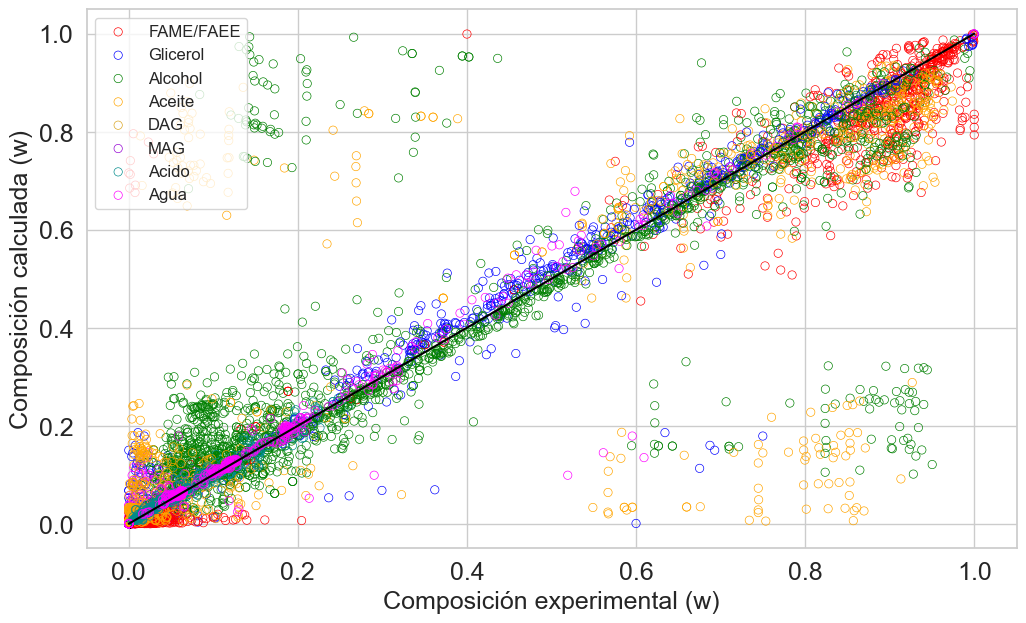

In [108]:
sns.set_theme(rc={'figure.figsize':(12,7)})
sns.set_style("whitegrid")

sns.lineplot(x = [0,1], y=[0,1], color = "black")
sns.scatterplot(x = light_phase[:, 0], y = calculated_light_phase[:, 0], facecolor = "none", edgecolor = "red", label = "FAME/FAEE")

sns.scatterplot(x = light_phase[:, 1], y = calculated_light_phase[:, 1], facecolor = "none", edgecolor = "blue", label = "Glicerol")

sns.scatterplot(x = light_phase[:, 2], y = calculated_light_phase[:, 2], facecolor = "none", edgecolor = "green", label = "Alcohol")

sns.scatterplot(x = light_phase[:, 3], y = calculated_light_phase[:, 3], facecolor = "none", edgecolor = "orange", label = "Aceite")

sns.scatterplot(x = light_phase[:, 4], y = calculated_light_phase[:, 4], facecolor = "none", edgecolor = "goldenrod", label = "DAG")

sns.scatterplot(x = light_phase[:, 5], y = calculated_light_phase[:, 5], facecolor = "none", edgecolor = "darkviolet", label = "MAG")

sns.scatterplot(x = light_phase[:, 6], y = calculated_light_phase[:, 6], facecolor = "none", edgecolor = "darkcyan", label = "Acido")

sns.scatterplot(x = light_phase[:, 7], y = calculated_light_phase[:, 7], facecolor = "none", edgecolor = "magenta", label = "Agua")

sns.scatterplot(x = heavy_phase[:, 0], y = calculated_heavy_phase[:, 0], facecolor = "none", edgecolor = "red")

sns.scatterplot(x = heavy_phase[:, 1], y = calculated_heavy_phase[:, 1], facecolor = "none", edgecolor = "blue")

sns.scatterplot(x = heavy_phase[:, 2], y = calculated_heavy_phase[:, 2], facecolor = "none", edgecolor = "green")

sns.scatterplot(x = heavy_phase[:, 3], y = calculated_heavy_phase[:, 3], facecolor = "none", edgecolor = "orange")

sns.scatterplot(x = heavy_phase[:, 4], y = calculated_heavy_phase[:, 4], facecolor = "none", edgecolor = "goldenrod")

sns.scatterplot(x = heavy_phase[:, 5], y = calculated_heavy_phase[:, 5], facecolor = "none", edgecolor = "darkviolet")

sns.scatterplot(x = heavy_phase[:, 6], y = calculated_heavy_phase[:, 6], facecolor = "none", edgecolor = "darkcyan")

sns.scatterplot(x = heavy_phase[:, 7], y = calculated_heavy_phase[:, 7], facecolor = "none", edgecolor = "magenta")

plt.xlabel("Composición experimental (w)", fontsize=18)
plt.ylabel("Composición calculada (w)", fontsize=18)
plt.legend(loc = "upper left", fontsize=12)
plt.xticks(fontsize=18)
plt.yticks(fontsize=18)
#plt.title("A", fontsize=30)
plt.savefig(f'Figure_7A.png', 
                dpi=1000, 
                bbox_inches='tight', 
                facecolor='white',
                edgecolor='none')
    
plt.show()


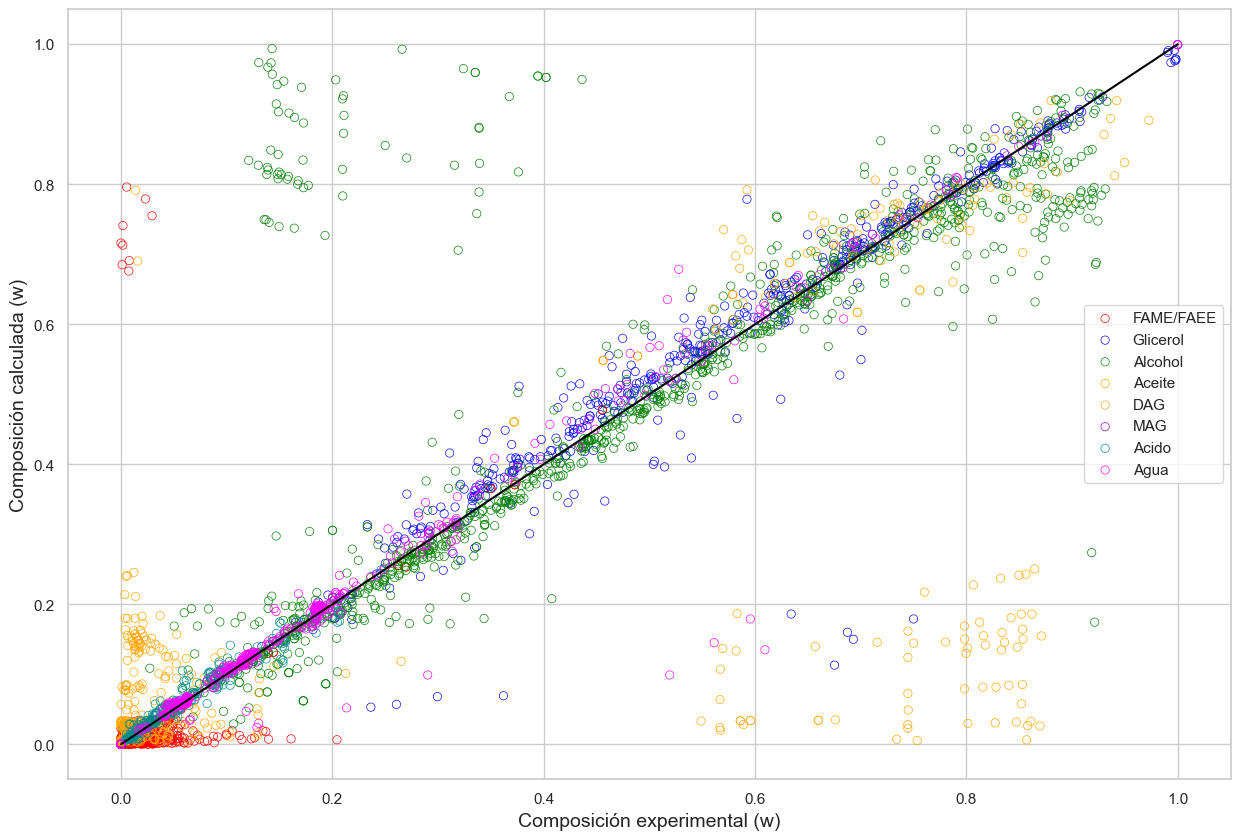

In [182]:
sns.set_theme(rc={'figure.figsize':(15,10)})
sns.set_style("whitegrid")

sns.lineplot(x = [0,1], y=[0,1], color = "black")
sns.scatterplot(x = heavy_phase[:, 0], y = calculated_heavy_phase[:, 0], facecolor = "none", edgecolor = "red", label = "FAME/FAEE")

sns.scatterplot(x = heavy_phase[:, 1], y = calculated_heavy_phase[:, 1], facecolor = "none", edgecolor = "blue", label = "Glicerol")

sns.scatterplot(x = heavy_phase[:, 2], y = calculated_heavy_phase[:, 2], facecolor = "none", edgecolor = "green", label = "Alcohol")

sns.scatterplot(x = heavy_phase[:, 3], y = calculated_heavy_phase[:, 3], facecolor = "none", edgecolor = "orange", label = "Aceite")

sns.scatterplot(x = heavy_phase[:, 4], y = calculated_heavy_phase[:, 4], facecolor = "none", edgecolor = "goldenrod", label = "DAG")

sns.scatterplot(x = heavy_phase[:, 5], y = calculated_heavy_phase[:, 5], facecolor = "none", edgecolor = "darkviolet", label = "MAG")

sns.scatterplot(x = heavy_phase[:, 6], y = calculated_heavy_phase[:, 6], facecolor = "none", edgecolor = "darkcyan", label = "Acido")

sns.scatterplot(x = heavy_phase[:, 7], y = calculated_heavy_phase[:, 7], facecolor = "none", edgecolor = "magenta", label = "Agua")

plt.xlabel("Composición experimental (w)", fontsize=14)
plt.ylabel("Composición calculada (w)", fontsize=14)
plt.show()

In [69]:
predictions = np.vstack((calculated_light_phase, calculated_heavy_phase))
real_data = np.vstack((light_phase, heavy_phase))
residuals = real_data - predictions

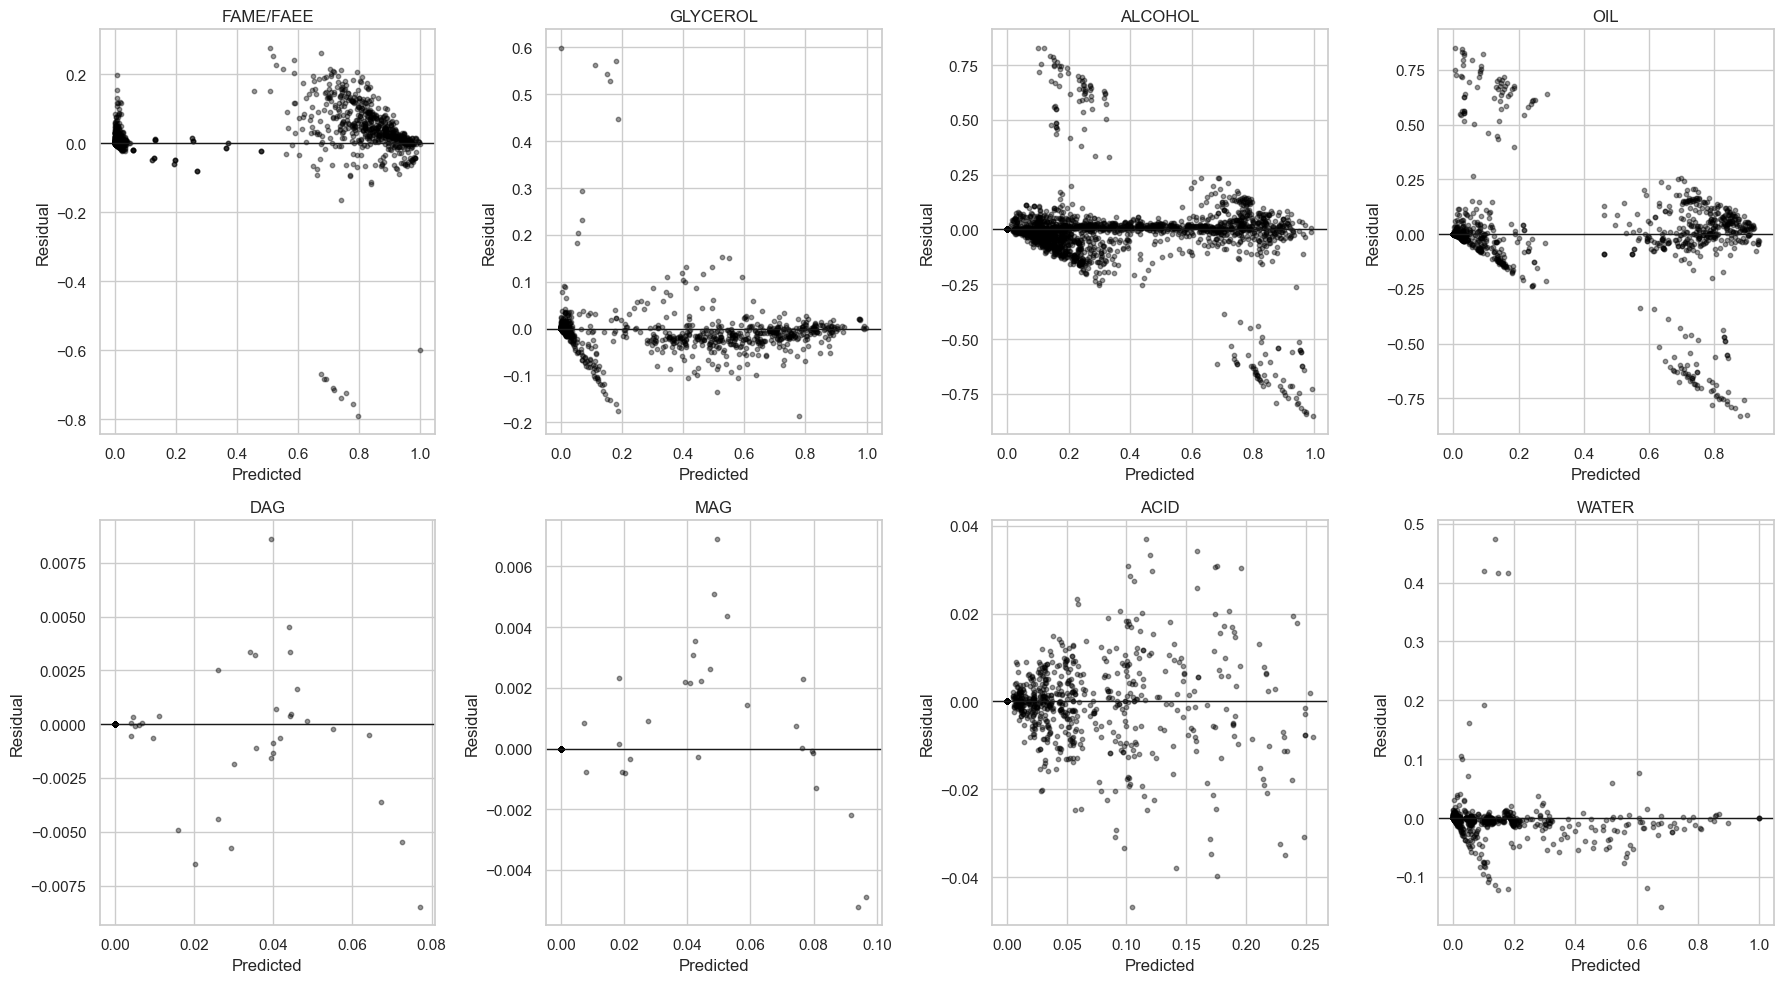

In [74]:
component_names = ['FAME/FAEE', 'GLYCEROL', 'ALCOHOL', 'OIL', 'DAG', 'MAG', 'ACID', 'WATER']
fig, axes = plt.subplots(2, 4, figsize=(18, 10))
axes = axes.ravel()

for j in range(8):
    axes[j].scatter(predictions[:, j], residuals[:, j], alpha=0.4, s=10, color="black")
    axes[j].axhline(0, color="k", lw=1)
    axes[j].set_title(component_names[j])
    axes[j].set_xlabel("Predicted")
    axes[j].set_ylabel("Residual")

plt.tight_layout()
plt.show()

In [183]:
k_columns = [
    'K_FAME/FAEE',
    'K_GLYCEROL',
    'K_ALCOHOL',
    'K_OIL',
    'K_DAG',
    'K_MAG', 
    'K_ACID',
    'K_WATER'
]

if isinstance(result, pl.DataFrame):
    pdf = result.to_pandas()
else:
    pdf = result  # Assume it's already pandas

In [184]:
new_columns = ["FAME/FAEE", "Glicerol", "Alcohol", "Aceite", "DAG", "MAG", "FA", "Agua"]

In [186]:
import pandas as pd

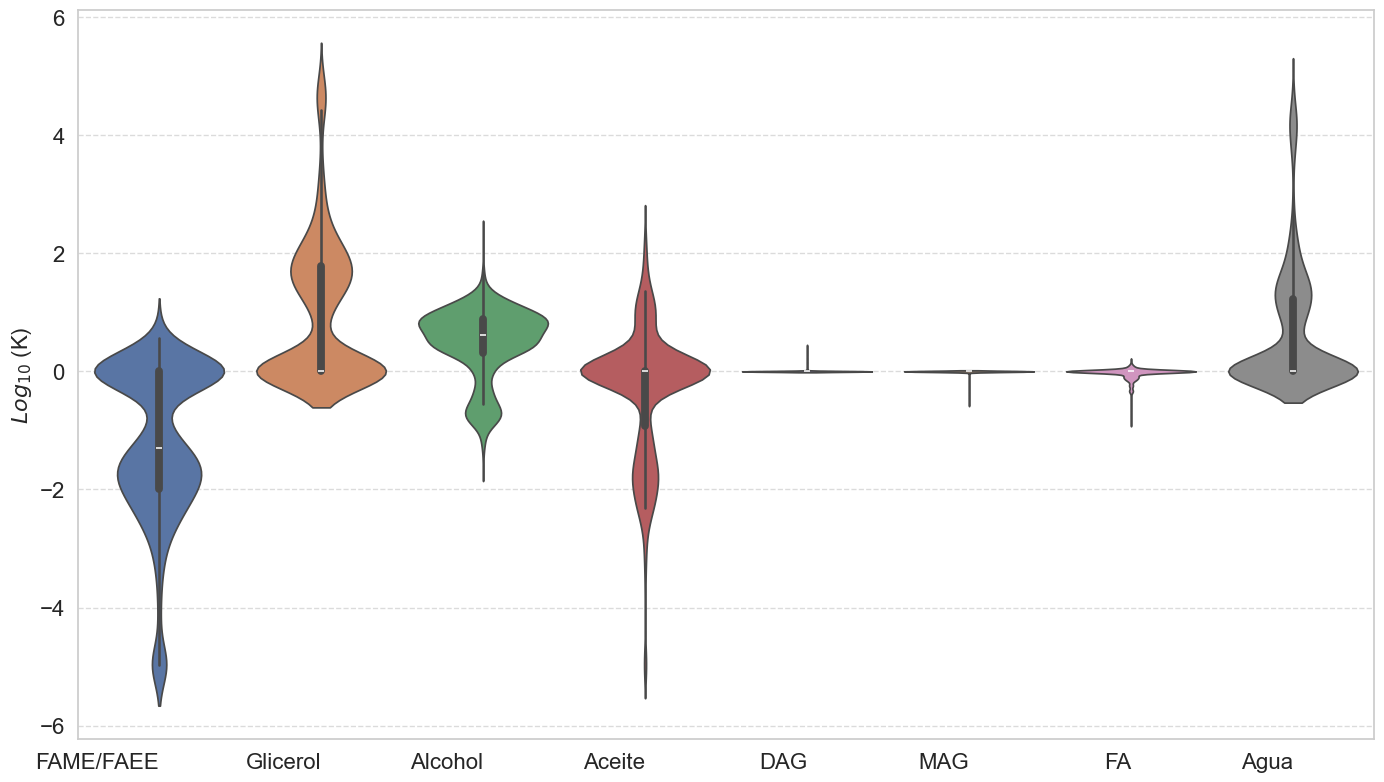

In [187]:
sns.set_style("whitegrid")
k_values_melted = pd.melt(pdf[k_columns], var_name='K Parameter', value_name='Value')

plt.figure(figsize=(14, 8))
sns.violinplot(hue='K Parameter', x = "K Parameter", y='Value', data=k_values_melted, legend=False)
plt.xticks(ticks=range(len(k_columns)), labels=new_columns, ha='right', fontsize=16)
plt.yticks(fontsize=16)
plt.ylabel("$Log_{10}$ (K)", fontsize=16)
plt.xlabel("")
plt.tight_layout()
plt.grid(axis='y', linestyle='--', alpha=0.7)

# Handle outliers for the combined plot
q1, q3 = np.percentile(k_values_melted['Value'].dropna(), [25, 75])
iqr = q3 - q1
upper_limit = q3 + 1.5 * iqr
#plt.ylim(0, min(k_values_melted['Value'].max(), upper_limit*1.5))

#plt.ylim(0, 30)

#plt.savefig('k_values_combined_violin.png', dpi=300, bbox_inches='tight')
plt.savefig(f'Figure_5.png', 
                dpi=1000, 
                bbox_inches='tight', 
                facecolor='white',
                edgecolor='none')
plt.show()



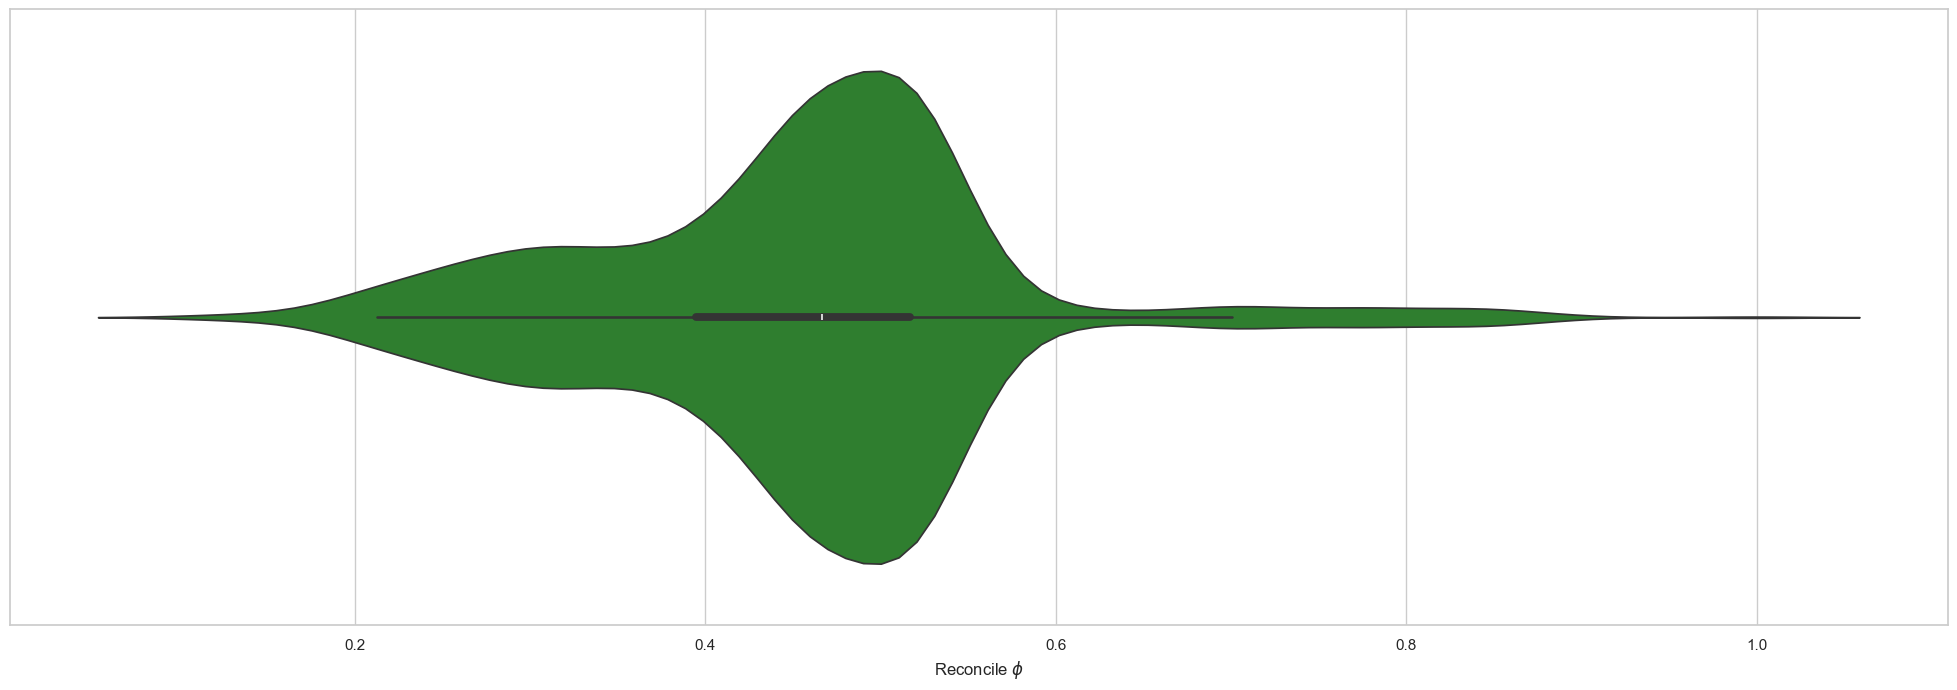

In [108]:
sns.violinplot(data=result,  x="Reconcile phi", color="forestgreen").set(xlabel="Reconcile $\phi$")
plt.show()

In [109]:
k_values_melted.groupby("K Parameter").agg(["mean","median", "std", "min", "max"])

Value                                          
                 mean    median       std        min        max
K Parameter                                                    
K_ACID       0.078609  0.000000  0.233628  -0.391171   2.023775
K_ALCOHOL   -1.103898 -1.430295  1.367583  -5.194970   3.593038
K_DAG       -0.007563  0.000000  0.067665  -1.003187   0.000000
K_FAME/FAEE  2.811167  2.995562  3.075707  -1.311559  11.498690
K_GLYCEROL  -2.296906  0.000000  2.805634 -11.414637   0.000000
K_MAG        0.009658  0.000000  0.087241   0.000000   1.311117
K_OIL        0.778108  0.000000  2.515393  -5.226906  11.486754
K_WATER     -1.532178  0.000000  2.435862 -10.997593   0.000000

In [110]:
K_FAME_df  = result.drop(["Ref", "Sub Ref"]).to_pandas()
K_FAME_corr = K_FAME_df.corr()[["K_FAME/FAEE"]]


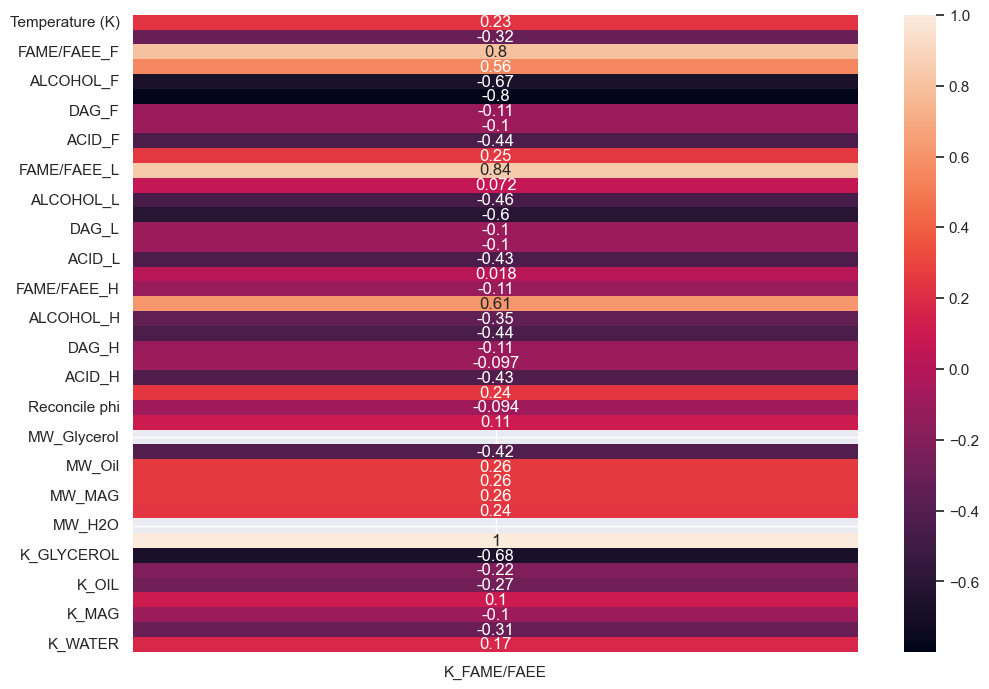

In [111]:
sns.set_theme(rc={'figure.figsize':(11.7,8.27)})
sns.heatmap(K_FAME_corr, annot=True)
plt.show()

In [112]:
K_OIL_df  = result.drop(["Ref", "Sub Ref"]).to_pandas()
K_OIL_corr = K_OIL_df.corr()[["K_OIL"]]



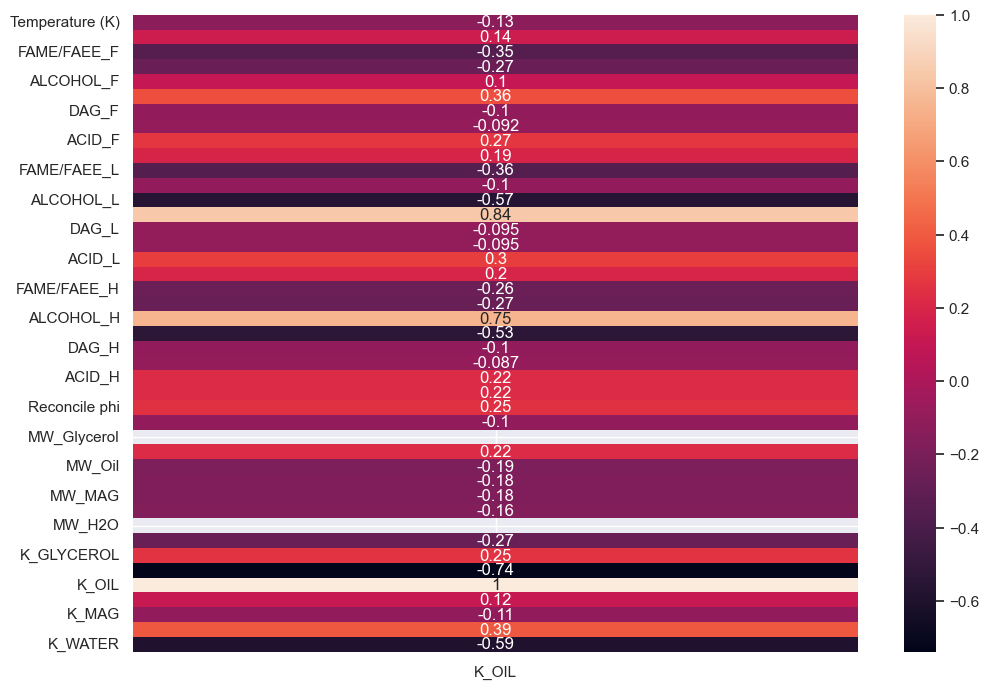

In [113]:
sns.set_theme(rc={'figure.figsize':(11.7,8.27)})
sns.heatmap(K_OIL_corr, annot=True)
plt.show()

In [114]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline
from sklearn.metrics import r2_score, root_mean_squared_error

In [115]:
X = K_FAME_df[["Temperature (K)", "FAME/FAEE_F", "GLYCEROL_F", "ALCOHOL_F"]].to_numpy()
y = K_FAME_df[["K_FAME/FAEE"]].to_numpy()

In [116]:
degree = 2
model = make_pipeline(PolynomialFeatures(degree), LinearRegression())
model.fit(X, y)


Pipeline(steps=[('polynomialfeatures', PolynomialFeatures()),
                ('linearregression', LinearRegression())])

In [117]:
y_pred_train = model.predict(X)
r2 = r2_score(y, y_pred_train)
rmse = root_mean_squared_error(y, y_pred_train)
RE = np.mean(abs((y_pred_train - y)/y*100))
print(f"R²: {r2:.4f}", f"RMSE: {rmse:.4f}")

R²: 0.7309 RMSE: 1.5947


C:\Users\USER\AppData\Local\Temp\ipykernel_42184\3098038206.py:4: RuntimeWarning: divide by zero encountered in divide
  RE = np.mean(abs((y_pred_train - y)/y*100))


In [118]:
np.mean(np.abs((y - y_pred_train)/y * 100))

C:\Users\USER\AppData\Local\Temp\ipykernel_42184\804060054.py:1: RuntimeWarning: divide by zero encountered in divide
  np.mean(np.abs((y - y_pred_train)/y * 100))


inf

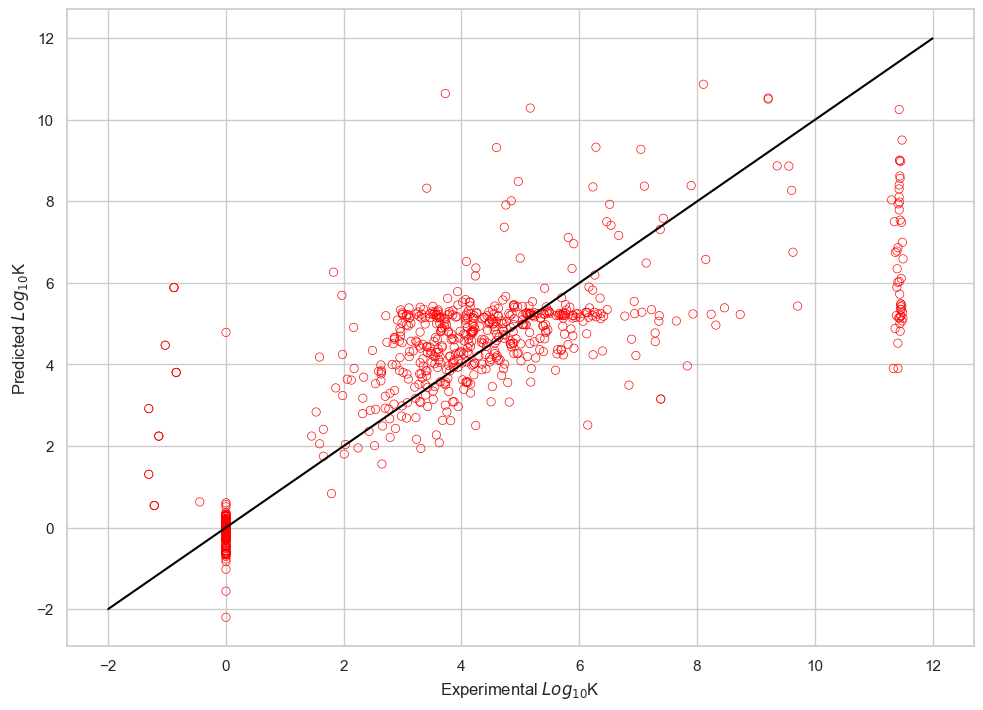

In [119]:
sns.set_style("whitegrid")
sns.scatterplot(x = y.reshape(y.shape[0]), y = y_pred_train.reshape(y_pred_train.shape[0]), facecolor="none", edgecolor="red")
sns.lineplot(x = [-2, 12], y = [-2, 12], color = "black")

plt.ylabel("Predicted $Log_{10}$K")
plt.xlabel("Experimental $Log_{10}$K")
plt.show()

In [120]:
X = K_OIL_df[["Temperature (K)","FAME/FAEE_F", "OIL_F", "ACID_F", "WATER_F", "ALCOHOL_F"]].to_numpy()
y = K_OIL_df[["K_OIL"]].to_numpy()

In [121]:
degree = 4
model = make_pipeline(PolynomialFeatures(degree), LinearRegression())
model.fit(X, y)

Pipeline(steps=[('polynomialfeatures', PolynomialFeatures(degree=4)),
                ('linearregression', LinearRegression())])

In [122]:
y_pred_train = model.predict(X)
r2 = r2_score(y, y_pred_train)
rmse = root_mean_squared_error(y, y_pred_train)
print(f"R²: {r2:.4f}", f"RMSE: {rmse:.4f}")

R²: 0.9272 RMSE: 0.6783


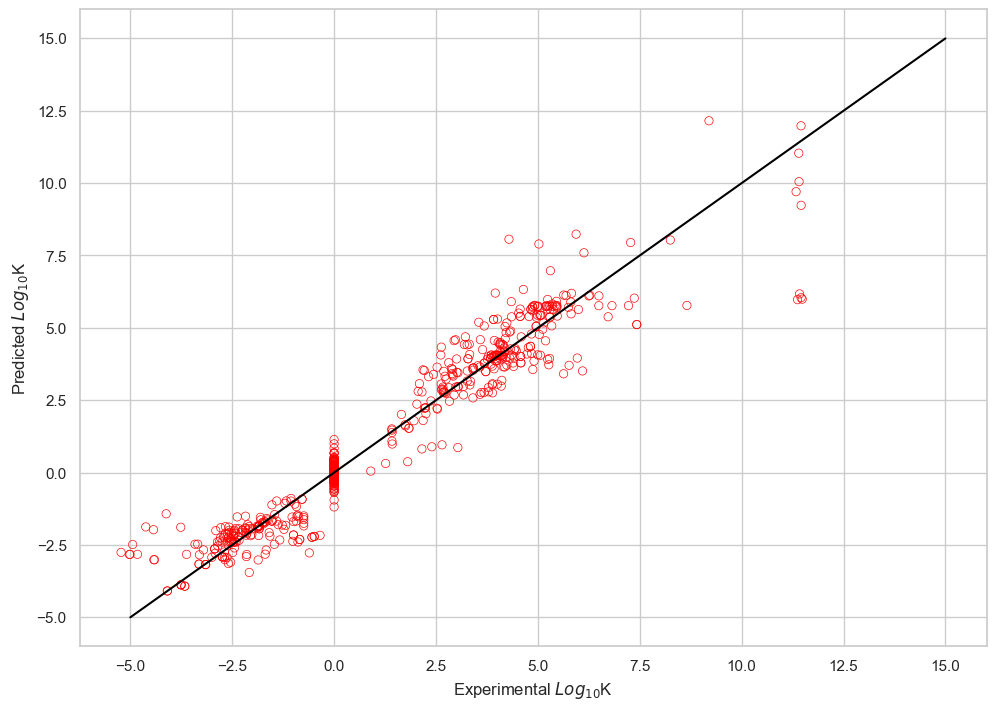

In [123]:
sns.scatterplot(x = y.reshape(y.shape[0]), y = y_pred_train.reshape(y_pred_train.shape[0]), facecolor="none", edgecolor="red")
sns.lineplot(x = [-5, 15], y = [-5, 15], color = "black")
plt.ylabel("Predicted $Log_{10}$K")
plt.xlabel("Experimental $Log_{10}$K")
plt.show()

In [124]:
joined_types_pd = joined_types.to_pandas()

In [125]:
joined_types_pd_oils = joined_types_pd[(joined_types_pd["Source"]=="Palm") | (joined_types_pd["Source"]=="Cottonseed") | (joined_types_pd["Source"]=="Corn") | (joined_types_pd["Source"]=="Soybean")]

In [126]:
joined_types_pd_oils = joined_types_pd_oils.drop(["Ref", "Sub Ref", "MAG/DAG Profile?", "Additional FAME Profile?", "Acid mix Profile?", "Source"], axis=1)


In [127]:
joined_types_pd_oils_corr = joined_types_pd_oils.corr()

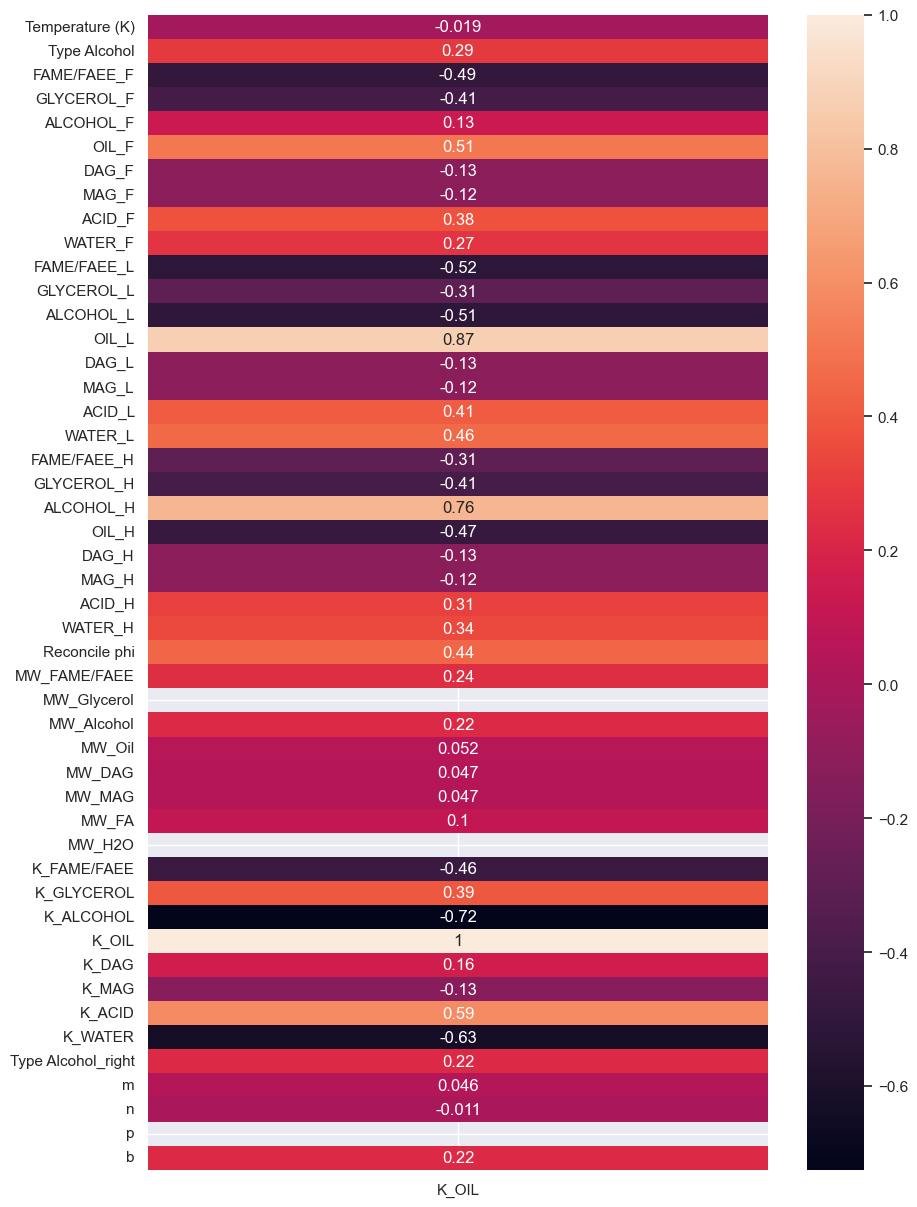

In [128]:
sns.set_theme(rc={'figure.figsize':(10, 15)})
sns.heatmap(joined_types_pd_oils_corr[["K_OIL"]], annot=True)
plt.show()

In [129]:
X = joined_types_pd_oils[["Temperature (K)","FAME/FAEE_F", "OIL_F", "ACID_F", "WATER_F"]].to_numpy()
y = joined_types_pd_oils[["K_OIL"]].to_numpy()

In [130]:
degree = 4
model = make_pipeline(PolynomialFeatures(degree), LinearRegression())
model.fit(X, y)

Pipeline(steps=[('polynomialfeatures', PolynomialFeatures(degree=4)),
                ('linearregression', LinearRegression())])

In [131]:
y_pred_train = model.predict(X)
r2 = r2_score(y, y_pred_train)
rmse = root_mean_squared_error(y, y_pred_train)
print(f"R²: {r2:.4f}", f"RMSE: {rmse:.4f}")

R²: 0.9578 RMSE: 0.5516


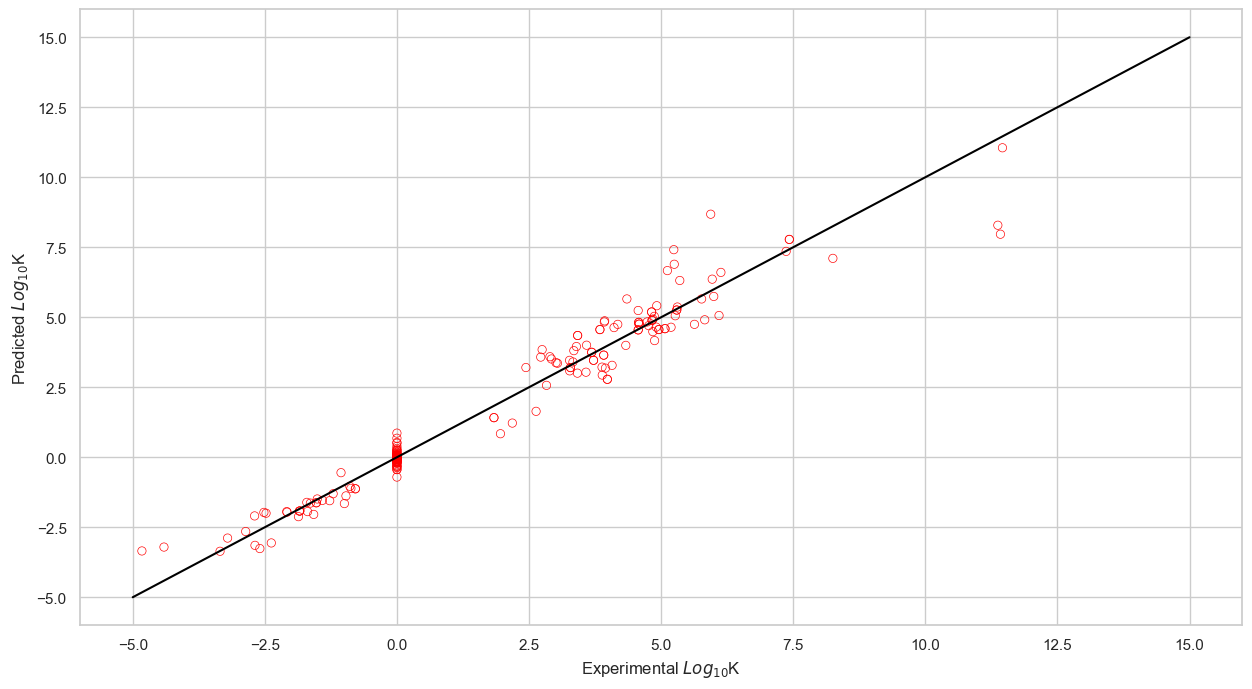

In [149]:
sns.set_theme(rc={'figure.figsize':(15,8)})
sns.set_style("whitegrid")
sns.scatterplot(x = y.reshape(y.shape[0]), y = y_pred_train.reshape(y_pred_train.shape[0]), facecolor="none", edgecolor="red")
sns.lineplot(x = [-5, 15], y = [-5, 15], color = "black")
plt.ylabel("Predicted $Log_{10}$K")
plt.xlabel("Experimental $Log_{10}$K")
plt.show()

#### Othmer-Tobias

#####  Raw Othmer-Tobias

In [76]:
raw_data = pd.read_excel(r'C:\Juan\maestria\ThermOleo\ExperimentalData\data\raw_lle_data.xlsx')

In [77]:
raw_data = raw_data.drop(['Unnamed: 28',
       'Unnamed: 29', 'Unnamed: 30', 'Unnamed: 31', 'Unnamed: 32',
       'Unnamed: 33', 'Unnamed: 34', 'Unnamed: 35', 'Unnamed: 36',
       'Unnamed: 37', 'Unnamed: 38', 'Unnamed: 39', 'Unnamed: 40',
       'Unnamed: 41', 'Unnamed: 42', 'Unnamed: 43'], axis =1)

In [78]:
# Assuming your columns are in order: 8 feed, 8 light, 8 heavy
# Adjust these if your column names are different
feed_cols = raw_data.columns[4:12].tolist()
light_cols = raw_data.columns[12:20].tolist()
heavy_cols = raw_data.columns[20:28].tolist()

print("Feed columns:", feed_cols)
print("Light columns:", light_cols)
print("Heavy columns:", heavy_cols)

Feed columns: ['FAME/FAEE_F', 'GLYCEROL_F', 'ALCOHOL_F', 'OIL_F', 'DAG_F', 'MAG_F', 'ACID_F', 'WATER_F']
Light columns: ['FAME/FAEE_L', 'GLYCEROL_L', 'ALCOHOL_L', 'OIL_L', 'DAG_L', 'MAG_L', 'ACID_L', 'WATER_L']
Heavy columns: ['FAME/FAEE_H', 'GLYCEROL_H', 'ALCOHOL_H', 'OIL_H', 'DAG_H', 'MAG_H', 'ACID_H', 'WATER_H']


In [79]:
# Set tolerance for what counts as "zero"
tolerance = 1e-6

# For each row, count how many components are present
ternary_mask = []
component_indices = []

for idx, row in raw_data.iterrows():
    # Get compositions for all 8 components across all 3 phases
    feed_comps = row[feed_cols].values
    light_comps = row[light_cols].values
    heavy_comps = row[heavy_cols].values
    
    # For each component, check if it's present (>tolerance) in ANY phase
    components_present = []
    for i in range(8):
        if (feed_comps[i] > tolerance or 
            light_comps[i] > tolerance or 
            heavy_comps[i] > tolerance):
            components_present.append(i)
    
    # Keep this tie-line if exactly 3 components are present
    if len(components_present) == 3:
        ternary_mask.append(True)
        component_indices.append(components_present)
    else:
        ternary_mask.append(False)
        component_indices.append(None)

print(f"Total tie-lines: {len(raw_data)}")
print(f"Ternary systems: {sum(ternary_mask)}")
print(f"Quaternary or higher: {len(raw_data) - sum(ternary_mask)}")

Total tie-lines: 1467
Ternary systems: 895
Quaternary or higher: 572


In [80]:
# Create filtered DataFrame with only ternary systems
df_ternary = raw_data[ternary_mask].copy()

print(f"Filtered DataFrame shape: {df_ternary.shape}")

Filtered DataFrame shape: (895, 28)


In [81]:
# Specify which component indices to use
# Adjust these based on your system!
solvent_idx = 0  # Component index for solvent (0-7)
solute_idx = 2   # Component index for solute (0-7)

print(f"Using component {solvent_idx} as solvent (in light phase)")
print(f"Using component {solute_idx} as solute (in heavy phase)")

Using component 0 as solvent (in light phase)
Using component 2 as solute (in heavy phase)


In [82]:
# Let's see the Ref and Sub ref columns
print("Unique experiments:")
print(df_ternary.groupby(['Ref', 'Sub Ref']).size())
print(f"\nTotal unique experiments: {df_ternary.groupby(['Ref', 'Sub Ref']).ngroups}")

Unique experiments:
Ref  Sub Ref
1    a           7
2    a          18
3    a          18
4    a          15
5    a          15
                ..
55   ca          2
56   a          15
     b          15
     c          15
57   a          13
Length: 83, dtype: int64

Total unique experiments: 83


In [83]:
from scipy import stats
import numpy as np

tolerance = 1e-6

def calculate_othmer_tobias_per_experiment(group_df, feed_cols, light_cols, heavy_cols):
    """
    Calculate Othmer-Tobias R², a, and b for a single experiment
    (group of tie-lines with same Ref and Sub ref)
    """
    # Identify which 3 components are present in this ternary system
    first_row = group_df.iloc[0]
    
    feed_comps = first_row[feed_cols].values
    light_comps = first_row[light_cols].values
    heavy_comps = first_row[heavy_cols].values
    
    components_present = []
    for i in range(8):
        if (feed_comps[i] > tolerance or 
            light_comps[i] > tolerance or 
            heavy_comps[i] > tolerance):
            components_present.append(i)
    
    if len(components_present) != 3:
        return np.nan, np.nan, np.nan, None, None
    
    # Identify solvent (enriched in light phase) and solute (enriched in heavy phase)
    light_avg = []
    heavy_avg = []
    
    for comp_idx in components_present:
        light_avg.append(group_df[light_cols[comp_idx]].mean())
        heavy_avg.append(group_df[heavy_cols[comp_idx]].mean())
    
    solvent_idx = components_present[np.argmax(light_avg)]
    solute_idx = components_present[np.argmax(heavy_avg)]
    
    # Extract mass fractions for all tie-lines in this experiment
    w1_II = group_df[light_cols[solvent_idx]].values
    w3_I = group_df[heavy_cols[solute_idx]].values
    
    # Filter valid values (avoid log of 0 or 1)
    valid_mask = (w1_II > 0) & (w1_II < 1) & (w3_I > 0) & (w3_I < 1)
    
    if sum(valid_mask) < 2:  # Need at least 2 points for regression
        return np.nan, np.nan, np.nan, solvent_idx, solute_idx
    
    w1_II_valid = w1_II[valid_mask]
    w3_I_valid = w3_I[valid_mask]
    
    # Calculate Othmer-Tobias terms
    # X = ln[(1 - w3_I) / w3_I]
    # Y = ln[(1 - w1_II) / w1_II]
    X = np.log((1 - w3_I_valid) / w3_I_valid)
    Y = np.log((1 - w1_II_valid) / w1_II_valid)
    
    # Linear regression
    slope, intercept, r_value, p_value, std_err = stats.linregress(X, Y)
    r_squared = r_value**2
    
    return r_squared, intercept, slope, solvent_idx, solute_idx

# Calculate for each experiment
experiment_results = {}

for (ref, sub_ref), group in df_ternary.groupby(['Ref', 'Sub Ref']):
    r2, a, b, solv_idx, solu_idx = calculate_othmer_tobias_per_experiment(
        group, feed_cols, light_cols, heavy_cols
    )
    
    experiment_results[(ref, sub_ref)] = {
        'R2': r2,
        'a': a,
        'b': b,
        'solvent_idx': solv_idx,
        'solute_idx': solu_idx,
        'n_tielines': len(group)
    }
    
    print(f"Ref: {ref}, Sub ref: {sub_ref} | Tie-lines: {len(group)} | R² = {r2:.6f}")

Ref: 1, Sub ref: a | Tie-lines: 7 | R² = 0.980809
Ref: 2, Sub ref: a | Tie-lines: 18 | R² = 0.943429
Ref: 3, Sub ref: a | Tie-lines: 18 | R² = 0.880267
Ref: 4, Sub ref: a | Tie-lines: 15 | R² = 0.673532
Ref: 5, Sub ref: a | Tie-lines: 15 | R² = 0.642988
Ref: 6, Sub ref: a | Tie-lines: 15 | R² = 0.948445
Ref: 7, Sub ref: a | Tie-lines: 18 | R² = 0.825334
Ref: 8, Sub ref: a | Tie-lines: 19 | R² = 0.952418
Ref: 9, Sub ref: a | Tie-lines: 9 | R² = 0.918304
Ref: 10, Sub ref: a | Tie-lines: 10 | R² = 0.922952
Ref: 10, Sub ref: b | Tie-lines: 12 | R² = 0.937276
Ref: 11, Sub ref: a | Tie-lines: 11 | R² = 0.956457
Ref: 12, Sub ref: a | Tie-lines: 12 | R² = 0.958128
Ref: 12, Sub ref: b | Tie-lines: 11 | R² = 0.982530
Ref: 12, Sub ref: c | Tie-lines: 11 | R² = 0.936400
Ref: 12, Sub ref: d | Tie-lines: 10 | R² = 0.966865
Ref: 13, Sub ref: a | Tie-lines: 6 | R² = 0.995865
Ref: 14, Sub ref: a | Tie-lines: 15 | R² = 0.446936
Ref: 15, Sub ref: a | Tie-lines: 5 | R² = 0.983663
Ref: 16, Sub ref: a | Tie

In [84]:
# Map results back to each row
r2_values = []
a_values = []
b_values = []

for idx, row in df_ternary.iterrows():
    ref = row['Ref']
    sub_ref = row['Sub Ref']
    
    result = experiment_results[(ref, sub_ref)]
    
    r2_values.append(result['R2'])
    a_values.append(result['a'])
    b_values.append(result['b'])

df_ternary['R2_othmer_tobias'] = r2_values
df_ternary['a_othmer_tobias'] = a_values
df_ternary['b_othmer_tobias'] = b_values

print("\n" + "="*70)
print("OTHMER-TOBIAS PARAMETERS ADDED TO df_ternary")
print("="*70)
print(f"Columns added: R2_othmer_tobias, a_othmer_tobias, b_othmer_tobias")
print(f"\nDataFrame shape: {df_ternary.shape}")
print("\nSample rows:")
print(df_ternary[['Ref', 'Sub Ref', 'R2_othmer_tobias', 'a_othmer_tobias', 'b_othmer_tobias']].head(15))


OTHMER-TOBIAS PARAMETERS ADDED TO df_ternary
Columns added: R2_othmer_tobias, a_othmer_tobias, b_othmer_tobias

DataFrame shape: (895, 31)

Sample rows:
    Ref Sub Ref  R2_othmer_tobias  a_othmer_tobias  b_othmer_tobias
0     1       a          0.980809        -0.938020         1.190715
1     1       a          0.980809        -0.938020         1.190715
2     1       a          0.980809        -0.938020         1.190715
3     1       a          0.980809        -0.938020         1.190715
4     1       a          0.980809        -0.938020         1.190715
5     1       a          0.980809        -0.938020         1.190715
6     1       a          0.980809        -0.938020         1.190715
7     2       a          0.943429        -1.361375         0.556871
8     2       a          0.943429        -1.361375         0.556871
9     2       a          0.943429        -1.361375         0.556871
10    2       a          0.943429        -1.361375         0.556871
11    2       a          0.943

In [104]:
results = df_ternary.groupby(['Ref', 'Sub Ref'])['R2_othmer_tobias'].mean().reset_index()

In [107]:
results[results['R2_othmer_tobias'] >=0.90].shape

(43, 3)

In [108]:
results.shape

(83, 3)

In [110]:
df_ternary.to_csv('raw_data_othmer_tobias.csv')

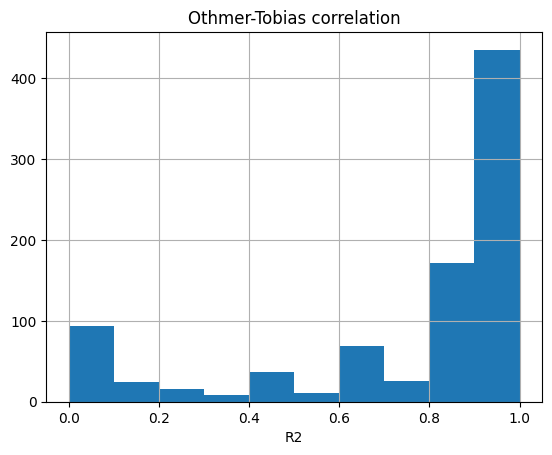

In [115]:
df_ternary['R2_othmer_tobias'].hist()
plt.title('Othmer-Tobias correlation')
plt.xlabel('R2')
plt.show()

#####  Refined Othmer-Tobias

In [86]:
refined_data = pd.read_excel(r'C:\Juan\maestria\ThermOleo\ExperimentalData\data\No 47exp\refined_lle_data_v5.xlsx')


In [87]:
# Assuming your columns are in order: 8 feed, 8 light, 8 heavy
# Adjust these if your column names are different
feed_cols = refined_data.columns[4:12].tolist()
light_cols = refined_data.columns[12:20].tolist()
heavy_cols = refined_data.columns[20:28].tolist()

print("Feed columns:", feed_cols)
print("Light columns:", light_cols)
print("Heavy columns:", heavy_cols)

Feed columns: ['FAME/FAEE_F', 'GLYCEROL_F', 'ALCOHOL_F', 'OIL_F', 'DAG_F', 'MAG_F', 'ACID_F', 'WATER_F']
Light columns: ['FAME/FAEE_L', 'GLYCEROL_L', 'ALCOHOL_L', 'OIL_L', 'DAG_L', 'MAG_L', 'ACID_L', 'WATER_L']
Heavy columns: ['FAME/FAEE_H', 'GLYCEROL_H', 'ALCOHOL_H', 'OIL_H', 'DAG_H', 'MAG_H', 'ACID_H', 'WATER_H']


In [88]:
# Set tolerance for what counts as "zero"
tolerance = 1e-6

# For each row, count how many components are present
ternary_mask = []
component_indices = []

for idx, row in refined_data.iterrows():
    # Get compositions for all 8 components across all 3 phases
    feed_comps = row[feed_cols].values
    light_comps = row[light_cols].values
    heavy_comps = row[heavy_cols].values
    
    # For each component, check if it's present (>tolerance) in ANY phase
    components_present = []
    for i in range(8):
        if (feed_comps[i] > tolerance or 
            light_comps[i] > tolerance or 
            heavy_comps[i] > tolerance):
            components_present.append(i)
    
    # Keep this tie-line if exactly 3 components are present
    if len(components_present) == 3:
        ternary_mask.append(True)
        component_indices.append(components_present)
    else:
        ternary_mask.append(False)
        component_indices.append(None)

print(f"Total tie-lines: {len(refined_data)}")
print(f"Ternary systems: {sum(ternary_mask)}")
print(f"Quaternary or higher: {len(refined_data) - sum(ternary_mask)}")

Total tie-lines: 1027
Ternary systems: 719
Quaternary or higher: 308


In [90]:
# Create filtered DataFrame with only ternary systems
df_ternary_refined = refined_data[ternary_mask].copy()

print(f"Filtered DataFrame shape: {df_ternary_refined.shape}")

Filtered DataFrame shape: (719, 29)


In [91]:
# Specify which component indices to use
# Adjust these based on your system!
solvent_idx = 0  # Component index for solvent (0-7)
solute_idx = 2   # Component index for solute (0-7)

print(f"Using component {solvent_idx} as solvent (in light phase)")
print(f"Using component {solute_idx} as solute (in heavy phase)")

Using component 0 as solvent (in light phase)
Using component 2 as solute (in heavy phase)


In [92]:
# Let's see the Ref and Sub ref columns
print("Unique experiments:")
print(df_ternary_refined.groupby(['Ref', 'Sub Ref']).size())
print(f"\nTotal unique experiments: {df_ternary_refined.groupby(['Ref', 'Sub Ref']).ngroups}")

Unique experiments:
Ref  Sub Ref
1    a           3
2    a          15
3    a          18
4    a          15
5    a          15
                ..
55   ca          1
56   a          15
     b          15
     c          15
57   a          12
Length: 73, dtype: int64

Total unique experiments: 73


In [93]:
def calculate_othmer_tobias_per_experiment(group_df, feed_cols, light_cols, heavy_cols):
    """
    Calculate Othmer-Tobias R², a, and b for a single experiment
    (group of tie-lines with same Ref and Sub ref)
    """
    # Identify which 3 components are present in this ternary system
    first_row = group_df.iloc[0]
    
    feed_comps = first_row[feed_cols].values
    light_comps = first_row[light_cols].values
    heavy_comps = first_row[heavy_cols].values
    
    components_present = []
    for i in range(8):
        if (feed_comps[i] > tolerance or 
            light_comps[i] > tolerance or 
            heavy_comps[i] > tolerance):
            components_present.append(i)
    
    if len(components_present) != 3:
        return np.nan, np.nan, np.nan, None, None
    
    # Identify solvent (enriched in light phase) and solute (enriched in heavy phase)
    light_avg = []
    heavy_avg = []
    
    for comp_idx in components_present:
        light_avg.append(group_df[light_cols[comp_idx]].mean())
        heavy_avg.append(group_df[heavy_cols[comp_idx]].mean())
    
    solvent_idx = components_present[np.argmax(light_avg)]
    solute_idx = components_present[np.argmax(heavy_avg)]
    
    # Extract mass fractions for all tie-lines in this experiment
    w1_II = group_df[light_cols[solvent_idx]].values
    w3_I = group_df[heavy_cols[solute_idx]].values
    
    # Filter valid values (avoid log of 0 or 1)
    valid_mask = (w1_II > 0) & (w1_II < 1) & (w3_I > 0) & (w3_I < 1)
    
    if sum(valid_mask) < 2:  # Need at least 2 points for regression
        return np.nan, np.nan, np.nan, solvent_idx, solute_idx
    
    w1_II_valid = w1_II[valid_mask]
    w3_I_valid = w3_I[valid_mask]
    
    # Calculate Othmer-Tobias terms
    # X = ln[(1 - w3_I) / w3_I]
    # Y = ln[(1 - w1_II) / w1_II]
    X = np.log((1 - w3_I_valid) / w3_I_valid)
    Y = np.log((1 - w1_II_valid) / w1_II_valid)
    
    # Linear regression
    slope, intercept, r_value, p_value, std_err = stats.linregress(X, Y)
    r_squared = r_value**2
    
    return r_squared, intercept, slope, solvent_idx, solute_idx

# Calculate for each experiment
experiment_results = {}

for (ref, sub_ref), group in df_ternary_refined.groupby(['Ref', 'Sub Ref']):
    r2, a, b, solv_idx, solu_idx = calculate_othmer_tobias_per_experiment(
        group, feed_cols, light_cols, heavy_cols
    )
    
    experiment_results[(ref, sub_ref)] = {
        'R2': r2,
        'a': a,
        'b': b,
        'solvent_idx': solv_idx,
        'solute_idx': solu_idx,
        'n_tielines': len(group)
    }
    
    print(f"Ref: {ref}, Sub ref: {sub_ref} | Tie-lines: {len(group)} | R² = {r2:.6f}")

Ref: 1, Sub ref: a | Tie-lines: 3 | R² = 0.919429
Ref: 2, Sub ref: a | Tie-lines: 15 | R² = 0.966919
Ref: 3, Sub ref: a | Tie-lines: 18 | R² = 0.877290
Ref: 4, Sub ref: a | Tie-lines: 15 | R² = 0.665916
Ref: 5, Sub ref: a | Tie-lines: 15 | R² = 0.630218
Ref: 6, Sub ref: a | Tie-lines: 12 | R² = 0.963254
Ref: 7, Sub ref: a | Tie-lines: 15 | R² = 0.787910
Ref: 8, Sub ref: a | Tie-lines: 17 | R² = 0.941940
Ref: 9, Sub ref: a | Tie-lines: 9 | R² = 0.911684
Ref: 10, Sub ref: a | Tie-lines: 10 | R² = 0.923806
Ref: 10, Sub ref: b | Tie-lines: 12 | R² = 0.942070
Ref: 11, Sub ref: a | Tie-lines: 2 | R² = 1.000000
Ref: 12, Sub ref: a | Tie-lines: 9 | R² = 0.940411
Ref: 12, Sub ref: b | Tie-lines: 10 | R² = 0.974456
Ref: 12, Sub ref: c | Tie-lines: 11 | R² = 0.934155
Ref: 12, Sub ref: d | Tie-lines: 10 | R² = 0.964939
Ref: 13, Sub ref: a | Tie-lines: 6 | R² = 0.996488
Ref: 14, Sub ref: a | Tie-lines: 14 | R² = 0.577701
Ref: 15, Sub ref: a | Tie-lines: 5 | R² = 0.984209
Ref: 16, Sub ref: a | Tie-l

In [94]:
# Map results back to each row
r2_values = []
a_values = []
b_values = []

for idx, row in df_ternary_refined.iterrows():
    ref = row['Ref']
    sub_ref = row['Sub Ref']
    
    result = experiment_results[(ref, sub_ref)]
    
    r2_values.append(result['R2'])
    a_values.append(result['a'])
    b_values.append(result['b'])

df_ternary_refined['R2_othmer_tobias'] = r2_values
df_ternary_refined['a_othmer_tobias'] = a_values
df_ternary_refined['b_othmer_tobias'] = b_values

print("\n" + "="*70)
print("OTHMER-TOBIAS PARAMETERS ADDED TO df_ternary_refined")
print("="*70)
print(f"Columns added: R2_othmer_tobias, a_othmer_tobias, b_othmer_tobias")
print(f"\nDataFrame shape: {df_ternary_refined.shape}")
print("\nSample rows:")
print(df_ternary_refined[['Ref', 'Sub Ref', 'R2_othmer_tobias', 'a_othmer_tobias', 'b_othmer_tobias']].head(15))


OTHMER-TOBIAS PARAMETERS ADDED TO df_ternary_refined
Columns added: R2_othmer_tobias, a_othmer_tobias, b_othmer_tobias

DataFrame shape: (719, 32)

Sample rows:
    Ref Sub Ref  R2_othmer_tobias  a_othmer_tobias  b_othmer_tobias
0     1       a          0.919429        -0.732410         1.410035
1     1       a          0.919429        -0.732410         1.410035
2     1       a          0.919429        -0.732410         1.410035
3     2       a          0.966919        -1.296404         0.640679
4     2       a          0.966919        -1.296404         0.640679
5     2       a          0.966919        -1.296404         0.640679
6     2       a          0.966919        -1.296404         0.640679
7     2       a          0.966919        -1.296404         0.640679
8     2       a          0.966919        -1.296404         0.640679
9     2       a          0.966919        -1.296404         0.640679
10    2       a          0.966919        -1.296404         0.640679
11    2       a       

In [96]:
df_ternary_refined.describe()

,Ref,Temperature (K),Type Alcohol,FAME/FAEE_F,GLYCEROL_F,ALCOHOL_F,OIL_F,DAG_F,MAG_F,ACID_F,...,ALCOHOL_H,OIL_H,DAG_H,MAG_H,ACID_H,WATER_H,Reconcile phi,R2_othmer_tobias,a_othmer_tobias,b_othmer_tobias
count,719.000000,719.000000,719.000000,719.000000,719.000000,719.000000,719.000000,719.000000,719.0,719.000000,...,719.000000,719.000000,719.000000,719.0,719.000000,719.000000,719.000000,714.000000,714.000000,714.000000
mean,26.595271,310.726078,1.611961,0.288958,0.220220,0.327225,0.114342,0.000036,0.0,0.007847,...,0.399848,0.125485,0.000046,0.0,0.007219,0.070156,0.433090,0.826962,-1.851479,0.404021
std,16.162787,14.750847,0.588584,0.187368,0.188404,0.148847,0.198790,0.000817,0.0,0.024604,...,0.223457,0.272021,0.001077,0.0,0.023329,0.180656,0.120094,0.222669,1.232355,0.929663
min,1.000000,283.150000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,...,0.000000,0.000000,0.000000,0.0,0.000000,0.000000,0.112267,0.039605,-4.433131,-1.942800
25%,12.000000,298.150000,1.000000,0.189500,0.000000,0.201150,0.000000,0.000000,0.0,0.000000,...,0.210229,0.000000,0.000000,0.0,0.000000,0.000000,0.361957,0.787910,-2.586181,0.502634
50%,26.000000,303.200000,2.000000,0.329100,0.256400,0.336000,0.000000,0.000000,0.0,0.000000,...,0.366000,0.000000,0.000000,0.0,0.000000,0.000000,0.450006,0.923781,-1.786218,0.670487
75%,37.000000,318.175000,2.000000,0.407550,0.390860,0.470400,0.290400,0.000000,0.0,0.000000,...,0.552607,0.000010,0.000000,0.0,0.000000,0.000000,0.493428,0.966919,-1.102410,0.866336
max,57.000000,353.150000,4.000000,0.845900,0.685100,0.618900,0.525600,0.021500,0.0,0.235700,...,0.932883,0.897919,0.028484,0.0,0.246264,0.890911,0.877073,1.000000,2.866317,4.445199


<Axes: >

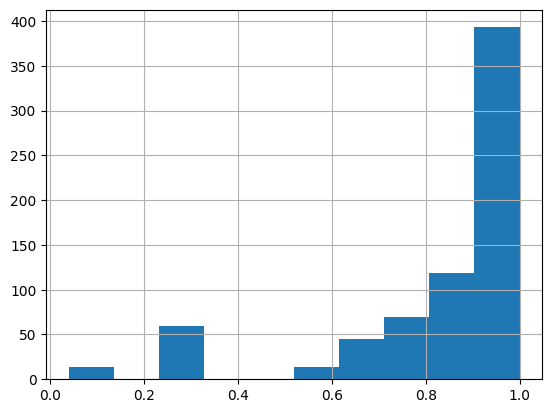

In [97]:
df_ternary_refined['R2_othmer_tobias'].hist()

<Axes: >

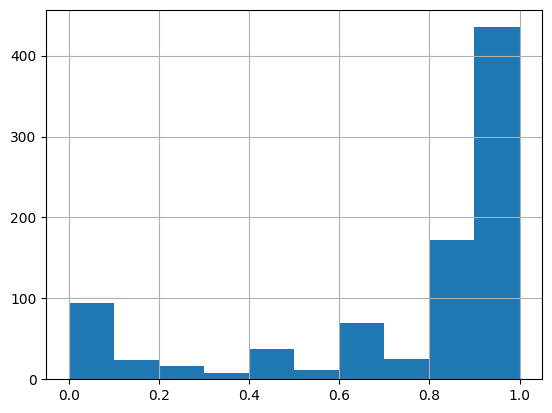

In [98]:
df_ternary['R2_othmer_tobias'].hist()